# FRM Parte I avanzado, libro 3: Mercados y productos financieros

Versión de mayor nivel del libro 3 del programa 2026 de GARP, el de mayor peso en el examen junto con el libro 4. Cubre los 20 capítulos en el orden oficial y complementa los casos de [05_FRM](../05_FRM/03_mercados_y_productos.ipynb). Cada capítulo tiene la idea central, un análisis avanzado con datos reales o simulados, ejercicios resueltos en Python, preguntas de práctica con la respuesta oculta y las trampas frecuentes.

| Código | Capítulo | Análisis avanzado |
|---|---|---|
| FMP-1 | Bancos | Capital de los bancos chilenos frente a Basilea III |
| FMP-2 | Compañías de seguros y fondos de pensiones | Prima de un seguro de vida y pasivos de pensiones ante las tasas |
| FMP-3 | Gestión de fondos | Comisiones con marca de agua y sesgo de supervivencia |
| FMP-4 | Introducción a los derivados | Perfiles de pago y apalancamiento sobre el dólar |
| FMP-5 | Bolsas y mercados OTC | Exposición de un forward con y sin colateral |
| FMP-6 | Compensación central | Márgenes procíclicos y la cascada de incumplimiento |
| FMP-7 | Mercados de futuros | Liquidez en riesgo por llamados de margen |
| FMP-8 | Cobertura con futuros | Cobertura cruzada de bancos con el ETF IPSA |
| FMP-9 | Mercados de divisas | ¿Pronostica el forward el tipo de cambio? |
| FMP-10 | Precio de forwards y futuros financieros | Valor de mercado de un forward vivo |
| FMP-11 | Forwards y futuros de commodities | Reversión a la media del cobre y la curva forward |
| FMP-12 | Mercados de opciones | Warrants y bonos convertibles |
| FMP-13 | Propiedades de las opciones | Detector de arbitraje y frontera de ejercicio anticipado |
| FMP-14 | Estrategias con opciones | Nota con capital protegido y nivel de tasas |
| FMP-15 | Opciones exóticas | Exóticas sobre el dólar con fórmulas cerradas y Monte Carlo |
| FMP-16 | Propiedades de las tasas de interés | Curva cero de la tasa swap cámara por bootstrapping |
| FMP-17 | Bonos corporativos | El enigma del spread de crédito |
| FMP-18 | Hipotecas y MBS | Convexidad negativa y strips IO y PO |
| FMP-19 | Futuros de tasas de interés | El bono más barato de entregar |
| FMP-20 | Swaps | Valor de un swap vivo con la curva chilena |

## Configuración

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

from dsaplicado import datos, frm, frm_avanzado as fa, portafolio as pf
from dsaplicado.graficos import COLORES, NEUTRO, TINTA_SECUNDARIA, TINTA_TENUE, aplicar_estilo, eje_porcentaje, separar_etiquetas

warnings.filterwarnings("ignore", category=FutureWarning)
aplicar_estilo()
pd.set_option("display.float_format", "{:,.4f}".format)
RAIZ = datos.raiz_repositorio()
DATOS = RAIZ / "datos"
FIGURAS = RAIZ / "06_FRM_advance" / "figuras"

precios = datos.cargar_precios(DATOS / "precios_ipsa.csv", {**datos.ACCIONES_IPSA, **datos.BENCHMARK_IPSA},
                               "2019-01-01", "2026-09-01").ffill()
retornos = pf.retornos_simples(precios).dropna()
dolar = datos.cargar_indicador(DATOS / "dolar_historico.csv", "dolar", range(2000, 2027))
cobre = datos.cargar_indicador(DATOS / "libra_cobre_historico.csv", "libra_cobre", range(2012, 2027))
tpm = datos.cargar_indicador(DATOS / "tpm_historico.csv", "tpm", range(2001, 2027))
tpm = tpm.mask(tpm < 0.25).ffill() / 100
swap = pd.read_csv(DATOS / "bcch" / "swap_camara_pesos.csv", index_col="fecha", parse_dates=True)
bcp = pd.read_csv(DATOS / "bcch" / "bcp_mercado_secundario.csv", index_col="fecha", parse_dates=True)
dgs1 = datos.cargar_fred("DGS1", DATOS / "fred") / 100
dtb3 = datos.cargar_fred("DTB3", DATOS / "fred") / 100

spot = float(dolar.iloc[-1])
r_clp, r_usd = float(tpm.iloc[-1]), float(dgs1.iloc[-1])
vol_usd = float(np.log(dolar).diff().loc[dolar.index[-1] - pd.DateOffset(years=2):].std() * np.sqrt(252))
print(f"Dólar {spot:,.2f} ({dolar.index[-1]:%d-%m-%Y}); volatilidad de dos años {vol_usd:.1%}; TPM {r_clp:.2%}; tasa de EE.UU. a un año {r_usd:.2%}")

Dólar 959.39 (24-09-2026); volatilidad de dos años 10.7%; TPM 4.50%; tasa de EE.UU. a un año 4.49%


## FMP-1. Bancos

*Relevancia en el examen: alta. Dificultad: intermedia.*

### Idea central

- **Negocio y riesgos.** Los bancos transforman depósitos de corto plazo en préstamos de largo plazo: asumen riesgo de crédito, de liquidez y de tasa. La banca de inversión agrega colocación de emisiones, fusiones y trading, con conflictos de interés que se manejan con murallas chinas.
- **Capital regulatorio.** CET1 (acciones comunes y utilidades retenidas), capital adicional de nivel 1 y capital de nivel 2. Mínimos de Basilea III sobre activos ponderados por riesgo (APR): 4,5% de CET1, 6% de nivel 1 y 8% total, más un colchón de conservación de 2,5% en CET1, un colchón contracíclico de hasta 2,5% y cargos para bancos sistémicos. Además, un apalancamiento mínimo de 3% del nivel 1 sobre la exposición total, sin ponderar.
- **Liquidez.** La razón de cobertura de liquidez (LCR) exige activos líquidos para 30 días de estrés; la de financiamiento estable neto (NSFR), financiar los activos de largo plazo con fuentes estables.
- **Seguro de depósitos.** Previene corridas, pero crea riesgo moral: los depositantes dejan de vigilar al banco. Por eso se combina con regulación y supervisión.
- **Originar para distribuir.** Vender los créditos que se originan libera capital, pero debilita los incentivos a evaluarlos bien.

### Análisis avanzado: capital de los bancos chilenos frente a Basilea III

La CMF publica para cada banco el patrimonio efectivo sobre activos ponderados por riesgo, equivalente al ratio de capital total, y el capital básico sobre activos totales, cercano al ratio de apalancamiento. Se comparan con el mínimo de 8%, con el 10,5% que incluye el colchón de conservación y con el apalancamiento mínimo de 3%.

Corte: 06-2026. Sistema: capital total 16.9% de los APR; capital básico 8.1% de los activos.
Sistema bancario: de 14.8% en 12-2021 a 16.9% en 06-2026
Bancos bajo 10,5%: 0; bajo 3% de capital básico: 0


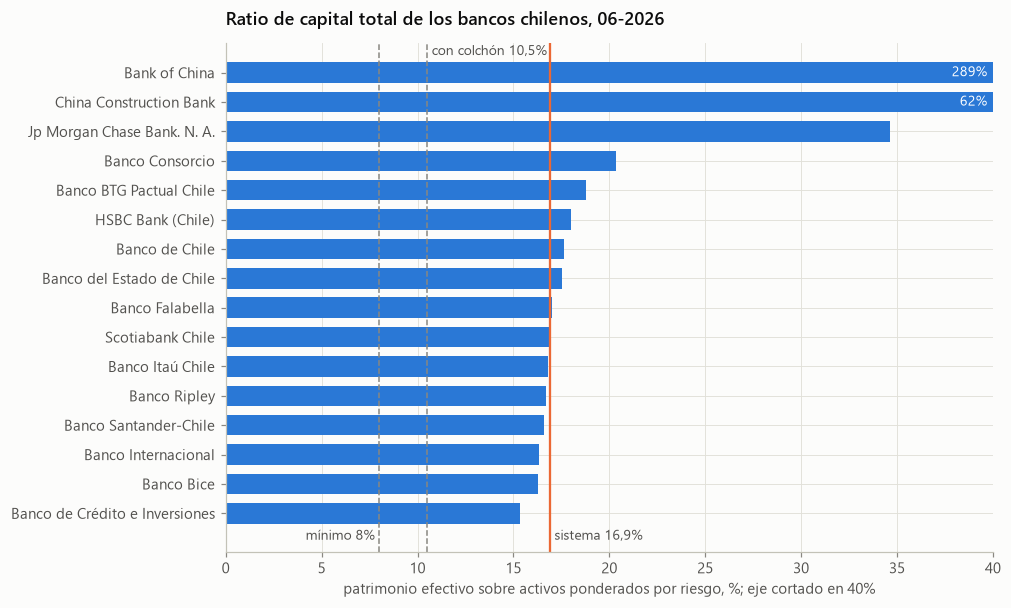

,banco,"capital total / APR, %","capital básico / activos, %"
codigo,,,
BCI,Banco de Crédito e Inversiones,15.3200,8.1000
BICE,Banco Bice,16.2700,8.6100
BINTE,Banco Internacional,16.3200,6.7300
BSANT,Banco Santander-Chile,16.6100,7.2500
BRIPL,Banco Ripley,16.7200,13.6400
BITAUCORP,Banco Itaú Chile,16.8200,6.9600
BSCOT,Scotiabank Chile,16.8900,8.6700
BFALA,Banco Falabella,17.0000,12.9700
BECH,Banco del Estado de Chile,17.5200,6.3500


In [2]:
def leer_cmf(patron):
    tabla = pd.read_csv(next((DATOS / "cmf").glob(patron)))
    tabla["fecha"] = pd.to_datetime(tabla["fecha"])
    tabla["codigo"] = tabla["codigo_serie"].str.extract(r"AGIFI_([A-Z0-9]+)_STO")[0]
    tabla["nombre"] = tabla["nombre"].str.replace("\xa0", " ").str.strip()
    return tabla

capital = leer_cmf("*PATEFE_APR*")
apalancamiento = leer_cmf("*CAPBAS_ATR*")
corte = capital["fecha"].max()
ultimo = capital[capital["fecha"] == corte].set_index("codigo")
ultimo_apal = apalancamiento[apalancamiento["fecha"] == corte].set_index("codigo")["valor"]
tabla_capital = pd.DataFrame({"banco": ultimo["nombre"], "capital total / APR, %": ultimo["valor"],
                              "capital básico / activos, %": ultimo_apal}).sort_values("capital total / APR, %")
sistema = tabla_capital.loc["SISTBANC"]
bancos_cap = tabla_capital.drop(index="SISTBANC")
historia = capital[capital["codigo"] == "SISTBANC"].set_index("fecha")["valor"]
print(f"Corte: {corte:%m-%Y}. Sistema: capital total {sistema.iloc[1]:.1f}% de los APR; capital básico {sistema.iloc[2]:.1f}% de los activos.")
print(f"Sistema bancario: de {historia.iloc[0]:.1f}% en {historia.index[0]:%m-%Y} a {historia.iloc[-1]:.1f}% en {historia.index[-1]:%m-%Y}")
print(f"Bancos bajo 10,5%: {(bancos_cap['capital total / APR, %'] < 10.5).sum()}; bajo 3% de capital básico: {(bancos_cap['capital básico / activos, %'] < 3).sum()}")

limite = 40
fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(bancos_cap))
valores = bancos_cap["capital total / APR, %"]
ax.barh(y, valores.clip(upper=limite), color=COLORES[0], height=0.7)
for yi, v in zip(y, valores):
    if v > limite:
        ax.annotate(f"{v:.0f}%", (limite, yi), xytext=(-4, 0), textcoords="offset points", ha="right", va="center", color="white", fontsize=9)
for x_ref, texto, y_txt, dx, alineacion in [(8, "mínimo 8%", -0.9, -3, "right"), (10.5, "con colchón 10,5%", len(y) - 0.4, 3, "left")]:
    ax.axvline(x_ref, color=TINTA_TENUE, linestyle="--", linewidth=1)
    ax.annotate(texto, (x_ref, y_txt), xytext=(dx, 0), textcoords="offset points", ha=alineacion, color=TINTA_SECUNDARIA, fontsize=9)
ax.axvline(sistema.iloc[1], color=COLORES[1], linewidth=1.5)
ax.annotate(f"sistema {sistema.iloc[1]:.1f}%".replace(".", ","), (sistema.iloc[1], -0.9), xytext=(3, 0), textcoords="offset points",
            color=TINTA_SECUNDARIA, fontsize=9)
ax.set_yticks(y, bancos_cap["banco"])
ax.set_xlim(0, limite)
ax.set_ylim(-1.3, len(y))
ax.set_xlabel("patrimonio efectivo sobre activos ponderados por riesgo, %; eje cortado en 40%")
ax.set_title(f"Ratio de capital total de los bancos chilenos, {corte:%m-%Y}")
fig.savefig(FIGURAS / "capital_bancos.png", bbox_inches="tight")
plt.show()
bancos_cap.round(2)

**Lectura.**

- **Todos los bancos superan con holgura el 10,5% que incluye el colchón de conservación.** El más bajo, BCI, tiene 15,3%, y el sistema 16,9%, más que el 14,8% de diciembre de 2021.
- **El capital básico sobre activos, cercano al ratio de apalancamiento, va de 6,4% en BancoEstado a 13,6% en Ripley,** y el sistema tiene 8,1%, muy sobre el mínimo de 3%.
- **Un ratio muy alto no siempre significa más solidez.** Bank of China (289%), China Construction (62%) y JP Morgan (35%) son sucursales con pocos activos ponderados locales: tienen mucho capital para poca actividad de crédito.
- **Estos son ratios totales.** Basilea III también exige mínimos de CET1 y de nivel 1, que la CMF publica por separado.

### Ejercicios resueltos

**Ejercicio 1.1. Ratios de capital y cumplimiento** *(caso de prueba de los motores de cálculo de frm-prep)*

Un banco tiene CET1 de 100, capital adicional de nivel 1 de 20, nivel 2 de 30, activos ponderados por riesgo de 1.000 y una exposición total para apalancamiento de 2.500. Calcula sus cuatro ratios y verifica si cumple los mínimos y el colchón de conservación.

In [3]:
ratios = fa.ratios_capital(cet1=100, at1=20, t2=30, apr=1_000, exposicion=2_500)
print({k: round(v, 4) for k, v in ratios.items()})
print(fa.cumplimiento_basilea(ratios).to_string())
print("Respuesta: CET1 10%, nivel 1 12%, total 15% y apalancamiento 4,8%: cumple todos los mínimos y el colchón.")

{'tier1': 120, 'total': 150, 'cet1_ratio': 0.1, 'tier1_ratio': 0.12, 'total_ratio': 0.15, 'apalancamiento_ratio': 0.048}
                valor  minimo  minimo_con_colchon  cumple_minimo  cumple_colchon
metrica                                                                         
cet1           0.1000  0.0450              0.0700           True            True
tier1          0.1200  0.0600              0.0850           True            True
total          0.1500  0.0800              0.1050           True            True
apalancamiento 0.0480  0.0300                 NaN           True            True
Respuesta: CET1 10%, nivel 1 12%, total 15% y apalancamiento 4,8%: cumple todos los mínimos y el colchón.


**Ejercicio 1.2. Activos ponderados por riesgo y espacio para crecer** *(caso de prueba de los motores de cálculo de frm-prep)*

Con el método estándar, un banco tiene 1.000 en exposiciones a soberanos y bancos con ponderación de 20%, 500 en empresas con 100% y 400 en personas con 75%. Tiene CET1 de 90. Calcula los APR, su ratio CET1 y cuánto pueden crecer los APR si el banco debe mantener 7% de CET1 más un colchón contracíclico de 1%.

In [4]:
apr = fa.apr_estandar([1_000, 500, 400], [0.20, 1.00, 0.75])
print(f"APR = 1.000·0,20 + 500·1,00 + 400·0,75 = {apr:,.0f}; CET1 / APR = {90 / apr:.1%}")
maximo = 90 / (0.07 + 0.01)
print(f"Respuesta: con un requerimiento de 8% de CET1, los APR pueden llegar a {maximo:,.1f}, un crecimiento de {maximo / apr - 1:.1%}.")

APR = 1.000·0,20 + 500·1,00 + 400·0,75 = 1,000; CET1 / APR = 9.0%
Respuesta: con un requerimiento de 8% de CET1, los APR pueden llegar a 1,125.0, un crecimiento de 12.5%.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad avanzada)*

El seguro de depósitos, aunque previene corridas bancarias, puede crear riesgo moral porque:

- **A.** los depositantes asegurados tienen poco incentivo para monitorear el riesgo del banco, así que los bancos pueden asumir más riesgo del que asumirían de otro modo.
- **B.** elimina todo el riesgo bancario.
- **C.** obliga a los bancos a tener solo efectivo.
- **D.** sube la tasa libre de riesgo.

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** Como los depositantes asegurados están protegidos sin importar el riesgo del banco, ejercen poca disciplina de mercado. Los bancos pueden entonces tomar riesgo excesivo (privatizando ganancias, socializando pérdidas). La regulación, los requerimientos de capital y las primas basadas en riesgo contrarrestan este riesgo moral.

</details>

**Pregunta 2** *(pregunta propia, cálculo, dificultad intermedia)*

Un banco tiene CET1 de 60, capital adicional de nivel 1 de 15, capital de nivel 2 de 25 y activos ponderados por riesgo de 1.000. Con un colchón de conservación de 2,5% y sin otros colchones, ¿qué afirmación es correcta?

- **A.** Cumple los tres mínimos de capital, pero está dentro del colchón de conservación, así que tendrá restricciones para repartir dividendos.
- **B.** Solo incumple el mínimo de capital total de 8%.
- **C.** No cumple el mínimo de CET1 de 4,5%.
- **D.** Cumple los mínimos y el colchón en todos los ratios.

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** CET1 = 60/1.000 = 6,0%; nivel 1 = 75/1.000 = 7,5%; total = 100/1.000 = 10,0%. Superan los mínimos de 4,5%, 6% y 8%, pero no los umbrales con colchón de 7%, 8,5% y 10,5%. Estar dentro del colchón no es un incumplimiento, pero limita la distribución de utilidades hasta reconstruirlo.

</details>

### Trampas frecuentes

- El ratio de apalancamiento no pondera por riesgo: castiga por igual a un bono soberano y a un crédito riesgoso.
- Caer dentro del colchón de conservación no es incumplir el mínimo, pero restringe el reparto de dividendos y bonos.
- El seguro de depósitos reduce las corridas y aumenta el riesgo moral al mismo tiempo.
- El capital de nivel 2 absorbe pérdidas solo en liquidación; el CET1, mientras el banco sigue operando.

## FMP-2. Compañías de seguros y fondos de pensiones

*Relevancia en el examen: media. Dificultad: intermedia.*

### Idea central

- **Seguros de vida.** Temporal (paga solo si muere dentro del plazo), vida entera, dotal y rentas vitalicias. Se valoran con tablas de mortalidad: la probabilidad de morir en el año $q_x$ y la de sobrevivir $p_x = 1 - q_x$. La prima nivelada iguala el valor presente esperado de las primas y de los beneficios.
- **Seguros generales.** Razón de siniestralidad (siniestros sobre primas), razón de gastos y razón combinada, su suma. Bajo 100% hay utilidad técnica; el ingreso por inversiones permite operar con una razón combinada algo sobre 100%.
- **Riesgos.** Riesgo moral (el asegurado cuida menos lo asegurado) y selección adversa (contratan más los de mayor riesgo). Se mitigan con deducibles, copagos, exámenes y precios diferenciados.
- **Pensiones.** En beneficio definido, la empresa promete una pensión y asume el riesgo de inversión y de longevidad; en contribución definida, como las AFP, el riesgo es del afiliado. En beneficio definido, la razón de fondeo es activos sobre el valor presente de los pasivos, que sube cuando bajan las tasas de descuento.

### Análisis avanzado: prima de un seguro de vida y pasivos de pensiones ante las tasas

Primero se calcula la prima anual nivelada de un seguro temporal a 20 años por $100 millones, con mortalidad de Gompertz-Makeham, según la edad de entrada y la tasa de descuento. Luego se valora el pasivo de un plan de beneficio definido que pagará una pensión fija entre los años 11 y 40, descontado con la tasa del BCP a 10 años de cada mes desde 2008.

Seguro temporal a 20 años por $100 millones; primas en millones al año:
         probabilidad de morir en 20 años  prima al 6.0%  prima al 4.0%
30 años                            0.0501         0.2091         0.2232
40 años                            0.1104         0.4614         0.4958
50 años                            0.2493         1.0895         1.1736
60 años                            0.5159         2.5680         2.7627

Duración modificada del pasivo: entre 18.6 y 23.4 años
Pasivo con la tasa mínima (2.18%, 05-2020) frente a la máxima (8.20%, 08-2008): 251% más grande


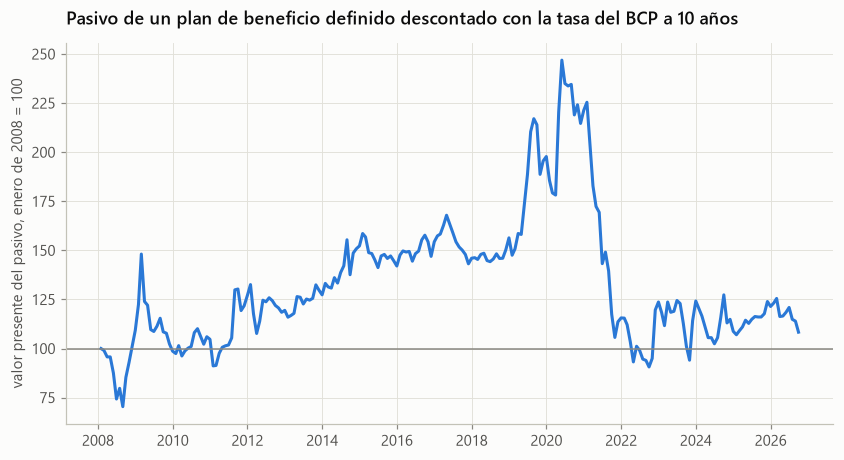

In [5]:
edades = [30, 40, 50, 60]
tasa_actual = float(bcp["10"].iloc[-1]) / 100
filas = {}
for edad in edades:
    qx = fa.qx_gompertz_makeham(np.arange(edad, edad + 20))
    filas[f"{edad} años"] = {"probabilidad de morir en 20 años": 1 - np.prod(1 - qx),
                             f"prima al {tasa_actual:.1%}": fa.prima_seguro_vida(qx, tasa_actual, 100.0)["prima_anual"],
                             f"prima al {tasa_actual - 0.02:.1%}": fa.prima_seguro_vida(qx, tasa_actual - 0.02, 100.0)["prima_anual"]}
print("Seguro temporal a 20 años por $100 millones; primas en millones al año:")
print(pd.DataFrame(filas).T.round(4).to_string())

bcp10_mensual = bcp["10"].resample("ME").last().dropna() / 100
anios_pago = np.arange(11, 41)
pasivo = pd.Series([np.sum(1 / (1 + y) ** anios_pago) for y in bcp10_mensual], index=bcp10_mensual.index)
duracion = pd.Series([np.sum(anios_pago / (1 + y) ** anios_pago) / np.sum(1 / (1 + y) ** anios_pago) / (1 + y) for y in bcp10_mensual],
                     index=bcp10_mensual.index)
indice_pasivo = 100 * pasivo / pasivo.iloc[0]
print(f"\nDuración modificada del pasivo: entre {duracion.min():.1f} y {duracion.max():.1f} años")
print(f"Pasivo con la tasa mínima ({bcp10_mensual.min():.2%}, {bcp10_mensual.idxmin():%m-%Y}) frente a la máxima"
      f" ({bcp10_mensual.max():.2%}, {bcp10_mensual.idxmax():%m-%Y}): {pasivo.max() / pasivo.min() - 1:.0%} más grande")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(indice_pasivo.index, indice_pasivo, color=COLORES[0], linewidth=2)
ax.axhline(100, color=TINTA_TENUE, linewidth=1)
ax.set_ylabel("valor presente del pasivo, enero de 2008 = 100")
ax.set_title("Pasivo de un plan de beneficio definido descontado con la tasa del BCP a 10 años")
plt.show()

**Lectura.**

- **En el seguro de vida, la edad pesa mucho más que la tasa.** La prima anual por $100 millones pasa de $0,21 millones a los 30 años a $2,57 millones a los 60, porque la probabilidad de morir dentro del plazo sube de 5% a 52%. Bajar la tasa de descuento de 6% a 4% sube la prima solo entre 7% y 8%.
- **El pasivo de pensiones, en cambio, es muy sensible a la tasa.** Su duración modificada va de 19 a 23 años. Con la tasa del BCP a 10 años en su mínimo de mayo de 2020, 2,18%, el pasivo valía 3,5 veces lo que valía con la máxima de agosto de 2008, 8,20%.
- **Un plan con activos de menor duración que sus pasivos pierde fondeo cuando bajan las tasas,** aunque sus inversiones no pierdan nada. Por eso los fondos de pensiones y las aseguradoras de rentas vitalicias calzan duraciones.

### Ejercicios resueltos

**Ejercicio 2.1. Razón combinada** *(ejercicio propio)*

Una aseguradora de autos tiene una siniestralidad de 72% y gastos de 27% de las primas. Sus inversiones rinden el equivalente a 4% de las primas. ¿Tiene utilidad técnica? ¿Y operacional?

In [6]:
combinada = 0.72 + 0.27
print(f"Razón combinada = 72% + 27% = {combinada:.0%}: utilidad técnica de {1 - combinada:.0%} de las primas")
print(f"Respuesta: razón operacional = 99% - 4% = {combinada - 0.04:.0%}: la utilidad total es {1 - combinada + 0.04:.0%} de las primas.")

Razón combinada = 72% + 27% = 99%: utilidad técnica de 1% de las primas
Respuesta: razón operacional = 99% - 4% = 95%: la utilidad total es 5% de las primas.


**Ejercicio 2.2. Valor presente de una renta** *(caso de prueba de los motores de cálculo de frm-prep)*

Una renta vitalicia simplificada paga 1.000 al final de cada año durante 20 años. Con una tasa de 5%, ¿cuánto vale hoy? Usa la función de valor presente al estilo de la calculadora BA II Plus, portada de frm-prep, y verifica el resultado con la fórmula de anualidad.

In [7]:
vp = fa.valor_presente(20, 0.05, pago=-1_000)
formula = 1_000 * (1 - 1.05**-20) / 0.05
print(f"PV con la convención de signos de la BA II Plus: {vp:,.2f}; fórmula de anualidad: {formula:,.2f}")
print("Respuesta: 12.462,21. El pago negativo es el flujo que sale del emisor; el valor presente positivo, lo que cobra hoy.")

PV con la convención de signos de la BA II Plus: 12,462.21; fórmula de anualidad: 12,462.21
Respuesta: 12.462,21. El pago negativo es el flujo que sale del emisor; el valor presente positivo, lo que cobra hoy.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad intermedia)*

La selección adversa surge cuando:

- **A.** ambas partes tienen información idéntica.
- **B.** una parte tiene información privada antes de una transacción, por lo que los tipos más riesgosos tienen más probabilidad de participar (p. ej., los más enfermos compran seguro).
- **C.** no hay asimetría de información.
- **D.** una parte protegida toma más riesgo después de un contrato.

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** La selección adversa es un problema previo al contrato (información oculta): la parte informada se autoselecciona, sesgando el conjunto hacia peores riesgos. Los "limones" en autos usados y los prestatarios de alto riesgo buscando préstamos son ejemplos clásicos; el screening y el signaling lo mitigan.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad intermedia)*

El riesgo moral (moral hazard) en los mercados financieros se refiere a la tendencia de una parte a:

- **A.** revelar toda su información privada voluntariamente.
- **B.** evitar siempre todo el riesgo.
- **C.** seleccionar las peores contrapartes antes de un acuerdo.
- **D.** asumir más riesgo cuando no soporta todas las consecuencias (p. ej., por un seguro o un rescate esperado).

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** El riesgo moral es un problema posterior al contrato: una vez protegida (asegurada, garantizada o "too big to fail"), la parte tiene menos incentivos para controlar el riesgo. Se distingue de la selección adversa, que es un problema de información previo al contrato.

</details>

### Trampas frecuentes

- La razón combinada se calcula antes del ingreso por inversiones; la operacional lo incluye.
- En beneficio definido el riesgo de inversión es de la empresa; en contribución definida, del trabajador.
- Una baja de tasas aumenta el valor de los pasivos de pensiones más que el de activos de menor duración.
- Selección adversa ocurre antes del contrato; riesgo moral, después.

## FMP-3. Gestión de fondos

*Relevancia en el examen: media. Dificultad: intermedia.*

### Idea central

- **Fondos mutuos.** Abiertos (emiten y rescatan cuotas al valor cuota, NAV, del cierre) y cerrados (sus cuotas transan en bolsa, con premio o descuento sobre el NAV). Cobran comisión de administración y, a veces, de entrada o salida.
- **ETF.** Transan durante el día; los participantes autorizados crean y rescatan cuotas en especie, lo que mantiene el precio cerca del NAV. Su error de seguimiento mide cuánto se desvían del índice.
- **Hedge funds.** Poca regulación, apalancamiento, venta corta y derivados. Estructura típica de comisiones de 2% de administración y 20% de desempeño, con marca de agua (high-water mark), retorno mínimo (hurdle) y cláusulas de devolución (clawback). Estrategias: long-short, macro global, arbitraje de convertibles, eventos, renta fija relativa.
- **Desempeño.** Los índices de hedge funds tienen sesgos de supervivencia (los fondos malos dejan de reportar) y de llenado (backfill: entran con su historia buena).
- **La comisión de desempeño es una opción de compra** sobre el resultado del fondo: vale más cuanto más volátil es el fondo.

### Análisis avanzado: comisiones con marca de agua y sesgo de supervivencia

Primero se aplica una estructura 2 y 20 a los retornos anuales reales del ETF IPSA desde 2019, con y sin marca de agua. Luego se simulan 1.000 fondos sin ninguna habilidad durante 10 años; cada año cierra el 10% con peor resultado acumulado. Se compara el retorno promedio de todos los fondos con el de los que sobreviven.

In [8]:
serie_ipsa = precios["ETF IPSA"]
cierres = pd.concat([serie_ipsa.iloc[:1], serie_ipsa.resample("YE").last()])
anuales = cierres.pct_change().dropna().loc[:"2025"]
con_marca = fa.comisiones_fondo(anuales.to_numpy())
sin_marca = fa.comisiones_fondo(anuales.to_numpy(), marca_agua=False)
for tabla in (con_marca, sin_marca):
    tabla.index = anuales.index.year
bruto = 100 * np.prod(1 + anuales)
print(f"Valor bruto final de 100 invertidos: {bruto:.1f}")
print(f"Con marca de agua: valor neto {con_marca['valor_neto'].iloc[-1]:.1f}; comisiones de desempeño {con_marca['comision_desempeno'].sum():.1f}")
print(f"Sin marca de agua: valor neto {sin_marca['valor_neto'].iloc[-1]:.1f}; comisiones de desempeño {sin_marca['comision_desempeno'].sum():.1f}")

rng = np.random.default_rng(3)
n_fondos, n_anios = 1_000, 10
retornos_fondos = rng.normal(0.06, 0.15, size=(n_fondos, n_anios))
vivo = np.ones(n_fondos, dtype=bool)
filas = []
for anio in range(n_anios):
    acumulado = np.prod(1 + retornos_fondos[:, :anio + 1], axis=1)
    filas.append({"año": anio + 1, "fondos vivos": int(vivo.sum()),
                  "retorno promedio de todos": retornos_fondos[:, anio].mean(),
                  "retorno promedio histórico de los vivos": retornos_fondos[vivo, :anio + 1].mean()})
    umbral_cierre = np.quantile(acumulado[vivo], 0.10)
    vivo &= acumulado > umbral_cierre
sesgo = pd.DataFrame(filas).set_index("año")
print(f"\nTras 10 años sobreviven {vivo.sum()} fondos. Retorno anual medio de todos: {retornos_fondos.mean():.2%};"
      f" de los sobrevivientes: {retornos_fondos[vivo].mean():.2%}")
con_marca.round(2)

Valor bruto final de 100 invertidos: 146.4
Con marca de agua: valor neto 122.3; comisiones de desempeño 5.6
Sin marca de agua: valor neto 115.7; comisiones de desempeño 10.7

Tras 10 años sobreviven 347 fondos. Retorno anual medio de todos: 6.00%; de los sobrevivientes: 10.80%


,retorno_bruto,comision_gestion,comision_desempeno,valor_neto,retorno_neto
fecha,,,,,
2019,-0.0900,2.0000,0.0000,89.2900,-0.1100
2020,-0.1000,1.7900,0.0000,78.5800,-0.1200
2021,-0.0500,1.5700,0.0000,73.1200,-0.0700
2022,0.1100,1.4600,0.0000,79.7900,0.0900
2023,0.1000,1.6000,0.0000,85.9100,0.0800
2024,0.0300,1.7200,0.0000,86.6700,0.0100
2025,0.4900,1.7300,5.5700,122.2700,0.4100


**Lectura.**

- **Las comisiones se llevan más de la mitad de la ganancia.** Cien invertidos a inicios de 2019 se convierten en 146,4 brutos, pero el inversionista recibe 122,3 con marca de agua.
- **La marca de agua importa.** Con ella, solo 2025, con un retorno bruto de 49%, paga desempeño: los años malos de 2019 a 2021 dejaron la cuota bajo su máximo. Sin marca de agua, el gestor cobra 10,7 de desempeño en vez de 5,6, porque cobra también por recuperar pérdidas, y el inversionista termina con 115,7.
- **El sesgo de supervivencia es enorme.** Los fondos sin habilidad rinden en promedio 6,0% al año; los 347 que sobreviven diez años, 10,8%. Un índice que solo ve a los sobrevivientes exagera el retorno en casi 5 puntos al año sin que ningún gestor tenga habilidad.

### Ejercicios resueltos

**Ejercicio 3.1. Valor cuota y premio de un fondo cerrado** *(ejercicio propio)*

Un fondo cerrado tiene activos por 1.250 millones, pasivos por 50 millones y 40 millones de cuotas, que transan en bolsa a 28,50. Calcula su valor cuota y el descuento.

In [9]:
nav = (1_250 - 50) / 40
print(f"NAV = (1.250 - 50) / 40 = {nav:.2f}")
print(f"Respuesta: la cuota transa con un descuento de {1 - 28.5 / nav:.1%} sobre su NAV.")

NAV = (1.250 - 50) / 40 = 30.00
Respuesta: la cuota transa con un descuento de 5.0% sobre su NAV.


**Ejercicio 3.2. Comisión con retorno mínimo y marca de agua** *(ejercicio propio)*

Un fondo cobra 2% de administración sobre el valor inicial y 20% de desempeño sobre la ganancia que excede un retorno mínimo de 5%, con marca de agua. Parte en 100 y rinde 25% bruto. ¿Cuánto cobra y cuánto queda para el inversionista?

In [10]:
tabla_fondo = fa.comisiones_fondo([0.25], gestion=0.02, desempeno=0.20, umbral=0.05)
fila = tabla_fondo.iloc[0]
print(f"Administración: {fila['comision_gestion']:.2f}. Valor tras administración: {100 * 1.25 - fila['comision_gestion']:.2f}")
print(f"Desempeño: 20% × (123 - 105) = {fila['comision_desempeno']:.2f}")
print(f"Respuesta: valor neto {fila['valor_neto']:.2f}; retorno neto {fila['retorno_neto']:.1%} frente a 25% bruto.")

Administración: 2.00. Valor tras administración: 123.00
Desempeño: 20% × (123 - 105) = 3.60
Respuesta: valor neto 119.40; retorno neto 19.4% frente a 25% bruto.


### Preguntas de práctica

**Pregunta 1** *(pregunta propia, cálculo, dificultad avanzada)*

Un hedge fund cobra 2% de gestión sobre el valor inicial de cada año y 20% de desempeño con marca de agua (high-water mark). La cuota parte en 100. Rinde 30% bruto el año 1 y −20% el año 2. ¿Cuánta comisión de desempeño cobra el año 3 si ese año rinde 15% bruto?

- **A.** 2,48
- **B.** 3,00
- **C.** 1,91
- **D.** 0

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** Año 1: 100 × 1,30 − 2 = 128; desempeño 20% × 28 = 5,6; queda en 122,4, que es la marca de agua. Año 2: 122,4 × 0,80 − 2,45 = 95,47, sin desempeño. Año 3: 95,47 × 1,15 − 1,91 = 107,88, bajo la marca de 122,4, así que no cobra desempeño. Sin marca de agua habría cobrado 20% × (107,88 − 95,47) = 2,48.

</details>

**Pregunta 2** *(pregunta propia, cálculo, dificultad básica)*

Un fondo mutuo tiene activos por $520 millones, pasivos por $20 millones y 25 millones de cuotas en circulación. ¿Cuál es su valor cuota (NAV)?

- **A.** $19,20
- **B.** $20,00
- **C.** $20,80
- **D.** $25,00

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** NAV = (activos − pasivos) / cuotas = (520 − 20) / 25 = $20,00. Los fondos abiertos emiten y rescatan cuotas a este valor, calculado al cierre de cada día.

</details>

### Trampas frecuentes

- Con marca de agua, el gestor no cobra desempeño hasta recuperar el máximo anterior.
- El sesgo de supervivencia infla los retornos de los índices de hedge funds; el de llenado también.
- Un fondo cerrado puede transar con descuento sobre su NAV por mucho tiempo; un ETF no, gracias a la creación y el rescate.

## FMP-4. Introducción a los derivados

*Relevancia en el examen: alta. Dificultad: intermedia.*

### Idea central

- **Instrumentos.** Forwards (contratos privados a plazo), futuros (estandarizados, en bolsa, con márgenes diarios), opciones (el derecho, no la obligación) y swaps (intercambios de flujos).
- **Mercados.** En bolsa, con contratos estándar y cámara de compensación; fuera de bolsa (OTC), a medida, con más riesgo de contraparte, mitigado hoy con colateral y compensación central.
- **Participantes.** Los coberturistas reducen un riesgo que ya tienen; los especuladores toman posiciones apalancadas; los arbitrajistas aprovechan precios inconsistentes sin riesgo.
- **Pagos al vencimiento.** Forward largo $S_T - K$; call $\max(S_T - K, 0)$; put $\max(K - S_T, 0)$. La opción cuesta una prima hoy; el forward no cuesta nada al inicio.
- **Apalancamiento.** La elasticidad de una opción, $\Omega = \Delta \cdot S / C$, mide cuántas veces se amplifica el retorno del subyacente.

### Análisis avanzado: perfiles de pago y apalancamiento sobre el dólar

Se comparan tres posiciones a un año sobre USD 1 millón: un forward largo, una call y una put vendida, ambas con strike igual al forward, valoradas con Garman-Kohlhagen con las tasas y la volatilidad actuales. Luego se calcula el retorno sobre el capital invertido si el dólar sube o baja 5%.

Forward a un año 959.49; call 39.08; put 39.08 pesos por dólar


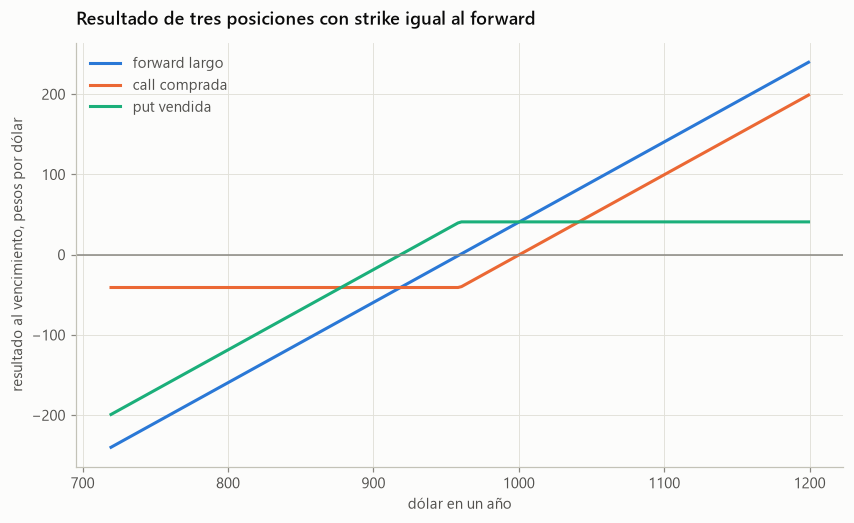

,dólar +5%,dólar -5%
dólares al contado,+5.0%,-5.0%
forward con margen de 10%,+50.0%,-50.0%
call comprada,+71.7%,-50.2%


In [11]:
forward_1a = frm.precio_forward(spot, r_clp, 1.0, rendimiento=r_usd)
prima_call = frm.black_scholes(spot, forward_1a, r_clp, vol_usd, 1.0, "call", q=r_usd)
prima_put = frm.black_scholes(spot, forward_1a, r_clp, vol_usd, 1.0, "put", q=r_usd)
precios_finales = np.linspace(0.75 * spot, 1.25 * spot, 200)
capitalizacion = np.exp(r_clp)
resultados = {
    "forward largo": precios_finales - forward_1a,
    "call comprada": np.maximum(precios_finales - forward_1a, 0) - prima_call * capitalizacion,
    "put vendida": prima_put * capitalizacion - np.maximum(forward_1a - precios_finales, 0),
}
print(f"Forward a un año {forward_1a:,.2f}; call {prima_call:,.2f}; put {prima_put:,.2f} pesos por dólar")

fig, ax = plt.subplots(figsize=(9, 5))
for color, (nombre, pnl) in zip(COLORES, resultados.items()):
    ax.plot(precios_finales, pnl, color=color, linewidth=2, label=nombre)
ax.axhline(0, color=TINTA_TENUE, linewidth=1)
ax.set_xlabel("dólar en un año")
ax.set_ylabel("resultado al vencimiento, pesos por dólar")
ax.set_title("Resultado de tres posiciones con strike igual al forward")
ax.legend(loc="upper left")
plt.show()

capital_invertido = {"dólares al contado": spot, "forward con margen de 10%": 0.10 * spot, "call comprada": prima_call}
filas = {}
for nombre, base in capital_invertido.items():
    for movimiento in (0.05, -0.05):
        s_final = spot * (1 + movimiento)
        if nombre == "dólares al contado":
            ganancia = s_final - spot
        elif nombre == "call comprada":
            ganancia = frm.black_scholes(s_final, forward_1a, r_clp, vol_usd, 1.0, "call", q=r_usd) - prima_call
        else:
            ganancia = frm.precio_forward(s_final, r_clp, 1.0, rendimiento=r_usd) - forward_1a
        filas.setdefault(nombre, {})[f"dólar {movimiento:+.0%}"] = ganancia / base
pd.DataFrame(filas).T.map("{:+.1%}".format)

**Lectura.**

- **Con strike igual al forward, la call y la put cuestan lo mismo,** 39,08 pesos por dólar: es la paridad put-call. Comprar la call y vender la put equivale al forward largo, como muestra el gráfico.
- **Los derivados apalancan.** Un movimiento de 5% del dólar da ±5% en dólares al contado, ±50% sobre el margen de un forward con 10% de garantía, y +72% o −50% sobre la prima de una call, cuya elasticidad es 12.
- **La opción es asimétrica:** gana más cuando el dólar sube de lo que pierde cuando baja, porque su pérdida máxima es la prima.

### Ejercicios resueltos

**Ejercicio 4.1. Arbitraje con un forward mal cotizado** *(ejercicio propio)*

El dólar vale 950 pesos, la tasa en pesos a un año es 5% y la tasa en dólares 4%, ambas con capitalización anual. Un banco cotiza el forward a un año en 970. ¿Cuál es el precio de no arbitraje y cómo se aprovecha la diferencia?

In [12]:
teorico = 950 * 1.05 / 1.04
print(f"Forward de no arbitraje = 950 × 1,05 / 1,04 = {teorico:.2f}")
print("Estrategia por cada dólar: pedir 950/1,04 pesos al 5%, comprar 1/1,04 dólares, invertirlos al 4% y vender 1 dólar forward a 970.")
print(f"Respuesta: al vencimiento se entregan los dólares, se reciben 970 y se pagan {950 / 1.04 * 1.05:.2f} de deuda: ganancia sin riesgo de {970 - teorico:.2f} pesos por dólar.")

Forward de no arbitraje = 950 × 1,05 / 1,04 = 959.13
Estrategia por cada dólar: pedir 950/1,04 pesos al 5%, comprar 1/1,04 dólares, invertirlos al 4% y vender 1 dólar forward a 970.
Respuesta: al vencimiento se entregan los dólares, se reciben 970 y se pagan 959.13 de deuda: ganancia sin riesgo de 10.87 pesos por dólar.


**Ejercicio 4.2. Elasticidad de una opción** *(ejercicio propio)*

Calcula la delta y la elasticidad de la call a un año sobre el dólar del análisis anterior. ¿Cuánto rinde la call si el dólar sube 1% de inmediato?

In [13]:
g = frm.griegas(spot, forward_1a, r_clp, vol_usd, 1.0, "call", q=r_usd)
elasticidad = g["delta"] * spot / prima_call
print(f"Delta {g['delta']:.3f}; elasticidad = Δ·S/C = {g['delta']:.3f} × {spot:,.2f} / {prima_call:,.2f} = {elasticidad:.1f}")
print(f"Respuesta: si el dólar sube 1%, la call sube cerca de {elasticidad:.1f}%: es una apuesta apalancada.")

Delta 0.498; elasticidad = Δ·S/C = 0.498 × 959.39 / 39.08 = 12.2
Respuesta: si el dólar sube 1%, la call sube cerca de 12.2%: es una apuesta apalancada.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad básica)*

En los mercados de derivados, un arbitrajista se describe mejor como alguien que:

- **A.** busca una ganancia sin riesgo operando simultáneamente instrumentos relacionados que están mal valuados entre sí.
- **B.** usa derivados para reducir una exposición existente.
- **C.** solo provee liquidez como creador de mercado.
- **D.** asume riesgo de precio esperando ganar con una visión direccional.

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** Los cubridores reducen riesgo existente; los especuladores asumen riesgo por una ganancia esperada; los arbitrajistas explotan discrepancias de precio entre instrumentos relacionados para una ganancia (casi) sin riesgo, lo que ayuda a hacer cumplir la valuación de no-arbitraje.

</details>

**Pregunta 2** *(banco de frm-prep, cálculo, dificultad intermedia)*

Una call tiene un delta de 0.60, la acción vale \$50 y el precio de la opción es \$5. La elasticidad (apalancamiento) de la opción es más cercana a:

- **A.** 10.0
- **B.** 6.0
- **C.** 0.6
- **D.** 3.0

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** Elasticidad $\Omega = \Delta \times \dfrac{S}{C} = 0.60 \times \dfrac{50}{5} = 6.0$. Un movimiento de 1% en la acción cambia el valor de la opción en ~6%.

</details>

### Trampas frecuentes

- Un forward no cuesta nada al inicio, pero no está libre de riesgo: su valor cambia con el subyacente.
- Un coberturista que usa forwards renuncia a la ganancia; uno que usa opciones paga una prima por conservarla.
- El vendedor de una opción tiene pérdida potencial muy grande y ganancia limitada a la prima.

## FMP-5. Bolsas y mercados OTC

*Relevancia en el examen: media. Dificultad: intermedia.*

### Idea central

- **Bolsas.** Contratos estandarizados, transparencia de precios, creadores de mercado que dan liquidez y una cámara que garantiza el cumplimiento.
- **Órdenes.** De mercado (se ejecuta ya, al mejor precio disponible), limitada (a un precio máximo o mínimo), stop (se activa al tocar un precio) y stop limit. Una orden de mercado grande recorre el libro y paga más que el precio medio.
- **Mercados OTC.** Contratos a medida entre dos partes. Tras 2008, los derivados estandarizados deben compensarse en una contraparte central, reportarse a repositorios y, si no se compensan, intercambiar margen inicial y de variación.
- **Colateral.** El anexo de garantías (CSA) fija el umbral (exposición sin colateral), el monto mínimo de transferencia, el monto independiente y el colateral elegible con sus descuentos.
- **Período de riesgo de margen.** Aun con colateral diario, si la contraparte quiebra pasan varios días hasta cerrar la posición: esa es la exposición que queda.

### Análisis avanzado: exposición de un forward con y sin colateral

Un banco compra USD 10 millones a un año por forward a una empresa. Se simulan 5.000 trayectorias diarias del dólar con la volatilidad actual y se calcula la exposición esperada (EE) y la exposición potencial futura al 95% (PFE) a lo largo de la vida del contrato. Con un CSA sin umbral, el colateral sigue el valor del contrato con un rezago de 10 días hábiles, el período de riesgo de margen.

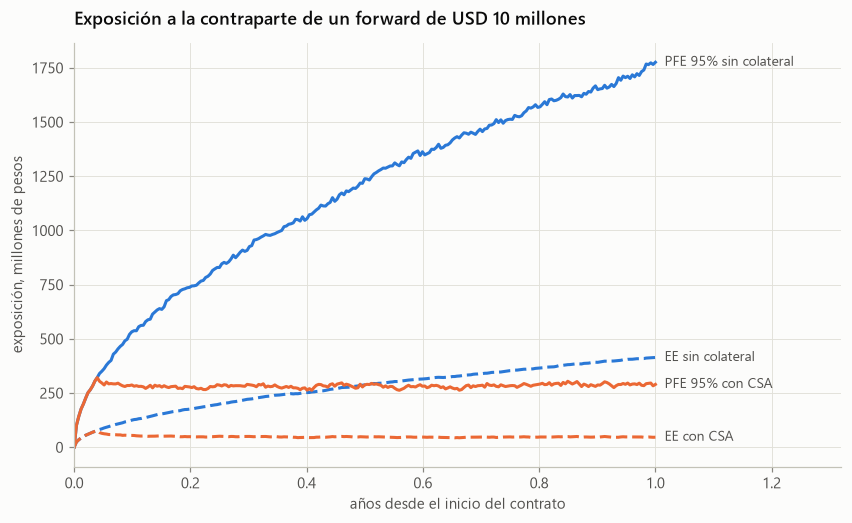

,EE sin colateral,PFE 95% sin colateral,EE con CSA,PFE 95% con CSA
0.08 años,112.9000,474.3000,55.0000,283.5000
0.25 años,199.4000,829.2000,50.9000,286.7000
0.50 años,287.7000,"1,238.7000",47.8000,287.9000
0.75 años,353.5000,"1,513.2000",47.8000,284.0000
0.99 años,413.0000,"1,773.2000",46.9000,296.2000


In [14]:
nominal, plazo, pasos, mpr = 10.0, 1.0, 252, 10
rutas = fa.simular_gbm(spot, r_clp - r_usd, vol_usd, plazo, pasos, 5_000, semilla=5)
t = np.arange(pasos + 1) / pasos
precio_pactado = spot * np.exp((r_clp - r_usd) * plazo)
valor = nominal * (rutas * np.exp((r_clp - r_usd) * (plazo - t)) - precio_pactado) * np.exp(-r_clp * (plazo - t))
sin_csa = np.maximum(valor, 0)
colateral = np.zeros_like(valor)
colateral[:, mpr:] = np.maximum(valor[:, :-mpr], 0)
con_csa = np.maximum(valor - colateral, 0)

perfiles = pd.DataFrame({
    "EE sin colateral": sin_csa.mean(axis=0), "PFE 95% sin colateral": np.quantile(sin_csa, 0.95, axis=0),
    "EE con CSA": con_csa.mean(axis=0), "PFE 95% con CSA": np.quantile(con_csa, 0.95, axis=0),
}, index=t)
fig, ax = plt.subplots(figsize=(9, 5))
estilos = {"EE sin colateral": (COLORES[0], "--"), "PFE 95% sin colateral": (COLORES[0], "-"),
           "EE con CSA": (COLORES[1], "--"), "PFE 95% con CSA": (COLORES[1], "-")}
for nombre, (color, linea) in estilos.items():
    ax.plot(perfiles.index, perfiles[nombre], color=color, linestyle=linea, linewidth=2)
    ax.annotate(nombre, (perfiles.index[-1], perfiles[nombre].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=TINTA_SECUNDARIA, fontsize=9)
ax.set_xlim(0, 1.32)
ax.set_xlabel("años desde el inicio del contrato")
ax.set_ylabel("exposición, millones de pesos")
ax.set_title("Exposición a la contraparte de un forward de USD 10 millones")
fig.savefig(FIGURAS / "exposicion_forward.png", bbox_inches="tight")
plt.show()
perfiles.iloc[[21, 63, 126, 189, 250]].rename(index=lambda x: f"{x:.2f} años").round(1)

**Lectura.**

- **Sin colateral, la exposición crece con la raíz del tiempo.** Al final del año, la exposición esperada es 413 millones de pesos y la potencial al 95% llega a 1.773 millones, 18% del nocional.
- **Con un CSA, la exposición se mantiene casi constante:** la esperada ronda los 50 millones y la potencial al 95%, unos 290 millones. Lo que queda es el movimiento del dólar durante los 10 días del período de riesgo de margen.
- **El colateral reduce la exposición potencial del final del año en 83%,** pero no a cero. Por eso el capital por riesgo de contraparte se calcula aun con colateral.

### Ejercicios resueltos

**Ejercicio 5.1. Llamados de colateral con umbral y monto mínimo** *(ejercicio propio)*

Un CSA fija un umbral de 10 millones y un monto mínimo de transferencia de 1 millón. Calcula la transferencia en cuatro días: exposición de 8 sin colateral; de 12,5 sin colateral; de 12,8 con 2,5 entregados; y de 9 con 2,5 entregados.

In [15]:
casos = [(8.0, 0.0), (12.5, 0.0), (12.8, 2.5), (9.0, 2.5)]
for exposicion, entregado in casos:
    transferencia = fa.llamado_colateral(exposicion, entregado, umbral=10.0, monto_minimo=1.0)
    print(f"Exposición {exposicion:>5.1f}, colateral {entregado:.1f}: transferencia {transferencia:+.1f}")
print("Respuesta: 0, +2,5, 0 (falta solo 0,3, bajo el mínimo) y -2,5 (se devuelve todo, porque la exposición quedó bajo el umbral).")

Exposición   8.0, colateral 0.0: transferencia +0.0
Exposición  12.5, colateral 0.0: transferencia +2.5
Exposición  12.8, colateral 2.5: transferencia +0.0
Exposición   9.0, colateral 2.5: transferencia -2.5
Respuesta: 0, +2,5, 0 (falta solo 0,3, bajo el mínimo) y -2,5 (se devuelve todo, porque la exposición quedó bajo el umbral).


**Ejercicio 5.2. Costo de una orden de mercado** *(ejercicio propio)*

El libro de ventas de una acción tiene 300 acciones a 100,05, 500 a 100,10 y 1.000 a 100,20. El precio medio entre compra y venta es 100,00. ¿Cuánto paga en promedio una orden de mercado de compra por 1.000 acciones y cuál es su costo de ejecución?

In [16]:
libro = [(100.05, 300), (100.10, 500), (100.20, 1_000)]
restante, costo = 1_000, 0.0
for precio_nivel, cantidad in libro:
    tomado = min(restante, cantidad)
    costo += tomado * precio_nivel
    restante -= tomado
promedio = costo / 1_000
print(f"Precio promedio pagado: {promedio:.3f}")
print(f"Respuesta: el costo frente al precio medio es {promedio - 100:.3f} por acción, {10_000 * (promedio / 100 - 1):.1f} puntos base.")

Precio promedio pagado: 100.105
Respuesta: el costo frente al precio medio es 0.105 por acción, 10.5 puntos base.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad básica)*

Una diferencia clave entre derivados negociados en bolsa y OTC es que los de bolsa:

- **A.** no pueden cerrarse antes del vencimiento.
- **B.** están estandarizados y se compensan a través de una contraparte central con margen diario, reduciendo el riesgo de contraparte.
- **C.** están totalmente personalizados y no tienen riesgo de contraparte.
- **D.** nunca requieren margen.

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** Los derivados de bolsa están estandarizados y se novan a una cámara central que exige margen inicial y de variación, reduciendo fuertemente el riesgo de contraparte. Los OTC son personalizables pero históricamente cargaban más riesgo de contraparte (hoy mitigado con colateral y, para muchos productos, compensación obligatoria).

</details>

**Pregunta 2** *(pregunta propia, cálculo, dificultad intermedia)*

Un CSA fija un umbral de $10 millones y un monto mínimo de transferencia de $1 millón. La exposición sube a $10,8 millones y todavía no se ha entregado colateral. ¿Cuánto colateral se transfiere?

- **A.** $1,0 millón
- **B.** $0,8 millones
- **C.** $0
- **D.** $10,8 millones

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** El colateral requerido es la exposición sobre el umbral: 10,8 − 10 = $0,8 millones. Como es menor que el monto mínimo de transferencia de $1 millón, no se transfiere nada. El umbral y el monto mínimo reducen los movimientos operativos a cambio de dejar exposición sin cubrir.

</details>

### Trampas frecuentes

- El colateral no elimina el riesgo de contraparte: queda la exposición del período de riesgo de margen.
- Un umbral alto en el CSA reduce los movimientos de colateral, pero deja más exposición sin cubrir.
- Una orden limitada garantiza el precio, no la ejecución; una de mercado, la ejecución, no el precio.

## FMP-6. Compensación central

*Relevancia en el examen: media. Dificultad: intermedia.*

### Idea central

- **Novación.** La contraparte central (CCP) se convierte en compradora de todos los vendedores y vendedora de todos los compradores. Cada miembro queda expuesto solo a la CCP.
- **Compensación multilateral.** Cada miembro neta todas sus posiciones contra la CCP, lo que reduce mucho la exposición total frente a la compensación bilateral.
- **Márgenes.** El margen de variación liquida las ganancias y pérdidas diarias. El margen inicial cubre la pérdida posible durante el cierre de la posición de un miembro que incumple, típicamente un VaR o ES de varios días al 99% o más.
- **Cascada de incumplimiento.** Margen inicial del moroso, su aporte al fondo de garantía, capital propio de la CCP (skin in the game), fondo de garantía de los demás miembros y, al final, llamados adicionales y otras herramientas de recuperación.
- **Riesgos de la CCP.** Concentra el riesgo en una sola entidad, crea necesidades de liquidez por los márgenes y sus márgenes son procíclicos: suben cuando la volatilidad sube, justo en la crisis.

### Análisis avanzado: márgenes procíclicos y la cascada de incumplimiento

Se calcula el margen inicial de un forward de dólar como el expected shortfall al 99% de los cambios de dos días, con una ventana móvil de un año de datos desde 2000, tomando la peor de las dos colas. Luego se aplica la cascada de incumplimiento de una cámara a un miembro con una posición de USD 50 millones, en dos escenarios de estrés.

Margen inicial: mínimo 1.26% (08-2007); máximo 6.22% (09-2022); hoy 3.14%


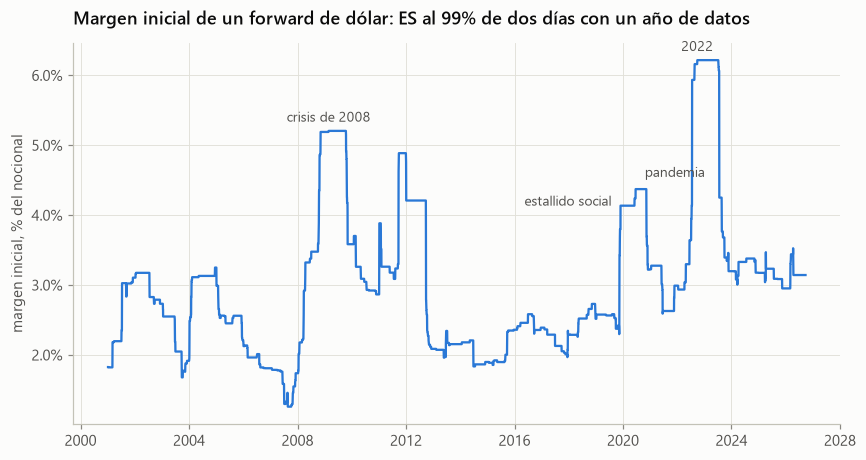


peor cambio histórico de dos días: pérdida de 4,940 millones de pesos
                                   tamano      usado  porcentaje_usado
capa                                                                  
margen inicial del moroso      1,507.9600 1,507.9600            1.0000
aporte del moroso al fondo       376.9900   376.9900            1.0000
capital propio de la cámara      300.0000   300.0000            1.0000
fondo de garantía de los demás 3,000.0000 2,755.4700            0.9200
pérdida no cubierta                   NaN     0.0000               NaN

el doble del peor histórico: pérdida de 9,881 millones de pesos
                                   tamano      usado  porcentaje_usado
capa                                                                  
margen inicial del moroso      1,507.9600 1,507.9600            1.0000
aporte del moroso al fondo       376.9900   376.9900            1.0000
capital propio de la cámara      300.0000   300.0000            1.0000
fondo de gar

In [17]:
cambios_2d = np.log(dolar).diff(2).dropna()

def es_dos_colas(x, nivel=0.99):
    perdidas = np.concatenate([x, -x])
    umbral = np.quantile(perdidas, nivel)
    return perdidas[perdidas >= umbral].mean()

margen = cambios_2d.rolling(250).apply(es_dos_colas, raw=True).dropna()
picos = {etiqueta: (margen.loc[desde:hasta].idxmax(), margen.loc[desde:hasta].max())
         for etiqueta, desde, hasta in [("crisis de 2008", "2008", "2009"), ("estallido social", "2019-10", "2020-02"),
                                        ("pandemia", "2020-03", "2020-12"), ("2022", "2022", "2022")]}
print(f"Margen inicial: mínimo {margen.min():.2%} ({margen.idxmin():%m-%Y}); máximo {margen.max():.2%} ({margen.idxmax():%m-%Y}); hoy {margen.iloc[-1]:.2%}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(margen.index, margen, color=COLORES[0], linewidth=1.5)
desplazamientos = {"estallido social": (-6, 0, "right"), "pandemia": (6, 8, "left")}
for etiqueta, (fecha, valor) in picos.items():
    dx, dy, alineacion = desplazamientos.get(etiqueta, (0, 6, "center"))
    ax.annotate(etiqueta, (fecha, valor), xytext=(dx, dy), textcoords="offset points", ha=alineacion, color=TINTA_SECUNDARIA, fontsize=9)
eje_porcentaje(ax, decimales=1)
ax.set_ylabel("margen inicial, % del nocional")
ax.set_title("Margen inicial de un forward de dólar: ES al 99% de dos días con un año de datos")
plt.show()

nocional = 50 * spot
margen_inicial = margen.iloc[-1] * nocional
capas = {"margen inicial del moroso": margen_inicial, "aporte del moroso al fondo": 0.25 * margen_inicial,
         "capital propio de la cámara": 300.0, "fondo de garantía de los demás": 3_000.0}
peor_2d = float(cambios_2d.abs().max())
for nombre, perdida in [("peor cambio histórico de dos días", peor_2d * nocional), ("el doble del peor histórico", 2 * peor_2d * nocional)]:
    print(f"\n{nombre}: pérdida de {perdida:,.0f} millones de pesos")
    print(fa.cascada_incumplimiento(perdida, capas).round(2).to_string())

**Lectura.**

- **El margen es procíclico.** Varía de 1,3% del nocional en agosto de 2007 a 6,2% en septiembre de 2022, casi cinco veces. Sube justo después de cada episodio de estrés, cuando los participantes tienen menos liquidez.
- **La cascada funciona en un estrés histórico, pero no en uno peor.** Con el margen actual de 3,1%, una posición de USD 50 millones deposita 1.508 millones. El peor movimiento histórico de dos días produce una pérdida de 4.940 millones, que consume los recursos del moroso, el capital propio de la cámara y el 92% del fondo de los demás miembros. Con el doble de ese movimiento quedan 4.696 millones sin cubrir.
- **Calibrar con ventanas largas o con un piso de estrés reduce la prociclicidad,** a cambio de márgenes más altos en tiempos tranquilos.

### Ejercicios resueltos

**Ejercicio 6.1. Compensación bilateral frente a multilateral** *(ejercicio propio)*

Tres bancos tienen estas obligaciones: A le debe 100 a B y 20 a C; B le debe 60 a C y 30 a A; C le debe 80 a A y 10 a B. Calcula la exposición total con compensación bilateral y con una contraparte central.

In [18]:
deudas = pd.DataFrame([[0, 100, 20], [30, 0, 60], [80, 10, 0]], index=list("ABC"), columns=list("ABC"), dtype=float)
bilateral = frm.exposicion_neta(deudas, multilateral=False)
multilateral = frm.exposicion_neta(deudas, multilateral=True)
print(f"Bruta: {deudas.to_numpy().sum():.0f}; bilateral: {bilateral:.0f}; multilateral: {multilateral:.0f}")
print(f"Respuesta: la contraparte central reduce la exposición de {bilateral:.0f} a {multilateral:.0f}.")

Bruta: 300; bilateral: 180; multilateral: 20
Respuesta: la contraparte central reduce la exposición de 180 a 20.


**Ejercicio 6.2. Quién paga un incumplimiento** *(ejercicio propio)*

Un miembro incumple con una pérdida de 150. Tenía margen inicial de 80 y un aporte de 30 al fondo de garantía. La cámara pone 20 de capital propio antes del fondo mutualizado de 100. ¿Cuánto absorbe cada capa?

In [19]:
cascada = fa.cascada_incumplimiento(150, {"margen inicial": 80, "aporte del moroso": 30, "capital de la cámara": 20, "fondo mutualizado": 100})
print(cascada.to_string())
print("Respuesta: el moroso pierde 110, la cámara 20 y los demás miembros 20, el 20% del fondo mutualizado.")

                       tamano  usado  porcentaje_usado
capa                                                  
margen inicial        80.0000     80            1.0000
aporte del moroso     30.0000     30            1.0000
capital de la cámara  20.0000     20            1.0000
fondo mutualizado    100.0000     20            0.2000
pérdida no cubierta       NaN      0               NaN
Respuesta: el moroso pierde 110, la cámara 20 y los demás miembros 20, el 20% del fondo mutualizado.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad intermedia)*

Mediante la novación, una cámara de compensación de futuros:

- **A.** empareja compradores y vendedores pero no toma posición.
- **B.** se convierte en comprador de cada vendedor y vendedor de cada comprador, garantizando el cumplimiento y eliminando el riesgo bilateral de contraparte.
- **C.** presta dinero a los traders.
- **D.** fija el precio de cada contrato.

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** La novación significa que la cámara se interpone como contraparte central de ambos lados de cada operación. Respaldada por márgenes y un fondo de garantía, asegura que el default de una parte no afecte a la otra.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad intermedia)*

El margen de variación en un derivado con compensación central es:

- **A.** Una comisión única inicial a la cámara de compensación
- **B.** Solo se aporta al vencimiento del contrato
- **C.** La transferencia diaria que liquida la ganancia/pérdida a mercado (mark-to-market) de la posición
- **D.** Un colchón contra posibles pérdidas futuras

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** El margen de variación es el movimiento diario de efectivo que refleja el P&L a mercado: el lado perdedor paga al ganador cada día. El margen inicial (distinto) es el colchón contra movimientos potenciales antes de la siguiente liquidación.

</details>

### Trampas frecuentes

- La compensación central no elimina el riesgo de contraparte: lo concentra en la cámara.
- El margen de variación no es un colchón: liquida pérdidas ya ocurridas. El colchón es el margen inicial.
- El fondo de garantía de los demás miembros se usa después de los recursos del moroso y del capital propio de la cámara.
- Los márgenes basados en ventanas recientes suben en las crisis y crean presión de liquidez.

## FMP-7. Mercados de futuros

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Especificación.** Activo, tamaño del contrato, meses de entrega, lugar y opciones de entrega, límites de precio y de posición.
- **Liquidación diaria.** Cada día las ganancias y pérdidas se pagan en efectivo. Si el saldo cae bajo el margen de mantención, el inversionista debe reponerlo hasta el margen inicial.
- **Convergencia.** Al vencimiento, el futuro converge al spot. La base es spot menos futuro.
- **Contango y backwardation.** Futuros sobre o bajo el spot. El interés abierto cuenta los contratos vigentes; el volumen, los transados en el día.
- **Futuros y forwards.** Con tasas determinísticas valen lo mismo. Si el subyacente se correlaciona positivamente con las tasas, el futuro vale algo más que el forward, porque las ganancias diarias se reinvierten a tasas altas y las pérdidas se financian a tasas bajas.

### Análisis avanzado: liquidez en riesgo por llamados de margen

Un exportador cubre USD 10 millones vendiendo futuros de dólar. Su cobertura es buena en valor, pero si el dólar sube debe pagar márgenes antes de recibir los dólares de sus ventas. Se calcula la distribución histórica de los pagos de margen acumulados en 20 días hábiles desde 2000, y se simula la cuenta de margen durante el estallido social de 2019.

percentil 95%     383.0000
percentil 99%     651.0000
peor caso       1,762.0000
El peor caso terminó el 15-07-2022

Estallido social: dólar de 728 a 828. Margen inicial 291 millones; 7 llamados por un total de 1,000 millones


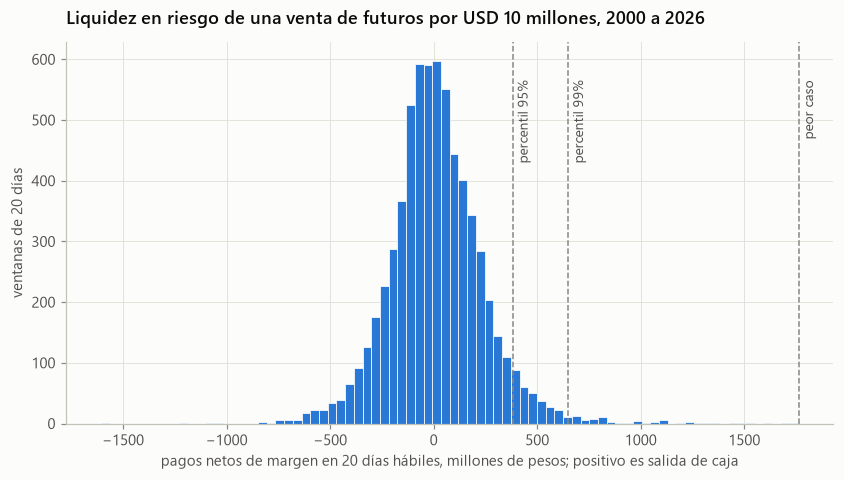

,precio,ganancia_diaria,llamado,saldo
fecha,,,,
2019-11-05,736.7000,-16.1000,84.5000,291.3000
2019-11-06,745.8000,-91.9000,91.9000,291.3000
2019-11-12,756.1000,-98.5000,102.3000,291.3000
2019-11-13,783.7000,-276.4000,276.4000,291.3000
2019-11-14,794.5000,-107.9000,107.9000,291.3000
2019-11-15,801.8000,-73.2000,73.2000,291.3000
2019-11-29,828.2000,-219.5000,264.2000,291.3000


In [20]:
posicion = -10.0  # millones de USD, vendida
pagos_20d = (posicion * dolar.diff(20)).dropna()
salidas = -pagos_20d
percentiles = pd.Series({"percentil 95%": salidas.quantile(0.95), "percentil 99%": salidas.quantile(0.99),
                         "peor caso": salidas.max()}, name="salida de caja en 20 días, millones de pesos")
print(percentiles.round(0).to_string())
print(f"El peor caso terminó el {salidas.idxmax():%d-%m-%Y}")

episodio = dolar.loc["2019-10-01":"2019-12-31"]
inicial = 0.04 * abs(posicion) * episodio.iloc[0]
cuenta = fa.cuenta_margen(episodio, posicion, margen_inicial=inicial, margen_mantencion=0.75 * inicial)
print(f"\nEstallido social: dólar de {episodio.iloc[0]:.0f} a {episodio.max():.0f}. Margen inicial {inicial:,.0f} millones;"
      f" {int((cuenta['llamado'] > 0).sum())} llamados por un total de {cuenta['llamado'].sum():,.0f} millones")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(salidas, bins=80, color=COLORES[0], edgecolor="white", linewidth=0.5)
for nombre, valor in percentiles.items():
    ax.axvline(valor, color=TINTA_TENUE, linestyle="--", linewidth=1)
    ax.annotate(nombre, (valor, ax.get_ylim()[1] * 0.9), xytext=(3, 0), textcoords="offset points", rotation=90, va="top",
                color=TINTA_SECUNDARIA, fontsize=9)
ax.set_xlabel("pagos netos de margen en 20 días hábiles, millones de pesos; positivo es salida de caja")
ax.set_ylabel("ventanas de 20 días")
ax.set_title("Liquidez en riesgo de una venta de futuros por USD 10 millones, 2000 a 2026")
plt.show()
cuenta[cuenta["llamado"] > 0].round(1)

**Lectura.**

- **La cobertura necesita caja.** En 5% de las ventanas de 20 días, el exportador paga más de 383 millones de pesos en márgenes, y en 1% más de 651 millones. El peor caso, en julio de 2022, exigió 1.762 millones, cerca de 18% del valor cubierto.
- **En el estallido social, el dólar subió de 728 a 828 pesos** y la cuenta de margen tuvo 7 llamados que sumaron 1.000 millones en menos de un mes.
- **Esa caja vuelve cuando el exportador vende sus dólares más caros, pero puede llegar tarde.** La liquidez en riesgo debe planificarse junto con la cobertura, con líneas de crédito o con coberturas que no exijan márgenes diarios.

### Ejercicios resueltos

**Ejercicio 7.1. Cuenta de margen** *(ejercicio propio)*

Un inversionista compra futuros sobre 100 unidades a 100. El margen inicial es 1.000 y el de mantención 750. Los precios de cierre de los días siguientes son 98, 95 y 97. ¿Cuándo recibe un llamado de margen y cuánto debe depositar?

In [21]:
cuenta_ej = fa.cuenta_margen(pd.Series([100.0, 98.0, 95.0, 97.0], index=["día 0", "día 1", "día 2", "día 3"]),
                             posicion=100, margen_inicial=1_000, margen_mantencion=750)
print(cuenta_ej.to_string())
print("Respuesta: el día 2 el saldo cae a 500, bajo 750, y debe reponer 500 para volver al margen inicial. Al día 3 tiene 1.200.")

       precio  ganancia_diaria  llamado      saldo
fecha                                             
día 1 98.0000        -200.0000   0.0000   800.0000
día 2 95.0000        -300.0000 500.0000 1,000.0000
día 3 97.0000         200.0000   0.0000 1,200.0000
Respuesta: el día 2 el saldo cae a 500, bajo 750, y debe reponer 500 para volver al margen inicial. Al día 3 tiene 1.200.


**Ejercicio 7.2. Base y convergencia** *(ejercicio propio)*

Un exportador vende un futuro de dólar a 960 cuando el spot está en 955. Cierra la cobertura antes del vencimiento, cuando el spot es 930 y el futuro 933. ¿Qué tipo de cambio efectivo obtiene y qué papel juega la base?

In [22]:
base_inicial, base_final = 955 - 960, 930 - 933
efectivo = 930 + (960 - 933)
print(f"Base inicial {base_inicial}; base final {base_final}")
print(f"Respuesta: recibe 930 en el mercado más {960 - 933} del futuro: {efectivo} = futuro inicial + base final. La base se fortaleció de -5 a -3 y eso lo favorece.")

Base inicial -5; base final -3
Respuesta: recibe 930 en el mercado más 27 del futuro: 957 = futuro inicial + base final. La base se fortaleció de -5 a -3 y eso lo favorece.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad avanzada)*

Cuando el precio del activo subyacente está fuertemente correlacionado positivamente con las tasas de interés, el precio del futuro tenderá a ser:

- **A.** levemente mayor que el precio forward, porque las ganancias de la liquidación diaria se reinvierten a tasas más altas mientras las pérdidas se financian a tasas más bajas.
- **B.** no relacionado con el precio forward.
- **C.** exactamente igual al forward en todos los casos.
- **D.** levemente menor que el precio forward.

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** Con marking to market diario, una correlación positiva entre el activo y las tasas implica que las ganancias llegan cuando las tasas de reinversión son altas y las pérdidas cuando las de financiación son bajas — una ventaja para el largo. El arbitraje hace entonces que el futuro cotice levemente por encima del forward. Sin correlación, ambos son iguales.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad intermedia)*

El margen inicial en un contrato de futuros sirve para:

- **A.** Proveer un colchón contra posibles pérdidas futuras durante el período de liquidación
- **B.** Pagar las pérdidas de liquidación diaria
- **C.** Compensar a la bolsa por los servicios de compensación
- **D.** Cubrir el valor total de la posición

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** El margen inicial es un depósito de buena fe para protegerse contra movimientos adversos posibles antes de la siguiente liquidación diaria. El margen de variación cubre el P&L diario real (mark-to-market). Ambos juntos aseguran que la bolsa asuma un riesgo de crédito mínimo.

</details>

### Trampas frecuentes

- Cuando el saldo cae bajo el margen de mantención, se repone hasta el margen inicial, no hasta el de mantención.
- Una cobertura con futuros puede ser perfecta en valor y aun así crear una necesidad de caja grande.
- Si el subyacente se correlaciona positivamente con las tasas, el futuro vale más que el forward.

## FMP-8. Uso de futuros para cobertura

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Riesgo de base.** Si se cierra la cobertura antes del vencimiento o el activo cubierto no es el del futuro, queda la incertidumbre de la base.
- **Razón de mínima varianza.** $h^* = \rho\,\sigma_S/\sigma_F$, la pendiente de regresar los cambios del spot sobre los del futuro. La efectividad de la cobertura es el R² de esa regresión.
- **Número de contratos.** $N^* = h^* Q_A/Q_F$ en unidades; con el ajuste de cola (tailing), $N^* = h^* V_A/V_F$ en valores, para coberturas con liquidación diaria.
- **Cobertura con índices.** Para llevar la beta de una cartera de β a β*, se transan $(\beta^* - \beta)\,V/V_F$ contratos; negativo es vender.
- **Renovación (stack and roll).** Cubrir plazos largos con futuros cortos que se renuevan agrega riesgo de base en cada renovación.

### Análisis avanzado: cobertura cruzada de bancos con el ETF IPSA

Una cartera con partes iguales de BCI, Santander y Banco de Chile se cubre con el ETF IPSA, que hace de futuro sobre el índice. Con retornos semanales, la razón de cobertura se estima cada semana con las 52 anteriores y se aplica a la semana siguiente, fuera de la muestra. Se compara con no cubrir, con una cobertura uno a uno y con la razón estimada con toda la muestra, que usa información que no se tenía en el momento.

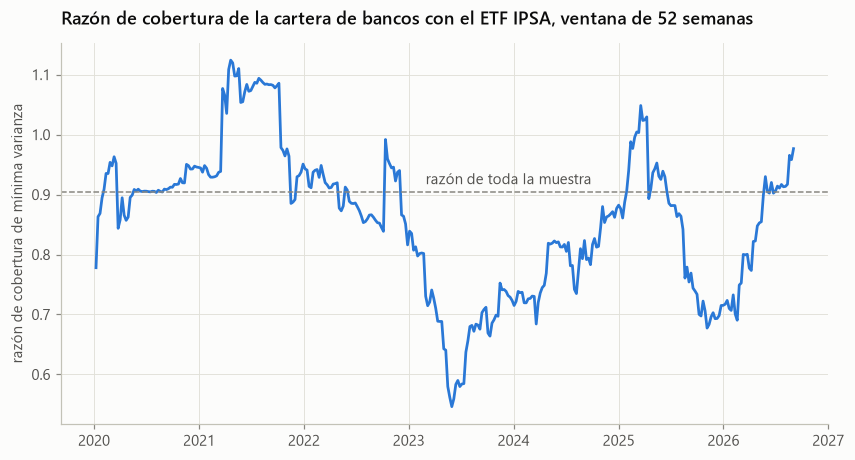

,volatilidad anual,reducción de varianza
sin cobertura,25.7%,0.0%
uno a uno,14.0%,70.5%
razón móvil de 52 semanas,14.2%,69.5%
"razón de toda la muestra, 0.90",13.8%,71.1%


In [23]:
semanal = np.log(precios).resample("W-WED").last().diff().dropna()
cartera_bancos = semanal[["BCI", "Santander", "Banco de Chile"]].mean(axis=1)
futuro = semanal["ETF IPSA"]
razon_movil = pd.Series(index=semanal.index, dtype=float)
for i in range(52, len(semanal)):
    x_v, y_v = futuro.iloc[i - 52:i], cartera_bancos.iloc[i - 52:i]
    razon_movil.iloc[i] = np.cov(x_v, y_v)[0, 1] / x_v.var()
prueba = razon_movil.dropna().index
razon_completa = np.cov(futuro, cartera_bancos)[0, 1] / futuro.var()
coberturas = {
    "sin cobertura": cartera_bancos.loc[prueba],
    "uno a uno": cartera_bancos.loc[prueba] - futuro.loc[prueba],
    "razón móvil de 52 semanas": cartera_bancos.loc[prueba] - razon_movil.loc[prueba] * futuro.loc[prueba],
    f"razón de toda la muestra, {razon_completa:.2f}": cartera_bancos.loc[prueba] - razon_completa * futuro.loc[prueba],
}
varianza_base = coberturas["sin cobertura"].var()
tabla_cobertura = pd.DataFrame({"volatilidad anual": {k: v.std() * np.sqrt(52) for k, v in coberturas.items()},
                                "reducción de varianza": {k: 1 - v.var() / varianza_base for k, v in coberturas.items()}})

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(razon_movil.index, razon_movil, color=COLORES[0], linewidth=1.8)
ax.axhline(razon_completa, color=TINTA_TENUE, linestyle="--", linewidth=1)
ax.annotate("razón de toda la muestra", (pd.Timestamp("2023-03-01"), razon_completa), xytext=(0, 5), textcoords="offset points",
            color=TINTA_SECUNDARIA)
ax.set_ylabel("razón de cobertura de mínima varianza")
ax.set_title("Razón de cobertura de la cartera de bancos con el ETF IPSA, ventana de 52 semanas")
plt.show()
tabla_cobertura.map("{:.1%}".format)

**Lectura.**

- **La cobertura elimina cerca de 70% de la varianza:** la volatilidad anual de la cartera de bancos baja de 25,7% a unos 14%.
- **La razón móvil, la única implementable en tiempo real, rinde un poco menos:** 69,5%, frente a 70,5% de la cobertura uno a uno y 71,1% de la razón estimada con toda la muestra, que usa información que no se tenía. La razón móvil oscila entre 0,55 y 1,12, y ese ruido de estimación tiene un costo.
- **Lo que queda, 30% de la varianza, es riesgo de base:** el riesgo propio de los bancos que el índice no cubre.

### Ejercicios resueltos

**Ejercicio 8.1. Contratos de mínima varianza** *(banco de ejercicios de frm-prep)*

Una cartera de $5.000.000 se cubre con futuros. La correlación entre el spot y el futuro es 0,8, la volatilidad del spot 2% y la del futuro 2,5%, y cada contrato vale $50.000. ¿Cuántos contratos y de qué lado?

In [24]:
h = frm.razon_cobertura_minima_varianza(0.8, 0.02, 0.025)
n = frm.contratos_cobertura(h, 5_000_000, 50_000)
print(f"h* = 0,8 × 2% / 2,5% = {h:.2f}; N* = {h:.2f} × 5.000.000 / 50.000 = {n:.0f}")
print("Respuesta: vender 64 contratos, porque se cubre una posición larga.")

h* = 0,8 × 2% / 2,5% = 0.64; N* = 0.64 × 5.000.000 / 50.000 = 64
Respuesta: vender 64 contratos, porque se cubre una posición larga.


**Ejercicio 8.2. Cobertura con ajuste de cola y cambio de beta** *(ejercicio propio)*

Una cartera de acciones de $20 millones tiene beta 1,2. El futuro del índice cotiza 5.000 con un multiplicador de 50. ¿Cuántos contratos hay que vender para dejar la beta en cero? ¿Y en 0,6? Si se cubriera en unidades físicas y no en valores, con una razón de 0,9 sobre 1.000 toneladas y contratos de 100 toneladas, ¿cuántos serían?

In [25]:
valor_futuro = 5_000 * 50
for objetivo in (0.0, 0.6):
    print(f"Beta objetivo {objetivo}: {frm.contratos_ajuste_beta(1.2, objetivo, 20_000_000, valor_futuro):.1f} contratos")
print(f"Respuesta: en unidades, N* = 0,9 × 1.000 / 100 = {0.9 * 1_000 / 100:.0f} contratos. Con liquidación diaria se usa el ajuste de cola: valores en vez de unidades.")

Beta objetivo 0.0: -96.0 contratos
Beta objetivo 0.6: -48.0 contratos
Respuesta: en unidades, N* = 0,9 × 1.000 / 100 = 9 contratos. Con liquidación diaria se usa el ajuste de cola: valores en vez de unidades.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad avanzada)*

Una cartera de acciones de \$10,000,000 tiene un beta de 1.0. Para subir el beta a 1.5, la gestora usa futuros de índice con un valor por contrato de \$250,000. La operación es más cercana a:

- **A.** comprar 10 contratos
- **B.** comprar 30 contratos
- **C.** vender 20 contratos
- **D.** comprar 20 contratos

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** $N = (\beta_{objetivo} - \beta_{actual})\dfrac{V}{\text{valor del contrato}} = (1.5 - 1.0)\dfrac{10{,}000{,}000}{250{,}000} = 0.5 \times 40 = 20$. Para subir el beta, se compran (largo) 20 contratos.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad intermedia)*

El riesgo de base (basis risk) en una cobertura con futuros surge porque:

- **A.** los precios spot y del futuro pueden no moverse en forma perfectamente conjunta, por lo que la base es incierta al cerrar la cobertura antes del vencimiento.
- **B.** los futuros nunca requieren margen.
- **C.** la cámara de compensación puede incumplir el contrato.
- **D.** la cobertura elimina todo el riesgo de precio con certeza.

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** La base es el precio spot menos el precio del futuro. Cuando la cobertura se cierra antes del vencimiento, la base puede diferir de lo esperado, por lo que la cobertura es imperfecta. Este riesgo de base persiste aun en una cobertura bien construida.

</details>

### Trampas frecuentes

- La razón de mínima varianza no es la correlación: es la correlación por el cociente de volatilidades.
- Una razón de cobertura estimada con toda la muestra exagera la efectividad que se habría logrado en tiempo real.
- Para bajar la beta se venden futuros; para subirla, se compran.

## FMP-9. Mercados de divisas

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Cotizaciones.** Directa (moneda local por unidad extranjera) e indirecta. Los tipos cruzados se obtienen encadenando cotizaciones; si no calzan, hay arbitraje triangular.
- **Paridad cubierta de tasas (CIP).** $F = S\,\frac{1 + r_d}{1 + r_f}$ con capitalización discreta o $F = S\,e^{(r_d - r_f)T}$ continua. Es una relación de arbitraje; se cumple casi exactamente, salvo en crisis, cuando aparece la base de divisas.
- **Paridad descubierta (UIP).** Dice que el forward es el mejor pronóstico del spot futuro, así que la moneda de tasa alta debería depreciarse. En los datos falla: es el enigma de la prima forward, que explota el carry trade.
- **Paridad del poder de compra.** En el largo plazo, la depreciación tiende a igualar el diferencial de inflación.
- **Riesgos cambiarios.** De transacción (flujos ya pactados), de traslación (estados financieros consolidados) y económico (competitividad).

### Análisis avanzado: ¿pronostica el forward el tipo de cambio?

Cada fin de mes desde 2008 se calcula el forward teórico a 3 meses con la tasa swap cámara a 90 días y la letra del Tesoro de EE.UU. a 3 meses. Luego se compara la prima forward con la depreciación efectiva del peso en los tres meses siguientes, con la regresión de Fama. Bajo UIP, la pendiente sería 1; en muchas monedas desarrolladas resulta negativa, el llamado enigma de la prima forward.

222 meses. Pendiente 1.05 (error estándar 1.37); t contra 1: 0.03; R² 0.009
Prima forward media 2.80% anual; depreciación media 3.92% anual
El forward subestimó el dólar a 3 meses en 48% de los meses; error absoluto medio 32.4 pesos


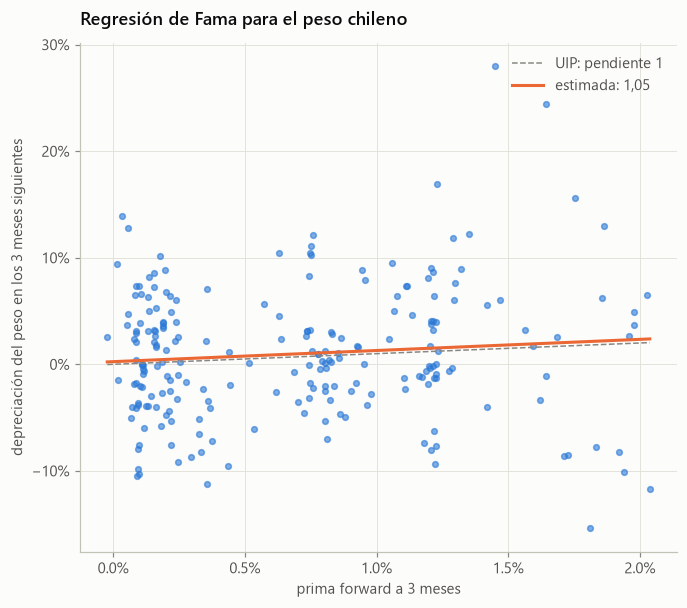

In [26]:
mensual = pd.concat({"dolar": dolar, "r_clp": swap["0.25"] / 100, "r_usd": dtb3}, axis=1, sort=True).ffill().resample("ME").last().dropna()
mensual["forward 3m"] = mensual["dolar"] * (1 + mensual["r_clp"] / 4) / (1 + mensual["r_usd"] / 4)
mensual["prima forward"] = np.log(mensual["forward 3m"] / mensual["dolar"])
mensual["depreciación siguiente"] = np.log(mensual["dolar"].shift(-3) / mensual["dolar"])
fama = mensual.dropna()
modelo_fama = sm.OLS(fama["depreciación siguiente"], sm.add_constant(fama["prima forward"])).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
pendiente = modelo_fama.params["prima forward"]
print(f"{len(fama)} meses. Pendiente {pendiente:.2f} (error estándar {modelo_fama.bse['prima forward']:.2f});"
      f" t contra 1: {(pendiente - 1) / modelo_fama.bse['prima forward']:.2f}; R² {modelo_fama.rsquared:.3f}")
print(f"Prima forward media {fama['prima forward'].mean() * 4:.2%} anual; depreciación media {fama['depreciación siguiente'].mean() * 4:.2%} anual")
error = (fama["dolar"].shift(-3) - fama["forward 3m"]).dropna()
print(f"El forward subestimó el dólar a 3 meses en {(error > 0).mean():.0%} de los meses; error absoluto medio {error.abs().mean():.1f} pesos")

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(fama["prima forward"], fama["depreciación siguiente"], s=14, color=COLORES[0], alpha=0.6)
malla = np.linspace(fama["prima forward"].min(), fama["prima forward"].max(), 10)
ax.plot(malla, malla, color=TINTA_TENUE, linestyle="--", linewidth=1, label="UIP: pendiente 1")
ax.plot(malla, modelo_fama.params["const"] + pendiente * malla, color=COLORES[1], linewidth=2,
        label=f"estimada: {pendiente:.2f}".replace(".", ","))
ax.legend(loc="upper right")
eje_porcentaje(ax, "x", decimales=1)
eje_porcentaje(ax)
ax.set_xlabel("prima forward a 3 meses")
ax.set_ylabel("depreciación del peso en los 3 meses siguientes")
ax.set_title("Regresión de Fama para el peso chileno")
plt.show()

**Lectura.**

- **El forward no pronostica al peso.** La pendiente estimada es 1,05, pero con un error estándar de 1,37: no se puede rechazar ni que sea 1, como dice la paridad descubierta, ni que sea 0. El R² es 0,9%. Con el peso no aparece el enigma clásico de una pendiente negativa, pero la prima forward tampoco explica casi nada de lo que hace el tipo de cambio.
- **El error de pronóstico es grande.** En promedio, el forward se equivocó en 32 pesos a tres meses, y subestimó al dólar en 48% de los meses, como una moneda al aire.
- **La paridad cubierta es arbitraje y sirve para valorar; la descubierta es una hipótesis sobre expectativas y no sirve para predecir.**

### Ejercicios resueltos

**Ejercicio 9.1. Paridad cubierta de tasas** *(banco de ejercicios de frm-prep)*

El tipo spot es 1,30 USD por libra. Con tasas continuas de 4% en dólares y 2% en libras, calcula el forward a un año.

In [27]:
f = frm.precio_forward(1.30, 0.04, 1.0, rendimiento=0.02)
print(f"Respuesta: F = 1,30 × e^(0,04 - 0,02) = {f:.4f} USD por libra; la libra cotiza con premio forward porque su tasa es menor.")

Respuesta: F = 1,30 × e^(0,04 - 0,02) = 1.3263 USD por libra; la libra cotiza con premio forward porque su tasa es menor.


**Ejercicio 9.2. Arbitraje triangular** *(ejercicio propio)*

Las cotizaciones son 950 pesos por dólar, 1,08 dólares por euro y 1.040 pesos por euro. ¿Hay arbitraje? Si lo hay, ¿cuánto se gana partiendo con 1.000 millones de pesos?

In [28]:
implicito = 950 * 1.08
print(f"Euro implícito en pesos: 950 × 1,08 = {implicito:.0f}, frente a 1.040 cotizado: el euro directo está caro")
euros = 1_000 / 950 / 1.08
final = euros * 1_040
print(f"Respuesta: comprar dólares, con ellos euros, y vender los euros a 1.040: {euros:.4f} millones de euros se convierten en {final:,.2f} millones de pesos, una ganancia de {final - 1_000:.2f} millones.")

Euro implícito en pesos: 950 × 1,08 = 1026, frente a 1.040 cotizado: el euro directo está caro
Respuesta: comprar dólares, con ellos euros, y vender los euros a 1.040: 0.9747 millones de euros se convierten en 1,013.65 millones de pesos, una ganancia de 13.65 millones.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad avanzada)*

El tipo spot es 1.00 y el forward a 1 año es 1.04 (USD por unidad de moneda extranjera). Si la tasa extranjera es 2%, la tasa doméstica (USD) implícita es más cercana a:

- **A.** 4.00%
- **B.** 6.00%
- **C.** 5.88%
- **D.** 6.08%

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** Paridad de tasas cubierta: $\dfrac{F}{S} = \dfrac{1 + r_d}{1 + r_f}$, entonces $1 + r_d = 1.04 \times 1.02 = 1.0608$, dando $r_d \approx 6.08\%$.

</details>

**Pregunta 2** *(banco de frm-prep, cálculo, dificultad intermedia)*

Las cotizaciones son \$1.25 por GBP y CHF 0.90 por USD. El precio en CHF de 1 GBP sin arbitraje es más cercano a:

- **A.** 1.150 CHF
- **B.** 1.389 CHF
- **C.** 1.125 CHF
- **D.** 0.720 CHF

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** Se encadenan las cotizaciones: $1\,\text{GBP} = \$1.25 = 1.25 \times 0.90\,\text{CHF} = 1.125\,\text{CHF}$.

</details>

### Trampas frecuentes

- La paridad cubierta es arbitraje; la descubierta es una hipótesis que los datos rechazan.
- La moneda con mayor tasa cotiza con descuento forward, aunque el mercado espere que se aprecie.
- Al invertir una cotización indirecta se invierte también el bid y el ask.

## FMP-10. Precio de forwards y futuros financieros

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Sin ingresos.** $F_0 = S_0 e^{rT}$. Si el forward está caro, se compra el activo con deuda y se vende el forward (cash and carry); si está barato, al revés.
- **Ingreso conocido.** $F_0 = (S_0 - I)e^{rT}$, con I el valor presente de los dividendos o cupones.
- **Rendimiento conocido.** $F_0 = S_0 e^{(r - q)T}$, para índices con dividendos o divisas con la tasa extranjera.
- **Valor de un forward vivo.** Para el largo, $f = (F_0 - K)e^{-rT}$, con $F_0$ el forward de hoy y K el precio pactado.
- **Futuros sobre índices.** El arbitraje con la canasta del índice tiene costos, así que el precio puede moverse dentro de una banda sin que convenga arbitrar.

### Análisis avanzado: valor de mercado de un forward vivo

Un exportador vendió USD 10 millones a un año por forward hace un año. Se calcula el valor de mercado diario de su posición con el dólar observado y las tasas a un año de cada día: la swap cámara en pesos y la del Tesoro de EE.UU. Se compara con la aproximación ingenua que solo mira el spot.

Inicio 24-09-2025: spot 952.87, tasas 4.53% y 3.63%, precio pactado 961.11
Valor al final: 17.2 millones de pesos (spot final 959.39).
Diferencia máxima entre el valor correcto y el ingenuo: 84.4 millones


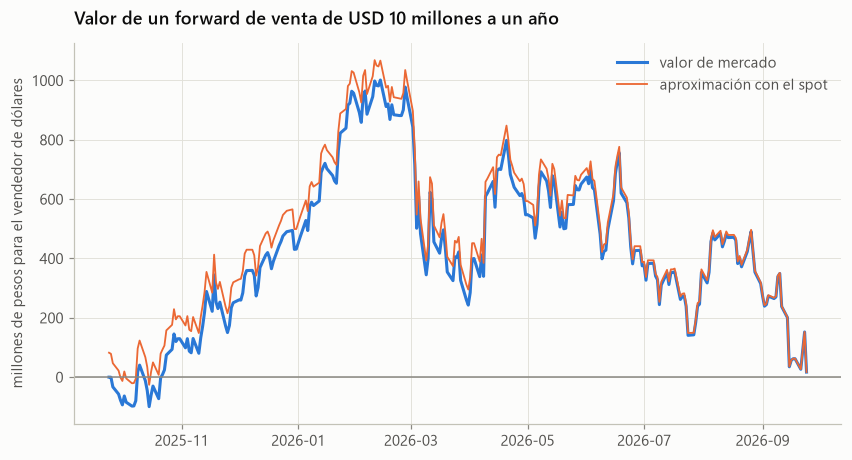

In [29]:
fin_contrato = dolar.index[-1]
inicio_contrato = dolar.loc[:fin_contrato - pd.DateOffset(years=1)].index[-1]
diario = pd.concat({"dolar": dolar, "r_clp": swap["1"] / 100, "r_usd": dgs1}, axis=1, sort=True).ffill().loc[inicio_contrato:fin_contrato].dropna()
s0, rc0, ru0 = diario.iloc[0]
pactado = s0 * (1 + rc0) / (1 + ru0)
plazo_restante = ((fin_contrato - diario.index).days / 365).to_numpy()
forward_hoy = diario["dolar"] * ((1 + diario["r_clp"]) / (1 + diario["r_usd"])) ** plazo_restante
valor_vendedor = 10 * (pactado - forward_hoy) / (1 + diario["r_clp"]) ** plazo_restante
ingenuo = 10 * (pactado - diario["dolar"])
print(f"Inicio {inicio_contrato:%d-%m-%Y}: spot {s0:,.2f}, tasas {rc0:.2%} y {ru0:.2%}, precio pactado {pactado:,.2f}")
print(f"Valor al final: {valor_vendedor.iloc[-1]:,.1f} millones de pesos (spot final {diario['dolar'].iloc[-1]:,.2f}).")
print(f"Diferencia máxima entre el valor correcto y el ingenuo: {(valor_vendedor - ingenuo).abs().max():,.1f} millones")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(valor_vendedor.index, valor_vendedor, color=COLORES[0], linewidth=2, label="valor de mercado")
ax.plot(ingenuo.index, ingenuo, color=COLORES[1], linewidth=1.2, label="aproximación con el spot")
ax.axhline(0, color=TINTA_TENUE, linewidth=1)
ax.set_ylabel("millones de pesos para el vendedor de dólares")
ax.set_title("Valor de un forward de venta de USD 10 millones a un año")
ax.legend(loc="upper right")
plt.show()

**Lectura.**

- **El forward se pactó a 961,11 y un año después el dólar terminó en 959,39:** la posición vale 17 millones de pesos a favor del exportador.
- **En el camino, su valor llegó a cerca de 1.000 millones a comienzos de 2026,** cuando el dólar bajó. Para el banco que está al otro lado, esa es la exposición de crédito que vimos en FMP-5.
- **La aproximación que solo mira el spot se equivoca hasta en 84 millones,** porque ignora el diferencial de tasas del tiempo restante y el descuento. Al vencimiento ambas coinciden.

### Ejercicios resueltos

**Ejercicio 10.1. Forward de una acción con y sin dividendos** *(banco de ejercicios de frm-prep)*

Una acción sin dividendos vale 80 y la tasa continua es 4%: ¿cuál es el forward a un año? Otra vale 60 y paga un dividendo con valor presente de 2 antes del vencimiento del forward a un año, con tasa continua de 5%: ¿cuál es su forward?

In [30]:
print(f"Sin dividendos: F = 80 × e^0,04 = {frm.precio_forward(80, 0.04, 1.0):.2f}")
print(f"Respuesta: con dividendo, F = (60 - 2) × e^0,05 = {(60 - 2) * np.exp(0.05):.2f}")

Sin dividendos: F = 80 × e^0,04 = 83.26
Respuesta: con dividendo, F = (60 - 2) × e^0,05 = 60.97


**Ejercicio 10.2. Valor de un forward vivo y arbitraje con un índice** *(ejercicio propio)*

Hace seis meses compraste un forward con precio de entrega 1.000 y vencimiento en otros seis meses. Hoy el subyacente vale 1.020, la tasa continua es 5% y el rendimiento por dividendos 2%. ¿Cuánto vale tu posición? Si el futuro a seis meses cotiza 1.040, ¿qué arbitraje haces?

In [31]:
f_hoy = frm.precio_forward(1_020, 0.05, 0.5, rendimiento=0.02)
valor = (f_hoy - 1_000) * np.exp(-0.05 * 0.5)
print(f"Forward justo hoy: 1.020 × e^((0,05 - 0,02)·0,5) = {f_hoy:.2f}; valor = ({f_hoy:.2f} - 1.000)·e^(-0,025) = {valor:.2f}")
print(f"Respuesta: el futuro a 1.040 está {1_040 - f_hoy:.2f} sobre su valor justo: vender el futuro y comprar el índice con deuda (cash and carry).")

Forward justo hoy: 1.020 × e^((0,05 - 0,02)·0,5) = 1035.42; valor = (1035.42 - 1.000)·e^(-0,025) = 34.54
Respuesta: el futuro a 1.040 está 4.58 sobre su valor justo: vender el futuro y comprar el índice con deuda (cash and carry).


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad avanzada)*

Una acción vale \$100 y pagará dividendos de \$2 en 4 meses y en 8 meses. Con una tasa compuesta continua de 5%, el precio forward a 1 año es más cercano a:

- **A.** $105.13
- **B.** $101.02
- **C.** $100.00
- **D.** $96.10

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** VP de dividendos $I = 2e^{-0.05(1/3)} + 2e^{-0.05(2/3)} = 1.967 + 1.934 = 3.90$. $F = (100 - 3.90)e^{0.05} = 96.10 \times 1.0513 \approx \$101.02$.

</details>

**Pregunta 2** *(banco de frm-prep, cálculo, dificultad avanzada)*

Estás largo en un forward con precio de entrega K = 100. El precio forward actual a 1 año es 105 y la tasa libre de riesgo continua es 5%. ¿Cuál es el valor de tu posición forward?

- **A.** $5.00
- **B.** −$4.76
- **C.** $4.76
- **D.** $0.00

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** Valor de un forward largo = (F₀ − K) × e^(−rT) = (105 − 100) × e^(−0.05) = 5 × 0.95123 = $4.76. Un forward tiene valor cero al inicio (F₀ = K) y gana valor a medida que el precio forward sube sobre el precio de entrega pactado.

</details>

### Trampas frecuentes

- El valor de un forward vivo descuenta la diferencia entre el forward de hoy y el pactado; no es la diferencia con el spot.
- Los dividendos bajan el forward: se restan del spot o entran como rendimiento q.
- Un forward que se negocia hoy vale cero; su precio de entrega es el que hace cero su valor.

## FMP-11. Forwards y futuros de commodities

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Diferencias con los activos financieros.** Los commodities se almacenan con costo, a veces se deterioran, tienen estacionalidad y no siempre se pueden vender en corto con facilidad.
- **Costo de acarreo.** $F_0 = S_0 e^{(r + u - y)T}$, con u el costo de almacenaje y y el rendimiento de conveniencia: el beneficio de tener el bien físico cuando escasea.
- **Tasa de arriendo.** En metales como el oro, el dueño puede prestar el metal y cobrar una tasa de arriendo l, que funciona como un dividendo: $F_0 = S_0 e^{(r - l)T}$.
- **Contango y backwardation.** Con inventarios abundantes, el futuro supera al spot; con escasez, el rendimiento de conveniencia sube y la curva se invierte. Renovar posiciones largas en contango tiene un costo de renovación (roll yield negativo).
- **Reversión a la media.** Muchos commodities vuelven hacia un costo de producción de largo plazo. En el modelo de Schwartz (1997), el logaritmo del precio sigue un proceso de Ornstein-Uhlenbeck, lo que genera backwardation cuando el spot está sobre su nivel de largo plazo.

### Análisis avanzado: reversión a la media del cobre y la curva forward

Se estima un AR(1) sobre el logaritmo del precio mensual del cobre desde octubre de 2012, la versión discreta del modelo de Schwartz, y se prueba si hay reversión a la media. Como con 14 años de datos la velocidad de reversión κ se estima con mucho error, la curva se proyecta con dos velocidades supuestas hacia el precio promedio del período, y se compara con la curva de costo de acarreo, con la tasa de EE.UU. y un almacenaje supuesto de 1% anual. La diferencia entre ambas es el rendimiento de conveniencia implícito.

AR(1) mensual: b = 0.9974, error estándar 0.0168. Prueba ADF: valor p 0.94
Intervalo de 95% para la vida media de un shock: desde 1.6 años hasta infinito
Precio actual 6.66 USD/lb; promedio geométrico desde 2012 3.36; volatilidad 19.6%


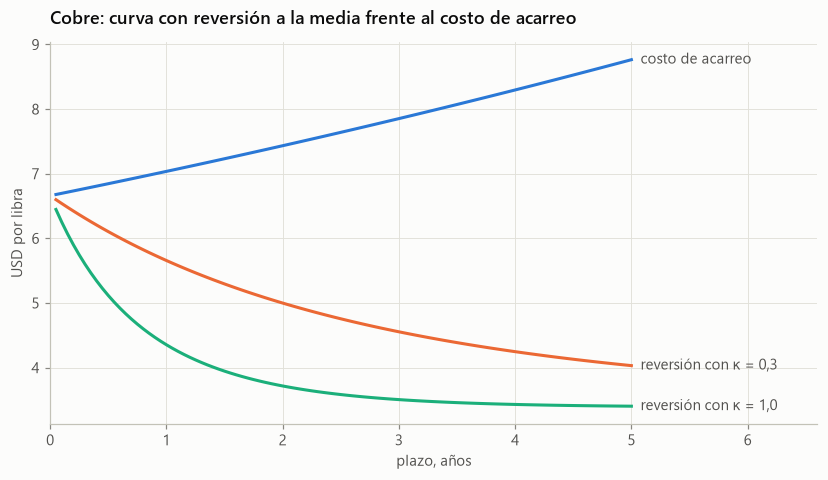

,costo de acarreo,"reversión con κ = 0,3","reversión con κ = 1,0","conveniencia implícita, reversión con κ = 0,3","conveniencia implícita, reversión con κ = 1,0"
0.5000,6.8450,6.1040,5.1160,0.2290,0.5820
1.0000,7.0360,5.6570,4.3540,0.2180,0.4800
2.0000,7.4330,4.9990,3.7160,0.1980,0.3470
3.0000,7.8520,4.5540,3.5050,0.1820,0.2690
5.0000,8.7640,4.0310,3.4030,0.1550,0.1890


In [32]:
from statsmodels.tsa.stattools import adfuller

log_cobre = np.log(cobre.resample("ME").last().dropna())
ar = sm.OLS(log_cobre.iloc[1:].to_numpy(), sm.add_constant(log_cobre.iloc[:-1].to_numpy())).fit()
b_, error_b = ar.params[1], ar.bse[1]
p_adf = adfuller(log_cobre, autolag="AIC")[1]
vida_minima = np.log(2) / (-np.log(b_ - 1.96 * error_b) * 12)
print(f"AR(1) mensual: b = {b_:.4f}, error estándar {error_b:.4f}. Prueba ADF: valor p {p_adf:.2f}")
print(f"Intervalo de 95% para la vida media de un shock: desde {vida_minima:.1f} años hasta infinito")

media_larga = float(log_cobre.mean())
sigma = float(ar.resid.std(ddof=2)) * np.sqrt(12)
x0 = float(log_cobre.iloc[-1])
print(f"Precio actual {np.exp(x0):.2f} USD/lb; promedio geométrico desde 2012 {np.exp(media_larga):.2f}; volatilidad {sigma:.1%}")

plazos = np.linspace(0.05, 5, 100)
curvas = {"costo de acarreo": np.exp(x0) * np.exp((r_usd + 0.01) * plazos)}
for kappa in (0.3, 1.0):
    esperado = media_larga + (x0 - media_larga) * np.exp(-kappa * plazos)
    varianza = sigma**2 * (1 - np.exp(-2 * kappa * plazos)) / (2 * kappa)
    curvas[f"reversión con κ = {kappa}".replace(".", ",")] = np.exp(esperado + varianza / 2)
curvas = pd.DataFrame(curvas, index=plazos.round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
for color, nombre in zip(COLORES, curvas.columns):
    ax.plot(plazos, curvas[nombre], color=color, linewidth=2)
    ax.annotate(nombre, (plazos[-1], curvas[nombre].iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center",
                color=TINTA_SECUNDARIA)
ax.set_xlim(0, 6.6)
ax.set_xlabel("plazo, años")
ax.set_ylabel("USD por libra")
ax.set_title("Cobre: curva con reversión a la media frente al costo de acarreo")
plt.show()
conveniencia = pd.DataFrame({nombre: r_usd + 0.01 - np.log(curvas[nombre] / np.exp(x0)) / curvas.index
                             for nombre in curvas.columns if nombre != "costo de acarreo"})
conveniencia.columns = [f"conveniencia implícita, {c}" for c in conveniencia.columns]
pd.concat([curvas, conveniencia], axis=1).iloc[[9, 19, 39, 59, 99]].round(3)

**Lectura.**

- **No se detecta reversión a la media.** El coeficiente del AR(1) mensual es 0,997, la prueba ADF tiene un valor p de 0,94 y el intervalo de confianza para la vida media de un shock va de 1,6 años a infinito. Con 14 años de datos, el cobre es indistinguible de un paseo aleatorio.
- **La curva cambia por completo según el supuesto.** El cobre está en 6,66 dólares, el doble de su promedio geométrico desde 2012, 3,36. Con reversión, la curva queda en fuerte backwardation y el rendimiento de conveniencia implícito a un año va de 22% a 48%. Con costo de acarreo, la curva sube.
- **Los futuros reales revelan qué curva cree el mercado.** Una backwardation indica escasez y un rendimiento de conveniencia alto. Estimar la velocidad de reversión con pocos datos es tan incierto como estimar retornos medios en el libro 1.

### Ejercicios resueltos

**Ejercicio 11.1. Forward con almacenaje** *(banco de ejercicios de frm-prep)*

El spot de un commodity es 70, la tasa continua 5% y el almacenaje 2% anual continuo. Calcula el forward a un año.

In [33]:
print(f"Respuesta: F = 70 × e^(0,05 + 0,02) = {70 * np.exp(0.07):.2f}")

Respuesta: F = 70 × e^(0,05 + 0,02) = 75.08


**Ejercicio 11.2. Rendimiento de conveniencia y tasa de arriendo** *(ejercicio propio)*

El cobre vale 4,50 USD por libra, el futuro a un año 4,40, la tasa continua 4,5% y el almacenaje 1%. ¿Qué rendimiento de conveniencia implica? Para el oro, con spot 2.400, tasa 4,5% y tasa de arriendo 0,5%, ¿cuál es el forward a dos años?

In [34]:
y = fa.rendimiento_conveniencia(4.50, 4.40, 0.045, 1.0, almacenamiento=0.01)
print(f"Rendimiento de conveniencia: 4,5% + 1% - ln(4,40/4,50) = {y:.2%}")
print(f"Respuesta: oro a dos años = 2.400 × e^((0,045 - 0,005)·2) = {2_400 * np.exp(0.04 * 2):,.2f}. La backwardation del cobre revela escasez.")

Rendimiento de conveniencia: 4,5% + 1% - ln(4,40/4,50) = 7.75%
Respuesta: oro a dos años = 2.400 × e^((0,045 - 0,005)·2) = 2,599.89. La backwardation del cobre revela escasez.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad intermedia)*

El oro spot está en \$1,500. La tasa libre de riesgo compuesta continua es 3% y los costos de almacenamiento 1% anual (continuo). El precio del futuro a 1 año es más cercano a:

- **A.** $1,561
- **B.** $1,530
- **C.** $1,500
- **D.** $1,545

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** Con el almacenamiento como costo de acarreo, $F = S_0 e^{(r+u)T} = 1500\,e^{(0.03+0.01)(1)} = 1500\,e^{0.04} = 1500 \times 1.0408 \approx 1{,}561$.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

Un inversor con una posición larga en futuros de commodities en un mercado en contango, al rolar los contratos que vencen, típicamente experimenta:

- **A.** una ganancia garantizada por convergencia.
- **B.** ningún impacto por rolar.
- **C.** un roll yield positivo.
- **D.** un roll yield negativo, porque vende el contrato que vence (más barato) y compra el siguiente (más caro).

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** En contango el contrato lejano cotiza por encima del cercano. Rolar implica vender el contrato que vence (más barato) y comprar el siguiente (más caro), lo que erosiona los retornos — un roll yield negativo. La backwardation produce un roll yield positivo.

</details>

### Trampas frecuentes

- El almacenaje sube el forward; el rendimiento de conveniencia y la tasa de arriendo lo bajan.
- En contango, renovar una posición larga cuesta: se vende barato el contrato que vence y se compra caro el siguiente.
- Un forward bajo el spot no es arbitraje si el bien no se puede pedir prestado para venderlo en corto.

## FMP-12. Mercados de opciones

*Relevancia en el examen: alta. Dificultad: intermedia.*

### Idea central

- **Tipos.** Calls y puts; americanas (se ejercen en cualquier momento) y europeas (solo al vencimiento). Dentro, en o fuera del dinero según el valor intrínseco.
- **Especificaciones.** Tamaño del contrato, fechas de vencimiento, strikes, límites de posición y de ejercicio. Los vendedores de opciones deben dejar margen.
- **Ajustes.** En un split de n por m, el strike se multiplica por m/n y el número de acciones por n/m. Los dividendos en acciones se tratan como splits; los dividendos en efectivo normales no ajustan el contrato.
- **Warrants.** Opciones emitidas por la empresa; al ejercerse crean acciones nuevas, así que su valor se diluye: aproximadamente $\frac{N}{N + M}$ veces una call equivalente.
- **Opciones para empleados (ESO).** Tienen período de consolidación, no se pueden vender y suelen ejercerse antes del vencimiento.
- **Bonos convertibles.** Un bono más una opción de convertirlo en acciones. Su valor es al menos el mayor entre el valor del bono y el de conversión.

### Análisis avanzado: warrants y bonos convertibles

Se usan el precio y la volatilidad reales de SQM-B, con términos hipotéticos. Primero, un warrant a tres años con strike 20% sobre el precio actual, emitido en proporción de 10 warrants por cada 100 acciones. Luego, un bono convertible a cinco años con cupón anual de 2%, convertible a un precio 30% sobre el actual, valorado como un bono descontado con la tasa del BCP a 5 años más un spread de 2% y una opción de conversión europea.

In [35]:
s_sqm = float(precios["SQM-B"].iloc[-1])
vol_sqm = float(np.log(precios["SQM-B"]).diff().iloc[-504:].std() * np.sqrt(252))
r_5 = float(bcp["5"].iloc[-1]) / 100
call_3a = frm.black_scholes(s_sqm, 1.2 * s_sqm, r_clp, vol_sqm, 3.0)
warrant = 100 / (100 + 10) * call_3a
print(f"SQM-B: precio {s_sqm:,.0f}, volatilidad de dos años {vol_sqm:.1%}")
print(f"Call a 3 años: {call_3a:,.0f}; warrant con dilución: {warrant:,.0f} ({warrant / s_sqm:.1%} del precio)")

bono_simple = fa.precio_bono(0.02, r_5 + 0.02, 5.0, 1)
precio_conversion = 1.3 * s_sqm
razon = 100 / precio_conversion
opcion = razon * frm.black_scholes(s_sqm, precio_conversion, np.log(1 + r_5), vol_sqm, 5.0)
convertible = pd.Series({"bono sin opción": bono_simple, "opción de conversión": opcion, "bono convertible": bono_simple + opcion,
                         "valor de conversión hoy": razon * s_sqm, "premio de conversión": (bono_simple + opcion) / (razon * s_sqm) - 1},
                        name="% del valor nominal")
print(f"Tasa BCP 5 años {r_5:.2%}; precio de conversión {precio_conversion:,.0f}; cada $1.000.000 de nominal se convierte en {razon * 10_000:.2f} acciones")
convertible.round(3).to_frame()

SQM-B: precio 65,449, volatilidad de dos años 40.9%
Call a 3 años: 17,032; warrant con dilución: 15,483 (23.7% del precio)
Tasa BCP 5 años 5.56%; precio de conversión 85,083; cada $1.000.000 de nominal se convierte en 11.75 acciones


,% del valor nominal
bono sin opción,77.5410
opción de conversión,27.3520
bono convertible,104.8930
valor de conversión hoy,76.9230
premio de conversión,0.3640


**Lectura.**

- **El warrant vale menos que la call por la dilución.** Con la volatilidad de SQM-B de 41%, la call a tres años con strike 20% sobre el precio vale 26% del precio de la acción; el warrant, 23,7%.
- **El convertible vale 104,9% del nominal:** 77,5 como bono y 27,4 por la opción de conversión. Su valor de conversión hoy es 76,9, así que el premio de conversión es 36%.
- **La volatilidad paga el cupón bajo.** La opción vale más de un cuarto del bono: por eso las empresas volátiles pueden emitir convertibles con cupones de 2%, cuando un bono sin opción les exigiría 7,6%.

### Ejercicios resueltos

**Ejercicio 12.1. Ajustes por split y dividendo en acciones** *(ejercicio propio)*

Una call sobre 100 acciones tiene strike 60. La empresa hace un split de 3 por 2. ¿Cuál es el nuevo strike y cuántas acciones cubre el contrato? ¿Y si en vez del split paga un dividendo de 10% en acciones?

In [36]:
print(f"Split 3 por 2: strike 60 × 2/3 = {60 * 2 / 3:.2f}; acciones 100 × 3/2 = {100 * 3 / 2:.0f}")
print(f"Respuesta: con un dividendo de 10% en acciones, strike 60 / 1,1 = {60 / 1.1:.2f} y acciones 100 × 1,1 = {100 * 1.1:.0f}. El valor total del contrato no cambia.")

Split 3 por 2: strike 60 × 2/3 = 40.00; acciones 100 × 3/2 = 150
Respuesta: con un dividendo de 10% en acciones, strike 60 / 1,1 = 54.55 y acciones 100 × 1,1 = 110. El valor total del contrato no cambia.


**Ejercicio 12.2. Valor de un warrant** *(ejercicio propio)*

Una empresa con 50 millones de acciones emite 5 millones de warrants. Una call equivalente vale 8 con Black-Scholes. ¿Cuánto vale cada warrant y cuánto vale toda la emisión?

In [37]:
w = 50 / (50 + 5) * 8
print(f"Respuesta: warrant = 50/55 × 8 = {w:.2f}; la emisión vale {w * 5:.1f} millones.")

Respuesta: warrant = 50/55 × 8 = 7.27; la emisión vale 36.4 millones.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad intermedia)*

Un bono convertible puede verse como:

- **A.** dos bonos de vencimientos distintos.
- **B.** una acción más un bono vendido.
- **C.** un bono simple más una opción put sobre la acción del emisor.
- **D.** un bono simple más una opción call sobre la acción del emisor.

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** Un bono convertible es un bono simple combinado con una opción call incorporada sobre las acciones del emisor: el tenedor puede convertir el bono en un número fijo de acciones. La opción sobre acciones permite que los convertibles paguen un cupón menor que la deuda simple.

</details>

**Pregunta 2** *(pregunta propia, cálculo, dificultad avanzada)*

Una empresa con 10 millones de acciones emite 2 millones de warrants. Una call europea equivalente sobre la acción, con el mismo strike y plazo, vale $6 con Black-Scholes. Con el ajuste de dilución, cada warrant vale aproximadamente:

- **A.** $7,20
- **B.** $6,00
- **C.** $5,00
- **D.** $1,00

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** Al ejercerse, los warrants crean acciones nuevas y diluyen a los accionistas. En la versión simplificada, el valor es N/(N + M) veces el de la call equivalente: 10/12 × 6 = $5,00. Una ESO se valora de forma similar, con el ajuste adicional por la vida esperada antes del ejercicio.

</details>

### Trampas frecuentes

- Los dividendos en efectivo normales no ajustan las opciones listadas; los dividendos en acciones sí.
- Un warrant vale menos que una call equivalente por la dilución.
- Un convertible nunca vale menos que su valor como bono ni que su valor de conversión.

## FMP-13. Propiedades de las opciones

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Factores.** El precio sube con S (call) o baja (put), sube con σ en ambas, sube con T casi siempre, sube con r en la call y baja en la put, y los dividendos bajan la call y suben la put.
- **Cotas.** Call europea: $\max(S - Ke^{-rT}, 0) \le c \le S$. Put europea: $\max(Ke^{-rT} - S, 0) \le p \le Ke^{-rT}$.
- **Paridad put-call.** $c + Ke^{-rT} = p + S$ para europeas sin dividendos; con dividendos, $c + Ke^{-rT} + D = p + S$. Para americanas: $S - K \le C - P \le S - Ke^{-rT}$.
- **Ejercicio anticipado.** Una call americana sin dividendos nunca conviene ejercerla antes: vale lo mismo que la europea. Una put americana muy dentro del dinero sí puede convenir, para cobrar antes el strike y ganar intereses. Con dividendos, la call puede ejercerse justo antes del dividendo si $D > K(1 - e^{-r(T-t)})$.

### Análisis avanzado: detector de arbitraje y frontera de ejercicio anticipado

Primero se arma una cadena de opciones a seis meses sobre el ETF IPSA valoradas con Black-Scholes, con la volatilidad y la TPM actuales, y se insertan dos errores de precio. Un detector revisa las cotas y la paridad put-call. Luego, con un árbol binomial de 200 pasos, se calcula la frontera de ejercicio de una put americana: el precio bajo el cual conviene ejercer en cada momento.

ETF IPSA 5,035; volatilidad 14.9%; TPM 4.50%


Strike 4,784: call bajo la cota. Residuo de paridad -113.4
Strike 5,539: paridad rota. Residuo de paridad -60.0
      strike     call      put  cota inferior call  residuo de paridad             alerta
0 4,280.0000 858.4000   7.8000            850.6000             -0.0000                   
1 4,532.0000 631.6000  27.4000            604.2000              0.0000                   
2 4,784.0000 317.8000  73.4000            357.8000           -113.4000  call bajo la cota
3 5,035.0000 270.6000 158.2000            112.4000             -0.0000                   
4 5,287.0000 154.5000 288.4000              0.0000             -0.0000                   
5 5,539.0000  80.1000 520.5000              0.0000            -60.0000       paridad rota
6 5,791.0000  37.8000 664.6000              0.0000             -0.0000                   

Put americana a un año en el dinero: 218.6; europea: 195.5; premio por ejercicio anticipado 23.1


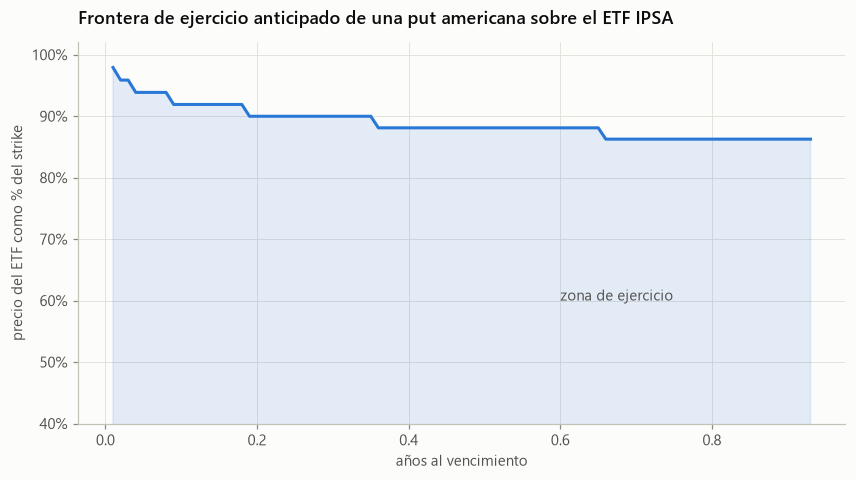

In [38]:
s_etf = float(precios["ETF IPSA"].iloc[-1])
vol_etf = float(np.log(precios["ETF IPSA"]).diff().iloc[-504:].std() * np.sqrt(252))
plazo_op = 0.5
strikes = np.round(s_etf * np.arange(0.85, 1.16, 0.05), 0)
cadena = pd.DataFrame({"strike": strikes,
                       "call": [frm.black_scholes(s_etf, k, r_clp, vol_etf, plazo_op) for k in strikes],
                       "put": [frm.black_scholes(s_etf, k, r_clp, vol_etf, plazo_op, "put") for k in strikes]})
cadena.loc[2, "call"] = max(s_etf - strikes[2] * np.exp(-r_clp * plazo_op), 0) - 40  # call bajo su cota inferior
cadena.loc[5, "put"] += 60                                                          # put cara: rompe la paridad
cadena["cota inferior call"] = np.maximum(s_etf - cadena["strike"] * np.exp(-r_clp * plazo_op), 0)
cadena["residuo de paridad"] = cadena["call"] - cadena["put"] - (s_etf - cadena["strike"] * np.exp(-r_clp * plazo_op))
cadena["alerta"] = np.where(cadena["call"] < cadena["cota inferior call"] - 0.01, "call bajo la cota",
                            np.where(cadena["residuo de paridad"].abs() > 1, "paridad rota", ""))
print(f"ETF IPSA {s_etf:,.0f}; volatilidad {vol_etf:.1%}; TPM {r_clp:.2%}")
for _, fila in cadena[cadena["alerta"] != ""].iterrows():
    print(f"Strike {fila['strike']:,.0f}: {fila['alerta']}. Residuo de paridad {fila['residuo de paridad']:+.1f}")
print(cadena.round(1).to_string())

pasos_arbol, plazo_put = 200, 1.0
dt = plazo_put / pasos_arbol
u = np.exp(vol_etf * np.sqrt(dt)); d = 1 / u
p_rn = (np.exp(r_clp * dt) - d) / (u - d)
k_put = s_etf
precios_nodo = s_etf * u ** np.arange(pasos_arbol, -1, -1) * d ** np.arange(0, pasos_arbol + 1)
valores = np.maximum(k_put - precios_nodo, 0)
frontera = []
for paso in range(pasos_arbol - 1, -1, -1):
    precios_nodo = s_etf * u ** np.arange(paso, -1, -1) * d ** np.arange(0, paso + 1)
    continuacion = np.exp(-r_clp * dt) * (p_rn * valores[:-1] + (1 - p_rn) * valores[1:])
    ejercicio = np.maximum(k_put - precios_nodo, 0)
    ejerce = (ejercicio > continuacion) & (ejercicio > 0)
    frontera.append((paso * dt, precios_nodo[ejerce].max() / k_put if ejerce.any() else np.nan))
    valores = np.maximum(continuacion, ejercicio)
frontera = pd.DataFrame(frontera, columns=["tiempo", "frontera"]).set_index("tiempo").sort_index()
frontera = frontera.iloc[::2]  # el árbol alterna nodos de paridad distinta; se toma uno de cada dos pasos
europea = frm.black_scholes(s_etf, k_put, r_clp, vol_etf, plazo_put, "put")
print(f"\nPut americana a un año en el dinero: {valores[0]:,.1f}; europea: {europea:,.1f}; premio por ejercicio anticipado {valores[0] - europea:,.1f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(plazo_put - frontera.index, frontera["frontera"], color=COLORES[0], linewidth=2)
ax.fill_between(plazo_put - frontera.index, 0, frontera["frontera"], color=COLORES[0], alpha=0.12)
ax.annotate("zona de ejercicio", (0.6, 0.6), color=TINTA_SECUNDARIA)
eje_porcentaje(ax)
ax.set_ylim(0.4, 1.02)
ax.set_xlabel("años al vencimiento")
ax.set_ylabel("precio del ETF como % del strike")
ax.set_title("Frontera de ejercicio anticipado de una put americana sobre el ETF IPSA")
plt.show()

**Lectura.**

- **El detector encuentra los dos errores.** La call de strike 4.784 cotiza 40 bajo su cota inferior: se compra la call, se vende el ETF en corto y se invierte el efectivo. La put de strike 5.539 rompe la paridad por 60: se vende la put cara y se replica con la call, el ETF y deuda.
- **El ejercicio anticipado vale.** La put americana a un año en el dinero vale 218,6, frente a 195,5 la europea: el derecho a ejercer antes vale 23,1, 12% de la europea.
- **Conviene ejercer cuando el ETF cae bajo la frontera:** alrededor de 86% del strike con un año de plazo, y cerca de 98% al acercarse el vencimiento.

### Ejercicios resueltos

**Ejercicio 13.1. Paridad put-call** *(banco de ejercicios de frm-prep)*

Una put y una call europeas a un año sobre una acción sin dividendos tienen strike igual al spot, 50. La put cuesta 4 y la tasa continua es 5%. ¿Cuánto vale la call?

In [39]:
c = 4 + 50 - 50 * np.exp(-0.05)
print(f"Respuesta: c = p + S - K·e^(-rT) = 4 + 50 - 47,56 = {c:.2f}")

Respuesta: c = p + S - K·e^(-rT) = 4 + 50 - 47,56 = 6.44


**Ejercicio 13.2. Cota inferior y ejercicio anticipado con dividendo** *(ejercicio propio)*

Una call europea a 6 meses con strike 40 sobre una acción de 45 sin dividendos cuesta 4,50, con tasa de 6%. ¿Viola la cota inferior? Luego, una call americana con strike 40 vence en 3 meses y la acción pagará un dividendo de 0,50 en 1 mes: ¿puede convenir ejercerla justo antes del dividendo?

In [40]:
cota = 45 - 40 * np.exp(-0.06 * 0.5)
print(f"Cota inferior = 45 - 40·e^(-0,03) = {cota:.2f}: la call a 4,50 está {cota - 4.5:.2f} bajo la cota.")
print("Arbitraje: comprar la call, vender la acción en corto e invertir el efectivo; al vencimiento se gana al menos esa diferencia.")
umbral = 40 * (1 - np.exp(-0.06 * 2 / 12))
print(f"Respuesta: ejercer antes del dividendo puede convenir solo si D > K(1 - e^(-r(T - t))) = {umbral:.3f}; como 0,50 > {umbral:.3f}, sí puede convenir.")

Cota inferior = 45 - 40·e^(-0,03) = 6.18: la call a 4,50 está 1.68 bajo la cota.
Arbitraje: comprar la call, vender la acción en corto e invertir el efectivo; al vencimiento se gana al menos esa diferencia.
Respuesta: ejercer antes del dividendo puede convenir solo si D > K(1 - e^(-r(T - t))) = 0.398; como 0,50 > 0.398, sí puede convenir.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad intermedia)*

Una call europea sobre una acción sin dividendos cuesta \$8. La acción vale \$100, el strike es \$100, la tasa libre de riesgo 5% y el vencimiento 1 año. Por paridad put-call, la put europea vale más cercano a:

- **A.** $3.12
- **B.** $5.00
- **C.** $8.00
- **D.** $4.88

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** Paridad put-call: $C - P = S_0 - K e^{-rT}$, entonces $P = C - S_0 + K e^{-rT} = 8 - 100 + 100 e^{-0.05} = 8 - 100 + 95.12 \approx 3.12$, es decir \$3.12.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

Para una opción call americana sobre una acción que no paga dividendos, el ejercicio anticipado es:

- **A.** óptimo solo al emitirse.
- **B.** exigido por la bolsa en cada fecha de dividendo.
- **C.** nunca óptimo, porque vender la opción captura su valor tiempo, que el ejercicio pierde.
- **D.** siempre óptimo una vez in-the-money.

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** Ejercer una call americana anticipadamente descarta el valor tiempo restante y paga el strike antes (perdiendo intereses). Sin dividendos no hay beneficio en ejercer antes, por lo que la call americana vale lo mismo que la europea. Los dividendos sí pueden hacer conveniente el ejercicio anticipado de una call.

</details>

### Trampas frecuentes

- Sin dividendos, la call americana vale lo mismo que la europea; la put americana vale más.
- La paridad put-call exacta solo vale para opciones europeas; para americanas hay una desigualdad.
- Más volatilidad sube el valor tanto de las calls como de las puts.

## FMP-14. Estrategias con opciones

*Relevancia en el examen: alta. Dificultad: intermedia.*

### Idea central

- **Con el subyacente.** La call cubierta (acción comprada y call vendida) limita la ganancia a cambio de la prima; la put protectora pone un piso. El collar combina ambas.
- **Spreads.** El bull spread compra una call de strike bajo y vende una de strike alto; el bear spread, al revés. La mariposa apuesta a que el precio quede cerca del strike central. El box spread combina un bull spread de calls y un bear spread de puts, y paga $K_2 - K_1$ con certeza: es un préstamo sintético.
- **Combinaciones.** El straddle compra call y put al mismo strike y gana con movimientos grandes; el strangle usa strikes distintos, es más barato y necesita un movimiento mayor.
- **Notas con capital protegido.** Un bono cero cupón garantiza el capital y lo que sobra compra opciones. La participación en el alza depende de las tasas y de la volatilidad.

### Análisis avanzado: nota con capital protegido y nivel de tasas

Una nota a cinco años en pesos promete devolver el capital y participar en el alza del ETF IPSA. Con cada fin de mes desde 2019, se calcula cuánto cuesta el bono cero cupón con la tasa del BCP a 5 años y qué participación permite comprar el resto con calls en el dinero, valoradas con la volatilidad histórica del ETF y un rendimiento por dividendos supuesto de 3%.

Volatilidad del ETF 21.6%. Participación: mínima 46% (06-2020), máxima 125% (08-2022), actual 114%


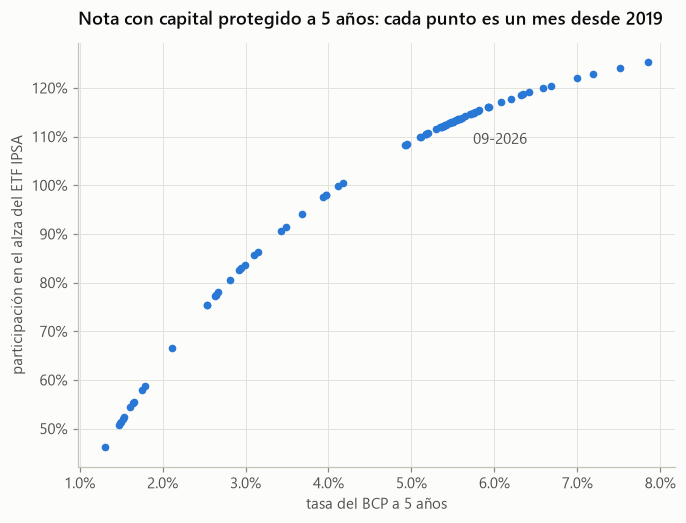

Box spread con strikes 4,532 y 5,539: cuesta 962.8 y paga 1,007.1 en un año; tasa implícita 4.50%


,tasa BCP 5 años,costo del bono cero,call por 100,participación
fecha,,,,
2019-01-31,0.0420,81.5170,18.3990,1.0050
2020-04-30,0.0170,91.6910,14.3280,0.5800
2021-07-31,0.0370,83.4860,17.5350,0.9420
2023-07-31,0.0530,77.2430,20.4090,1.1150
2024-10-31,0.0540,77.0600,20.5000,1.1190
2026-09-30,0.0560,76.2960,20.8800,1.1350


In [41]:
vol_larga = float(np.log(precios["ETF IPSA"]).diff().std() * np.sqrt(252))
bcp5 = bcp["5"].resample("ME").last().loc["2019":].dropna() / 100
filas = []
for fecha, y in bcp5.items():
    cero = 100 / (1 + y) ** 5
    call_5a = frm.black_scholes(100, 100, np.log(1 + y), vol_larga, 5.0, q=0.03)
    filas.append({"fecha": fecha, "tasa BCP 5 años": y, "costo del bono cero": cero, "call por 100": call_5a,
                  "participación": (100 - cero) / call_5a})
nota = pd.DataFrame(filas).set_index("fecha")
print(f"Volatilidad del ETF {vol_larga:.1%}. Participación: mínima {nota['participación'].min():.0%} ({nota['participación'].idxmin():%m-%Y}),"
      f" máxima {nota['participación'].max():.0%} ({nota['participación'].idxmax():%m-%Y}), actual {nota['participación'].iloc[-1]:.0%}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(nota["tasa BCP 5 años"], nota["participación"], s=16, color=COLORES[0])
ax.annotate(f"{nota.index[-1]:%m-%Y}", (nota["tasa BCP 5 años"].iloc[-1], nota["participación"].iloc[-1]), xytext=(10, -16),
            textcoords="offset points", color=TINTA_SECUNDARIA)
eje_porcentaje(ax, "x", decimales=1)
eje_porcentaje(ax)
ax.set_xlabel("tasa del BCP a 5 años")
ax.set_ylabel("participación en el alza del ETF IPSA")
ax.set_title("Nota con capital protegido a 5 años: cada punto es un mes desde 2019")
plt.show()

k1, k2 = 0.9 * s_etf, 1.1 * s_etf
caja = (frm.black_scholes(s_etf, k1, r_clp, vol_etf, 1.0) - frm.black_scholes(s_etf, k2, r_clp, vol_etf, 1.0)
        + frm.black_scholes(s_etf, k2, r_clp, vol_etf, 1.0, "put") - frm.black_scholes(s_etf, k1, r_clp, vol_etf, 1.0, "put"))
print(f"Box spread con strikes {k1:,.0f} y {k2:,.0f}: cuesta {caja:,.1f} y paga {k2 - k1:,.1f} en un año; tasa implícita {np.log((k2 - k1) / caja):.2%}")
nota.iloc[[0, 15, 30, 45, 60, -1]].round(3)

**Lectura.**

- **La participación depende sobre todo de la tasa.** Con la tasa a 5 años en 1,3% a mediados de 2020, el bono cero costaba casi 94 y la nota solo participaba en 46% del alza. Con tasas sobre 7%, como en agosto de 2022, la participación superó 120%. Hoy, con 5,6%, es 114%.
- **El box spread es un préstamo sin riesgo de mercado.** Con strikes de 90% y 110% del ETF, cuesta 962,8 y paga 1.007,1 en un año: su tasa implícita es exactamente la TPM, 4,5%.

### Ejercicios resueltos

**Ejercicio 14.1. Call cubierta y bull spread** *(ejercicio propio)*

Compras una acción a 40 y vendes una call con strike 45 a 2. ¿Cuál es la ganancia máxima y el punto de equilibrio? Luego armas un bull spread comprando una call 40 a 3 y vendiendo una call 45 a 1: ¿cuánto ganas o pierdes como máximo?

In [42]:
print(f"Call cubierta: ganancia máxima (45 - 40) + 2 = {45 - 40 + 2}; equilibrio en 40 - 2 = {40 - 2}")
precios_t = np.array([35.0, 40.0, 42.0, 45.0, 50.0])
spread = frm.pago_estrategia(precios_t, [("call", 40, 1, 3), ("call", 45, -1, 1)])
print("Resultado del bull spread en 35, 40, 42, 45 y 50:", spread)
print("Respuesta: el bull spread pierde como máximo 2, el costo neto, y gana como máximo 3, la distancia entre strikes menos el costo.")

Call cubierta: ganancia máxima (45 - 40) + 2 = 7; equilibrio en 40 - 2 = 38
Resultado del bull spread en 35, 40, 42, 45 y 50: [-2. -2.  0.  3.  3.]
Respuesta: el bull spread pierde como máximo 2, el costo neto, y gana como máximo 3, la distancia entre strikes menos el costo.


**Ejercicio 14.2. Mariposa y participación de una nota** *(ejercicio propio)*

Una mariposa compra calls con strikes 90 y 110 y vende dos calls con strike 100, con un costo neto de 2. ¿Cuál es su resultado en 85, 95, 100, 105 y 115? Luego, si un bono cero cupón a 5 años cuesta 78 por cada 100 y una call en el dinero cuesta 30, ¿qué participación ofrece una nota con capital protegido?

In [43]:
mariposa = frm.pago_estrategia(np.array([85.0, 95.0, 100.0, 105.0, 115.0]),
                               [("call", 90, 1, 0.0), ("call", 100, -2, 0.0), ("call", 110, 1, 0.0)]) - 2
print("Resultado de la mariposa:", mariposa)
print(f"Respuesta: la ganancia máxima es 8, en 100. Participación de la nota = (100 - 78) / 30 = {(100 - 78) / 30:.0%}.")

Resultado de la mariposa: [-2.  3.  8.  3. -2.]
Respuesta: la ganancia máxima es 8, en 100. Participación de la nota = (100 - 78) / 30 = 73%.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad intermedia)*

Un inversor compra una acción a \$50 y vende una call con strike \$55 por una prima de \$3. La ganancia máxima de esta covered call es:

- **A.** $2
- **B.** $8
- **C.** $3
- **D.** $5

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** La ganancia máxima ocurre cuando la acción termina en o por encima del strike y es ejercida: $(K - S_0) + \text{prima} = (55 - 50) + 3 = \$8$ por acción. Se renuncia a las ganancias por encima de \$55.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad intermedia)*

Comparado con un straddle largo, un strangle largo:

- **A.** usa opciones out-of-the-money, cuesta menos al inicio, pero necesita un movimiento mayor del subyacente para ser rentable.
- **B.** siempre es más caro de establecer.
- **C.** se arma solo con opciones call.
- **D.** gana más cuando el subyacente casi no se mueve.

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** Un strangle compra una call OTM y una put OTM (strikes distintos), por lo que es más barato que un straddle at-the-money. El costo es una zona sin ganancia más amplia: el subyacente debe moverse más antes de que la posición rinda.

</details>

### Trampas frecuentes

- El strangle es más barato que el straddle, pero necesita un movimiento mayor para ganar.
- La call cubierta tiene el mismo perfil que vender una put.
- El box spread no tiene riesgo de mercado: su valor es el strike menos el strike, descontado.

## FMP-15. Opciones exóticas

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Binarias.** Cash-or-nothing paga un monto fijo si termina dentro del dinero: $Qe^{-rT}N(d_2)$. Asset-or-nothing paga el activo: $Se^{-qT}N(d_1)$. Una call europea es asset-or-nothing menos K veces cash-or-nothing.
- **Asiáticas.** El pago depende del promedio. Son más baratas que las vainilla y difíciles de manipular. La geométrica tiene fórmula cerrada; la aritmética se valora con simulación.
- **Barreras.** Knock-out muere al tocar la barrera; knock-in nace al tocarla. Knock-in más knock-out es igual a la vainilla. Cerca de la barrera, la delta y la gamma se vuelven extremas.
- **Lookback.** Pagan respecto del mínimo o máximo de la trayectoria: comprar al mínimo o vender al máximo. Son caras.
- **Otras.** Chooser (se elige más adelante si es call o put), compuesta (opción sobre opción), forward start, cliquet, de intercambio (Margrabe) y sobre canastas.

### Análisis avanzado: exóticas sobre el dólar con fórmulas cerradas y Monte Carlo

Se valoran exóticas a un año sobre el dólar con Garman-Kohlhagen: la tasa en pesos hace de tasa libre de riesgo y la de EE.UU. de rendimiento del activo. Las que tienen fórmula se comparan con 20.000 trayectorias diarias. La de intercambio usa dos acciones del IPSA, normalizadas a 100.

Correlación Banco de Chile - Santander 0.59; volatilidades 22.7% y 19.9%


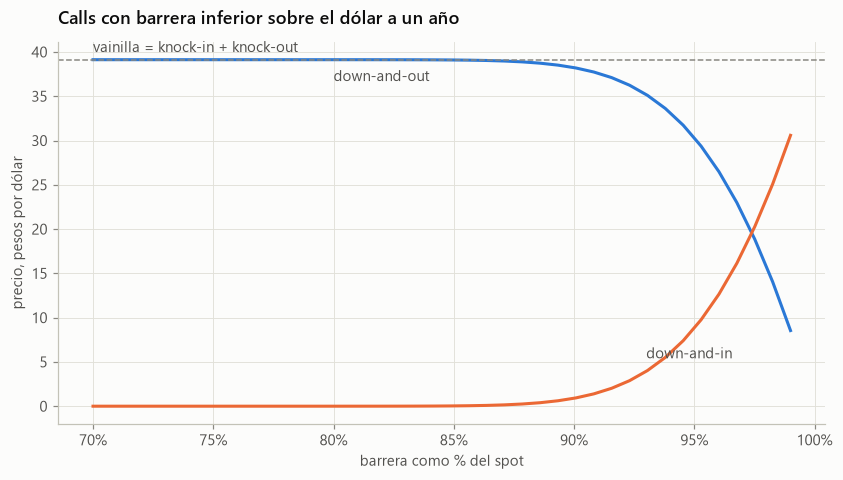

,fórmula,Monte Carlo,% de la vainilla
call vainilla,39.1200,38.8000,0.9900
binaria: paga 100 pesos,45.8000,45.9100,1.1700
"down-and-out, barrera 883",37.0300,36.6600,0.9400
asiática geométrica,22.2100,22.0500,0.5600
"asiática aritmética, con control",NaN,22.6600,0.5800
lookback de strike flotante,NaN,72.0400,1.8400
chooser a 6 meses,66.7200,NaN,1.7100
intercambio Santander por Banco de Chile,7.8000,NaN,NaN


In [44]:
k = spot
vainilla = frm.black_scholes(spot, k, r_clp, vol_usd, 1.0, q=r_usd)
pasos_mc, n_mc = 252, 20_000
rutas = fa.simular_gbm(spot, r_clp - r_usd, vol_usd, 1.0, pasos_mc, n_mc, semilla=7)
final = rutas[:, -1]
descuento = np.exp(-r_clp)
barrera = 0.92 * spot
barrera_discreta = barrera * np.exp(-0.5826 * vol_usd * np.sqrt(1 / pasos_mc))  # Broadie, Glasserman y Kou
promedio_arit = rutas[:, 1:].mean(axis=1)
promedio_geom = np.exp(np.log(rutas[:, 1:]).mean(axis=1))
exacto_geom = fa.call_asiatica_geometrica_discreta(spot, k, r_clp, vol_usd, 1.0, pasos_mc, q=r_usd)
pago_arit, pago_geom = np.maximum(promedio_arit - k, 0), np.maximum(promedio_geom - k, 0)
b_cv = np.cov(pago_arit, pago_geom)[0, 1] / pago_geom.var(ddof=1)
asiatica_cv = descuento * (pago_arit - b_cv * (pago_geom - exacto_geom / descuento))
t1 = 0.5
chooser = vainilla + np.exp(-r_usd * (1 - t1)) * frm.black_scholes(spot, k * np.exp(-(r_clp - r_usd) * (1 - t1)), r_clp, vol_usd, t1, "put", q=r_usd)
r_bancos = np.log(precios[["Banco de Chile", "Santander"]]).diff().dropna().iloc[-504:]
vol_b, vol_s = r_bancos.std() * np.sqrt(252)
rho_bs = r_bancos.corr().iloc[0, 1]

tabla_exoticas = pd.DataFrame({
    "fórmula": [vainilla, fa.opcion_binaria(spot, k, r_clp, vol_usd, 1.0, "call", "efectivo", q=r_usd, monto=100),
                fa.call_barrera_abajo(spot, k, barrera_discreta, r_clp, vol_usd, 1.0, q=r_usd),
                fa.call_asiatica_geometrica_discreta(spot, k, r_clp, vol_usd, 1.0, pasos_mc, q=r_usd), np.nan, np.nan, chooser,
                fa.opcion_intercambio(100, 100, vol_b, vol_s, rho_bs, 1.0)],
    "Monte Carlo": [descuento * np.maximum(final - k, 0).mean(), descuento * 100 * (final > k).mean(),
                    descuento * np.where(rutas.min(axis=1) > barrera, np.maximum(final - k, 0), 0).mean(),
                    descuento * pago_geom.mean(), asiatica_cv.mean(), descuento * (final - rutas.min(axis=1)).mean(), np.nan, np.nan],
}, index=["call vainilla", "binaria: paga 100 pesos", f"down-and-out, barrera {barrera:,.0f}", "asiática geométrica",
          "asiática aritmética, con control", "lookback de strike flotante", "chooser a 6 meses", "intercambio Santander por Banco de Chile"])
tabla_exoticas["% de la vainilla"] = tabla_exoticas["Monte Carlo"].fillna(tabla_exoticas["fórmula"]) / vainilla
tabla_exoticas.loc[tabla_exoticas.index[-1], "% de la vainilla"] = np.nan  # otro subyacente
print(f"Correlación Banco de Chile - Santander {rho_bs:.2f}; volatilidades {vol_b:.1%} y {vol_s:.1%}")

barreras = spot * np.linspace(0.70, 0.99, 40)
fuera = [fa.call_barrera_abajo(spot, k, h, r_clp, vol_usd, 1.0, q=r_usd) for h in barreras]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(barreras / spot, fuera, color=COLORES[0], linewidth=2)
ax.plot(barreras / spot, vainilla - np.array(fuera), color=COLORES[1], linewidth=2)
ax.axhline(vainilla, color=TINTA_TENUE, linestyle="--", linewidth=1)
ax.annotate("vainilla = knock-in + knock-out", (0.70, vainilla), xytext=(0, 5), textcoords="offset points", color=TINTA_SECUNDARIA)
ax.annotate("down-and-out", (0.80, fuera[13]), xytext=(0, -14), textcoords="offset points", color=TINTA_SECUNDARIA)
ax.annotate("down-and-in", (0.93, vainilla - fuera[31]), xytext=(0, 8), textcoords="offset points", color=TINTA_SECUNDARIA)
eje_porcentaje(ax, "x")
ax.set_xlabel("barrera como % del spot")
ax.set_ylabel("precio, pesos por dólar")
ax.set_title("Calls con barrera inferior sobre el dólar a un año")
plt.show()
tabla_exoticas.round(2)

**Lectura.**

- **Las fórmulas cerradas y Monte Carlo coinciden** dentro del error de simulación: 39,1 y 38,8 en la vainilla, 37,0 y 36,7 en la barrera y 22,2 y 22,1 en la asiática geométrica.
- **Promediar y poner barreras abarata.** La asiática aritmética vale 58% de la vainilla. La down-and-out con barrera en 92% del spot vale 94%: con una volatilidad de 10,7%, el dólar rara vez cae 8%.
- **Elegir después o comprar al mínimo cuesta caro.** La lookback de strike flotante vale 1,84 veces la vainilla y la chooser, 1,71 veces.
- **El gráfico muestra la paridad:** knock-in más knock-out siempre es la vainilla, y la knock-out pierde valor rápido cuando la barrera se acerca al spot.

### Ejercicios resueltos

**Ejercicio 15.1. Paridad entre knock-in y knock-out** *(ejercicio propio)*

Una call vainilla vale 8,50 y una call down-and-out con la misma barrera, strike y plazo vale 6,20. ¿Cuánto vale la down-and-in? Comprueba la relación con las fórmulas del módulo para S = K = 100, barrera 90, r = 5%, σ = 25% y T = 1.

In [45]:
print(f"Down-and-in = 8,50 - 6,20 = {8.50 - 6.20:.2f}")
entrada = fa.call_barrera_abajo(100, 100, 90, 0.05, 0.25, 1.0, variante="in")
salida = fa.call_barrera_abajo(100, 100, 90, 0.05, 0.25, 1.0, variante="out")
print(f"Respuesta: con las fórmulas, in {entrada:.4f} + out {salida:.4f} = {entrada + salida:.4f} = vainilla {frm.black_scholes(100, 100, 0.05, 0.25, 1.0):.4f}")

Down-and-in = 8,50 - 6,20 = 2.30
Respuesta: con las fórmulas, in 3.2248 + out 9.1112 = 12.3360 = vainilla 12.3360


**Ejercicio 15.2. Binarias y opción de intercambio** *(ejercicio propio)*

Con S = K = 50, r = 10%, σ = 40% y T = 1, valora una cash-or-nothing que paga 10 y una asset-or-nothing, y verifica que la call europea es la segunda menos K veces la cash-or-nothing unitaria. Luego, valora el derecho a cambiar un activo B de 100 por un activo A de 100, con volatilidades de 30% y 20% y correlación 0,5, a un año.

In [46]:
efectivo = fa.opcion_binaria(50, 50, 0.10, 0.40, 1.0, "call", "efectivo", monto=10)
activo = fa.opcion_binaria(50, 50, 0.10, 0.40, 1.0, "call", "activo")
print(f"Cash-or-nothing por 10: {efectivo:.4f}; asset-or-nothing: {activo:.4f}")
print(f"Asset-or-nothing - 50 × cash-or-nothing unitaria = {activo - 50 * efectivo / 10:.4f} = call {frm.black_scholes(50, 50, 0.10, 0.40, 1.0):.4f}")
print(f"Respuesta: la opción de intercambio vale {fa.opcion_intercambio(100, 100, 0.30, 0.20, 0.5, 1.0):.4f}; su volatilidad efectiva es raíz(0,09 + 0,04 - 0,06) = {np.sqrt(0.07):.1%}.")

Cash-or-nothing por 10: 4.7046; asset-or-nothing: 33.6822
Asset-or-nothing - 50 × cash-or-nothing unitaria = 10.1592 = call 10.1592
Respuesta: la opción de intercambio vale 10.5243; su volatilidad efectiva es raíz(0,09 + 0,04 - 0,06) = 26.5%.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad intermedia)*

Una opción asiática (de precio promedio) usa el precio promedio del subyacente durante la vida de la opción para determinar el pago. Comparadas con una opción vanilla, las opciones asiáticas son:

- **A.** Más baratas porque el promediado reduce la volatilidad del subyacente efectivo
- **B.** Solo disponibles OTC en teoría pero no en la práctica
- **C.** Idénticas en valor, ya que ambas dependen del precio final
- **D.** Más caras porque el promediado reduce la incertidumbre

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** Las opciones asiáticas suelen ser más baratas que las vanilla. Promediar el precio en el tiempo reduce la volatilidad efectiva del pago comparado con una única observación al vencimiento. Este promediado suaviza los picos temporales de precio.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad intermedia)*

Una opción con barrera knock-out es aquella que:

- **A.** no tiene precio de ejercicio.
- **B.** solo puede ejercerse en la barrera.
- **C.** siempre paga un monto fijo.
- **D.** deja de existir (se vuelve sin valor) si el subyacente alcanza un nivel de barrera especificado.

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** Las opciones con barrera son dependientes de la trayectoria. Una knock-out se extingue si se toca la barrera; una knock-in solo se activa al alcanzarla. Como pueden desaparecer o no activarse, las opciones con barrera son más baratas que vanilla idénticas.

</details>

### Trampas frecuentes

- Knock-in más knock-out es igual a la vainilla, con la misma barrera, strike y plazo.
- Una asiática es más barata que la vainilla porque el promedio es menos volátil que el precio final.
- En la opción de intercambio, la volatilidad relevante baja con la correlación entre los activos.
- Con monitoreo discreto, una barrera se toca menos que con monitoreo continuo: se corrige desplazando la barrera.

## FMP-16. Propiedades de las tasas de interés

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Capitalización.** $R_c = m\ln(1 + R_m/m)$ y $R_m = m(e^{R_c/m} - 1)$. La tasa efectiva anual es $(1 + R_m/m)^m - 1$.
- **Tasas cero y factores de descuento.** El precio de un bono es la suma de sus flujos descontados con la tasa cero de cada plazo. El rendimiento al vencimiento es la tasa única que reproduce el precio.
- **Tasa par.** El cupón que hace que el bono valga 100: $c = m(1 - d_n)/\sum_i d_i$.
- **Bootstrapping.** Se obtienen los factores de descuento plazo por plazo a partir de instrumentos con cupón.
- **Tasas forward.** $R_F = (R_2T_2 - R_1T_1)/(T_2 - T_1)$ con capitalización continua. Un FRA fija hoy la tasa de un período futuro; su valor es el nocional por la diferencia entre la tasa pactada y la forward, descontada.
- **Teorías.** Expectativas (las forward predicen las tasas futuras), segmentación de mercado y preferencia por liquidez, que agrega una prima por plazo y explica por qué la curva suele tener pendiente positiva.

### Análisis avanzado: curva cero de la tasa swap cámara por bootstrapping

Se construye la curva cero en pesos con las tasas swap cámara del último día disponible. Hasta un año, el swap paga al vencimiento y su tasa se trata como tasa simple; desde 18 meses paga cupones semestrales, así que sus tasas son tasas par. Se interpolan linealmente las tasas par en una rejilla semestral y se aplica el bootstrapping. Luego se prueba la teoría de expectativas: se compara la tasa forward a un año dentro de un año con la tasa a un año que efectivamente hubo un año después.

Curva del 23-09-2026. Verificación: un bono par a 10 años vale 100.0000


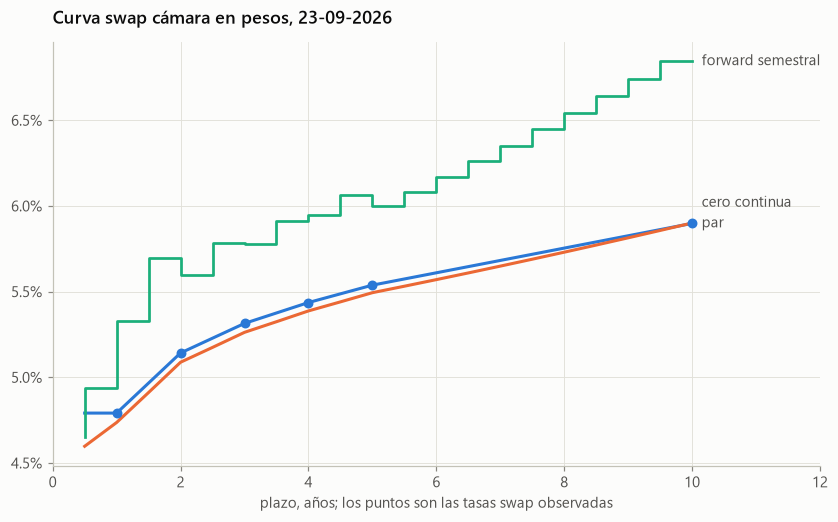


Teoría de expectativas, 213 meses: error medio del forward +0.43%; error absoluto medio 1.53%; el forward superó a la tasa realizada en 70% de los meses
Regresión de Fama-Bliss: pendiente 1.16 (error estándar 0.20); bajo expectativas puras sería 1


,factor de descuento,tasa par,tasa cero continua,forward semestral
plazo,,,,
0.5000,0.9773,0.0479,0.0460,0.0465
1.0000,0.9537,0.0479,0.0474,0.0493
2.0000,0.9032,0.0514,0.0509,0.0570
3.0000,0.8540,0.0532,0.0526,0.0578
5.0000,0.7598,0.0554,0.0549,0.0607
7.0000,0.6734,0.0568,0.0565,0.0626
10.0000,0.5543,0.0590,0.0590,0.0684


In [47]:
fecha_curva = swap.dropna().index[-1]
tasas_swap = swap.loc[fecha_curva] / 100
df_06m = 1 / (1 + tasas_swap["0.5"] * 0.5 * 365 / 360)
df_1a = 1 / (1 + tasas_swap["1"] * 365 / 360)
par_1a = 2 * (1 - df_1a) / (df_06m + df_1a)
nodos = np.array([1.0, 2.0, 3.0, 4.0, 5.0, 10.0])
par_nodos = np.array([par_1a, tasas_swap["2"], tasas_swap["3"], tasas_swap["4"], tasas_swap["5"], tasas_swap["10"]])
plazos_curva = np.arange(1, 21) / 2
par_rejilla = np.interp(plazos_curva, nodos, par_nodos)
factores = fa.bootstrap_par(plazos_curva, par_rejilla, 2, factores_conocidos=[df_06m, df_1a])
ceros = fa.tasas_cero_continuas(plazos_curva, factores)
forwards = fa.forwards_periodo(plazos_curva, factores)
curva = pd.DataFrame({"factor de descuento": factores, "tasa par": par_rejilla, "tasa cero continua": ceros,
                      "forward semestral": forwards}, index=pd.Index(plazos_curva, name="plazo"))
print(f"Curva del {fecha_curva:%d-%m-%Y}. Verificación: un bono par a 10 años vale {100 * (par_rejilla[-1] / 2 * factores.sum() + factores[-1]):.4f}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(plazos_curva, curva["tasa par"], color=COLORES[0], linewidth=2)
ax.plot(plazos_curva, curva["tasa cero continua"], color=COLORES[1], linewidth=2)
ax.step(plazos_curva, curva["forward semestral"], where="pre", color=COLORES[2], linewidth=1.8)
ax.scatter(nodos, par_nodos, color=COLORES[0], s=30, zorder=3)
posiciones_curva = {"par": curva["tasa par"].iloc[-1], "cero continua": curva["tasa cero continua"].iloc[-1],
                    "forward semestral": curva["forward semestral"].iloc[-1]}
for nombre, y_et in separar_etiquetas(posiciones_curva, 0.0012).items():
    ax.annotate(nombre, (10.15, y_et), va="center", color=TINTA_SECUNDARIA)
eje_porcentaje(ax, decimales=1)
ax.set_xlim(0, 12)
ax.set_xlabel("plazo, años; los puntos son las tasas swap observadas")
ax.set_title(f"Curva swap cámara en pesos, {fecha_curva:%d-%m-%Y}")
fig.savefig(FIGURAS / "curva_swap_bootstrap.png", bbox_inches="tight")
plt.show()

swap_m = swap[["1", "2"]].resample("ME").last().dropna() / 100
swap_m["forward 1a en 1a"] = (1 + swap_m["2"]) ** 2 / (1 + swap_m["1"]) - 1
swap_m["tasa 1a un año después"] = swap_m["1"].shift(-12)
prueba_exp = swap_m.dropna()
error_fwd = prueba_exp["forward 1a en 1a"] - prueba_exp["tasa 1a un año después"]
fama_bliss = sm.OLS(prueba_exp["tasa 1a un año después"] - prueba_exp["1"],
                    sm.add_constant(prueba_exp["forward 1a en 1a"] - prueba_exp["1"])).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
print(f"\nTeoría de expectativas, {len(prueba_exp)} meses: error medio del forward {error_fwd.mean():+.2%}; error absoluto medio {error_fwd.abs().mean():.2%};"
      f" el forward superó a la tasa realizada en {(error_fwd > 0).mean():.0%} de los meses")
print(f"Regresión de Fama-Bliss: pendiente {fama_bliss.params.iloc[1]:.2f} (error estándar {fama_bliss.bse.iloc[1]:.2f}); bajo expectativas puras sería 1")
curva.iloc[[0, 1, 3, 5, 9, 13, 19]].round(5)

**Lectura.**

- **La curva tiene pendiente positiva:** la tasa par sube de 4,8% a un año a 5,9% a 10 años. La tasa cero queda bajo la par y la forward sobre ambas, como corresponde a una curva creciente. Un bono par a 10 años vale exactamente 100 con los factores obtenidos.
- **Los saltos de la forward revelan los quiebres de la interpolación lineal** entre nodos. En la práctica se usan interpolaciones más suaves o modelos como Nelson-Siegel.
- **Las forwards contienen una prima por plazo.** Desde 2008, la forward a un año dentro de un año superó a la tasa efectiva un año después en 70% de los meses, por 0,43 puntos en promedio. La pendiente de Fama-Bliss, 1,16, es cercana a 1: las forwards anticipan las tasas futuras, más una prima positiva, como dice la teoría de preferencia por liquidez.

### Ejercicios resueltos

**Ejercicio 16.1. Tasa efectiva y FRA** *(banco de ejercicios de frm-prep)*

Una tasa nominal de 8% se capitaliza trimestralmente: ¿cuál es la tasa efectiva anual y su equivalente continua? Luego, una empresa está larga en un FRA a 3 meses al 3% sobre 10 millones, y al liquidar la tasa a 3 meses fija en 4%: ¿cuánto recibe, sin descontar y descontado?

In [48]:
efectiva = (1 + 0.08 / 4) ** 4 - 1
print(f"Tasa efectiva = (1 + 0,02)^4 - 1 = {efectiva:.2%}; continua = 4·ln(1,02) = {frm.tasa_continua(0.08, 4):.4%}")
pago = (0.04 - 0.03) * 10_000_000 * 0.25
print(f"Respuesta: pago del FRA = (4% - 3%) × 10.000.000 × 0,25 = {pago:,.0f}; descontado un trimestre al 4%: {pago / (1 + 0.04 * 0.25):,.2f}")

Tasa efectiva = (1 + 0,02)^4 - 1 = 8.24%; continua = 4·ln(1,02) = 7.9211%
Respuesta: pago del FRA = (4% - 3%) × 10.000.000 × 0,25 = 25,000; descontado un trimestre al 4%: 24,752.48


**Ejercicio 16.2. Forward desde tasas cero y valor de un FRA** *(ejercicio propio)*

Las tasas cero continuas a 1 y 2 años son 4% y 5%. ¿Cuál es la forward entre el año 1 y el 2? Un FRA pactado al 5,5% para ese período sobre un nocional de 100 millones, con pago al final del año 2: ¿cuánto vale para quien recibe la tasa fija?

In [49]:
fwd = (0.05 * 2 - 0.04 * 1) / (2 - 1)
fwd_simple = np.exp(fwd) - 1
valor = 100 * (0.055 - fwd_simple) * np.exp(-0.05 * 2)
print(f"Forward continua = (5%·2 - 4%·1) / 1 = {fwd:.2%}; equivalente anual {fwd_simple:.4%}")
print(f"Respuesta: quien recibe fijo gana 5,5% - {fwd_simple:.4%} sobre 100 millones, descontado 2 años: {valor:.4f} millones.")

Forward continua = (5%·2 - 4%·1) / 1 = 6.00%; equivalente anual 6.1837%
Respuesta: quien recibe fijo gana 5,5% - 6.1837% sobre 100 millones, descontado 2 años: -0.6186 millones.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad avanzada)*

Las tasas spot anuales a 2 y 3 años son 4% y 5%. La tasa forward a 1 año para el año tres es más cercana a:

- **A.** 7.02%
- **B.** 5.00%
- **C.** 7.00%
- **D.** 6.00%

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** $(1+f) = \dfrac{(1.05)^3}{(1.04)^2} = \dfrac{1.157625}{1.0816} = 1.0702$, entonces $f \approx 7.02\%$.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

El bootstrapping se usa para:

- **A.** calcular la duración de un bono.
- **B.** estimar el beta de una acción por regresión.
- **C.** valuar una opción con simulación.
- **D.** derivar tasas cupón cero (spot) de forma secuencial a partir de los precios de bonos con cupón.

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** El bootstrapping extrae la curva de tasas spot un vencimiento a la vez: el instrumento más corto da la primera tasa spot, que se usa para despejar el siguiente bono, y así sucesivamente. La curva cero resultante se usa para descontar flujos de forma consistente.

</details>

### Trampas frecuentes

- Con curva creciente, la forward queda sobre la tasa cero y esta sobre la tasa par.
- La teoría de expectativas puras no explica la pendiente positiva habitual; la preferencia por liquidez sí.
- Antes de comparar tasas, hay que llevarlas a la misma capitalización y conteo de días.

## FMP-17. Bonos corporativos

*Relevancia en el examen: alta. Dificultad: intermedia.*

### Idea central

- **Características.** Escritura de emisión (indenture), covenants, garantías, prelación (senior, subordinado), rescate anticipado (callable), venta anticipada (putable), convertibilidad y fondos de amortización.
- **Rendimientos.** Corriente (cupón sobre precio), al vencimiento, al rescate y al peor (el mínimo entre el rendimiento al vencimiento y los rendimientos a cada fecha de rescate).
- **Spread de crédito.** Diferencia sobre un bono libre de riesgo del mismo plazo. El Z-spread se suma a toda la curva cero; el OAS descuenta además el valor de las opciones incluidas.
- **Incumplimiento.** Recuperación según prelación y ciclo económico; la pérdida esperada anual es aproximadamente PD × (1 − R).
- **Enigma del spread.** Los spreads observados superan con creces la pérdida esperada histórica: incluyen primas por riesgo sistemático, liquidez e impuestos. Por eso la intensidad implícita en el spread, $\lambda = s/(1-R)$, es mucho mayor que la frecuencia histórica de incumplimiento.

### Análisis avanzado: el enigma del spread de crédito

Se usa el spread diario de los bonos corporativos Baa de Moody's sobre el bono del Tesoro de EE.UU. a 10 años (serie BAA10Y de FRED) desde 1986. Se compara con la pérdida esperada que implicaría una PD anual de 0,25%, del orden de los promedios históricos para emisores Baa, con recuperación de 40%.

Máximo el 04-12-2008; mínimo el 20-03-1989. La pérdida esperada explica 7% del spread medio.
La intensidad implícita, 3.78%, es 15 veces la PD histórica supuesta.


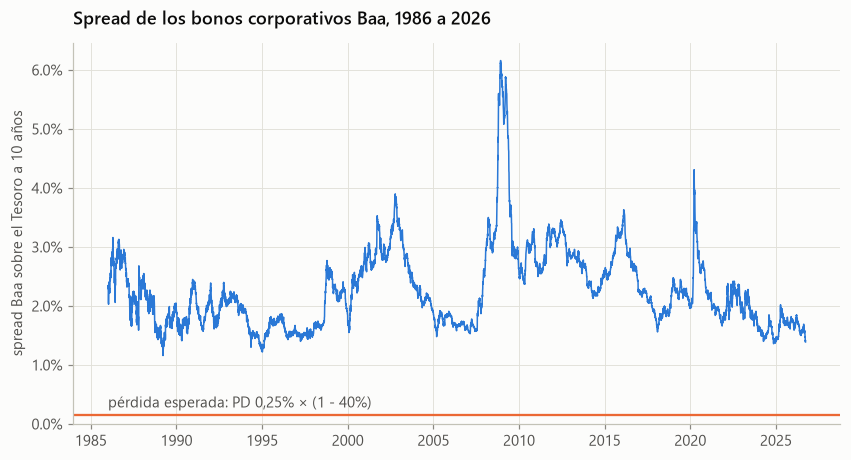

,valor
spread medio,2.27%
spread mediano,2.13%
mínimo,1.16%
máximo,6.16%
pérdida esperada supuesta,0.15%
intensidad implícita en el spread medio,3.78%


In [50]:
baa = datos.cargar_fred("BAA10Y", DATOS / "fred") / 100
pd_baa, recuperacion = 0.0025, 0.40
perdida_esperada = pd_baa * (1 - recuperacion)
lambda_rn = baa.mean() / (1 - recuperacion)
resumen_baa = pd.Series({"spread medio": baa.mean(), "spread mediano": baa.median(), "mínimo": baa.min(), "máximo": baa.max(),
                         "pérdida esperada supuesta": perdida_esperada, "intensidad implícita en el spread medio": lambda_rn})
print(f"Máximo el {baa.idxmax():%d-%m-%Y}; mínimo el {baa.idxmin():%d-%m-%Y}. La pérdida esperada explica {perdida_esperada / baa.mean():.0%} del spread medio.")
print(f"La intensidad implícita, {lambda_rn:.2%}, es {lambda_rn / pd_baa:.0f} veces la PD histórica supuesta.")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(baa.index, baa, color=COLORES[0], linewidth=1)
ax.axhline(perdida_esperada, color=COLORES[1], linewidth=1.5)
ax.annotate("pérdida esperada: PD 0,25% × (1 - 40%)", (baa.index[0], perdida_esperada), xytext=(0, 5), textcoords="offset points",
            color=TINTA_SECUNDARIA)
eje_porcentaje(ax, decimales=1)
ax.set_ylim(0, None)
ax.set_ylabel("spread Baa sobre el Tesoro a 10 años")
ax.set_title("Spread de los bonos corporativos Baa, 1986 a 2026")
plt.show()
resumen_baa.map("{:.2%}".format).to_frame("valor")

**Lectura.**

- **La pérdida esperada explica una fracción mínima del spread.** El spread Baa promedió 2,27% desde 1986, entre 1,16% y 6,16% en diciembre de 2008. Una PD de 0,25% con recuperación de 40% da una pérdida esperada de 0,15%, apenas 7% del spread medio.
- **La intensidad implícita en el spread, 3,8%, es 15 veces la PD supuesta.** La diferencia es la prima por riesgo sistemático, porque los incumplimientos llegan juntos en las recesiones, más la iliquidez de los bonos corporativos y, en EE.UU., los impuestos.
- **Para el examen:** las probabilidades neutrales al riesgo, implícitas en los precios, sirven para valorar; las históricas, para medir el riesgo.

### Ejercicios resueltos

**Ejercicio 17.1. Precios y rendimiento corriente** *(banco de ejercicios de frm-prep)*

Calcula el precio de un bono cero cupón que paga 100 en 4 años con rendimiento anual de 5%; el de un bono a 3 años con cupón anual de 5% y rendimiento de 6%; y el rendimiento corriente de un bono con cupón de 7 que cotiza a 96.

In [51]:
print(f"Cero cupón: {fa.precio_bono(0.0, 0.05, 4, 1):.2f}")
print(f"Bono a 3 años al 5% con rendimiento de 6%: {fa.precio_bono(0.05, 0.06, 3, 1):.2f}")
print(f"Respuesta: rendimiento corriente = 7 / 96 = {7 / 96:.2%}")

Cero cupón: 82.27
Bono a 3 años al 5% con rendimiento de 6%: 97.33
Respuesta: rendimiento corriente = 7 / 96 = 7.29%


**Ejercicio 17.2. Probabilidades neutrales al riesgo y reales** *(ejercicio propio)*

Un bono corporativo a 5 años rinde 2,4% sobre el libre de riesgo, con recuperación esperada de 40%. ¿Qué probabilidad de incumplimiento a 5 años implica el mercado? Si la frecuencia histórica de incumplimiento a 5 años de emisores similares es 1,5%, ¿cuánto del spread es prima de riesgo?

In [52]:
lam = fa.intensidad_desde_spread(0.024, 0.40)
pd_neutral = 1 - np.exp(-lam * 5)
spread_historico = -np.log(1 - 0.015) / 5 * (1 - 0.40)
print(f"λ = 2,4% / 60% = {lam:.2%}; PD neutral al riesgo a 5 años = {pd_neutral:.1%}, frente a 1,5% histórica")
print(f"Respuesta: la pérdida esperada histórica justifica un spread de {spread_historico:.2%}; el resto, {0.024 - spread_historico:.2%}, es prima por riesgo y liquidez.")

λ = 2,4% / 60% = 4.00%; PD neutral al riesgo a 5 años = 18.1%, frente a 1,5% histórica
Respuesta: la pérdida esperada histórica justifica un spread de 0.18%; el resto, 2.22%, es prima por riesgo y liquidez.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad avanzada)*

Un bono a 3 años paga un cupón anual de 6% en forma semestral sobre \$100 de nominal. Si la YTM es 8% (anual, composición semestral), su precio es más cercano a:

- **A.** $96.00
- **B.** $92.50
- **C.** $94.76
- **D.** $100.00

<details>
<summary>Ver respuesta</summary>

**Respuesta: C.** Seis períodos, cupón \$3, rendimiento periódico 4%. $P = 3 \times \dfrac{1 - 1.04^{-6}}{0.04} + \dfrac{100}{1.04^{6}} = 15.73 + 79.03 \approx \$94.76$ (descuento, porque cupón < rendimiento).

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

El Z-spread de un bono corporativo es:

- **A.** El spread sobre la tasa swap solo en el vencimiento del bono
- **B.** Un spread constante añadido a cada punto de la curva cero de referencia para que el VP de los flujos de caja iguale el precio de mercado del bono
- **C.** Lo mismo que el OAS
- **D.** El spread que refleja solo el riesgo de crédito

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** El Z-spread (spread de volatilidad cero) = spread constante añadido a toda la curva de rendimiento cupón cero (cada tasa spot) de modo que el VP de los flujos de caja iguale el precio de mercado. A diferencia del spread sobre el YTM, considera toda la estructura temporal. El Z-spread > OAS cuando hay opciones incorporadas.

</details>

### Trampas frecuentes

- Las probabilidades implícitas en los spreads son neutrales al riesgo: más altas que las históricas.
- Un bono callable vale menos que uno igual sin la opción; uno putable, más.
- El rendimiento al peor es el menor entre el rendimiento al vencimiento y los rendimientos a cada fecha de rescate.

## FMP-18. Hipotecas y valores respaldados por hipotecas

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Hipotecas.** Cuota fija que amortiza el capital; al comienzo casi todo es interés. El deudor tiene la opción de prepagar.
- **Prepago.** Por refinanciamiento (cuando bajan las tasas), venta de la vivienda, abonos parciales e incumplimientos. Se mide con el CPR anual y su equivalente mensual, $SMM = 1 - (1 - CPR)^{1/12}$. El modelo PSA supone un CPR que sube 0,2% al mes hasta 6% en el mes 30.
- **MBS pass-through.** Traspasan los flujos del pool, menos comisiones. Las agencias garantizan el crédito; los no agencia, no.
- **CMO.** Reparten el riesgo de prepago entre tramos: secuenciales, PAC con calendario protegido y tramos de soporte.
- **Strips.** El IO recibe solo los intereses y pierde valor cuando bajan las tasas, porque el prepago extingue sus flujos; el PO recibe solo el capital y gana con el prepago.
- **Convexidad negativa.** Cuando las tasas bajan, el prepago limita la subida del precio; el MBS se comporta como un bono con una call vendida.

### Análisis avanzado: convexidad negativa y strips IO y PO

Un pool de hipotecas a 30 años con tasa de 6% se valora con distintas tasas de mercado. El CPR depende del incentivo a refinanciar, la diferencia entre la tasa del pool y la de mercado, con una curva en S: 6% sin incentivo y hasta 41% con un incentivo grande. Se compara con el mismo pool sin prepago y se separa en strips IO y PO.

MBS          duración efectiva   5.74; convexidad efectiva   -360.2
sin prepago  duración efectiva  10.73; convexidad efectiva    179.6
IO           duración efectiva -30.82; convexidad efectiva  -5982.9
PO           duración efectiva  25.48; convexidad efectiva   2676.7


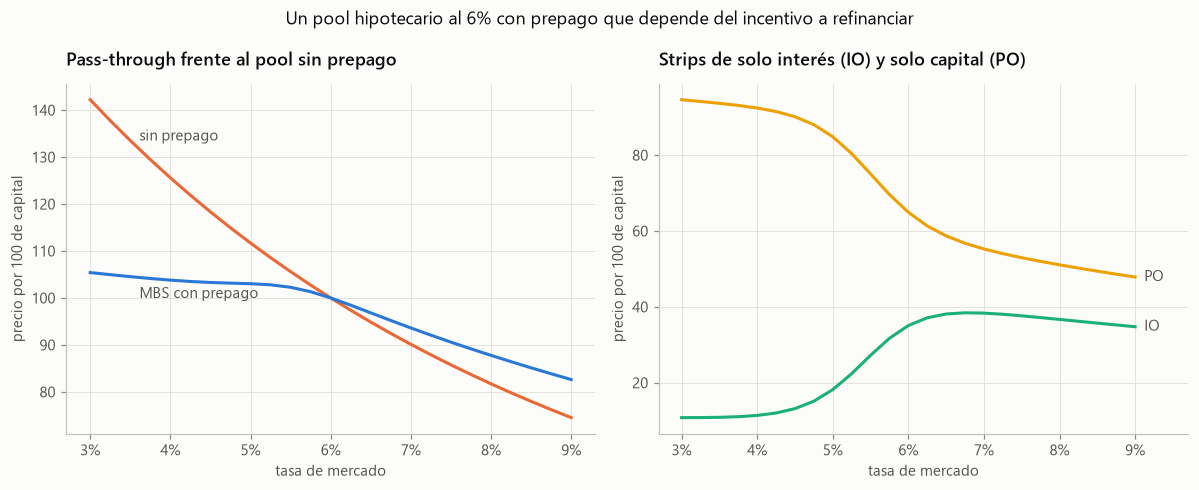

,CPR,MBS,IO,PO,sin prepago
tasa,,,,,
0.0300,0.4080,105.4000,10.8010,94.6000,142.2070
0.0400,0.3830,103.7930,11.3800,92.4140,125.5830
0.0500,0.2350,103.0310,18.1850,84.8460,111.6850
0.0600,0.0870,100.0000,35.0700,64.9300,100.0000
0.0700,0.0620,93.6090,38.3480,55.2610,90.1170
0.0800,0.0600,87.7700,36.6900,51.0810,81.7090
0.0900,0.0600,82.6180,34.7630,47.8550,74.5130


In [53]:
def cpr_refinanciamiento(tasa_mercado, tasa_pool=0.06):
    return 0.06 + 0.35 / (1 + np.exp(-(tasa_pool - tasa_mercado - 0.01) / 0.004))

def valorar_pool(tasa_mercado, cpr):
    flujos = frm.flujos_hipoteca(100.0, 0.06, 360, cpr)
    descuento = (1 + tasa_mercado / 12) ** -flujos["mes"].to_numpy()
    return {"MBS": float(flujos["flujo_total"] @ descuento), "IO": float(flujos["interes"] @ descuento),
            "PO": float((flujos["amortizacion"] + flujos["prepago"]) @ descuento)}

tasas_mercado = np.arange(0.03, 0.0901, 0.0025)
filas = []
for tasa in tasas_mercado:
    con_prepago = valorar_pool(tasa, cpr_refinanciamiento(tasa))
    filas.append({"tasa": tasa, "CPR": cpr_refinanciamiento(tasa), **con_prepago, "sin prepago": valorar_pool(tasa, 0.0)["MBS"]})
tabla_mbs = pd.DataFrame(filas).set_index("tasa")

def duracion_convexidad_efectiva(columna, tasa0=0.06, paso=0.0025):
    precios_ = tabla_mbs[columna]
    p0, pa, pb = precios_.loc[np.isclose(precios_.index, tasa0)].iloc[0], precios_.loc[np.isclose(precios_.index, tasa0 + paso)].iloc[0], precios_.loc[np.isclose(precios_.index, tasa0 - paso)].iloc[0]
    return (pb - pa) / (2 * p0 * paso), (pa + pb - 2 * p0) / (p0 * paso**2)

for columna in ("MBS", "sin prepago", "IO", "PO"):
    dur, conv = duracion_convexidad_efectiva(columna)
    print(f"{columna:<12} duración efectiva {dur:6.2f}; convexidad efectiva {conv:8.1f}")

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
ejes[0].plot(tabla_mbs.index, tabla_mbs["sin prepago"], color=COLORES[1], linewidth=2)
ejes[0].plot(tabla_mbs.index, tabla_mbs["MBS"], color=COLORES[0], linewidth=2)
ejes[0].annotate("sin prepago", (0.035, tabla_mbs["sin prepago"].iloc[2]), xytext=(6, 0), textcoords="offset points", color=TINTA_SECUNDARIA)
ejes[0].annotate("MBS con prepago", (0.035, tabla_mbs["MBS"].iloc[2]), xytext=(6, -14), textcoords="offset points", color=TINTA_SECUNDARIA)
ejes[0].set_title("Pass-through frente al pool sin prepago")
for color, columna in zip((COLORES[2], COLORES[3]), ("IO", "PO")):
    ejes[1].plot(tabla_mbs.index, tabla_mbs[columna], color=color, linewidth=2)
    ejes[1].annotate(columna, (0.09, tabla_mbs[columna].iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center", color=TINTA_SECUNDARIA)
ejes[1].set_title("Strips de solo interés (IO) y solo capital (PO)")
ejes[1].set_xlim(0.027, 0.097)
for ax in ejes:
    eje_porcentaje(ax, "x")
    ax.set_xlabel("tasa de mercado")
    ax.set_ylabel("precio por 100 de capital")
fig.suptitle("Un pool hipotecario al 6% con prepago que depende del incentivo a refinanciar")
fig.tight_layout()
fig.savefig(FIGURAS / "mbs_convexidad.png", bbox_inches="tight")
plt.show()
tabla_mbs.iloc[::4].round(3)

**Lectura.**

- **El prepago crea convexidad negativa.** Con tasas de mercado de 3%, el pool sin prepago valdría 142, pero el MBS solo 105, porque los deudores refinancian. Alrededor de 6%, la convexidad efectiva del MBS es −360, frente a +180 del pool sin prepago.
- **El IO tiene duración negativa, de −31:** gana valor cuando suben las tasas, porque se prepaga menos y los intereses duran más. El PO tiene duración de +25 y convexidad muy positiva.
- **Por eso los IO sirven para cubrir carteras de MBS,** y los inversionistas en MBS exigen un spread mayor que el de un bono del mismo plazo: le venden al deudor una opción de prepago.

### Ejercicios resueltos

**Ejercicio 18.1. Cuota y tabla de amortización** *(caso de prueba de los motores de cálculo de frm-prep)*

Un crédito hipotecario de 200.000 a 30 años con tasa de 6% anual tiene pagos mensuales. Calcula la cuota con la función de la calculadora BA II Plus portada de frm-prep, y muestra cuánto del primer y del último pago es interés.

In [54]:
cuota_ej = fa.cuota(360, 0.005, 200_000)
tabla_amort = fa.tabla_amortizacion(200_000, 0.005, 360)
print(f"Cuota: {abs(cuota_ej):,.2f} (la función devuelve {cuota_ej:,.2f}, con signo opuesto al préstamo)")
print(tabla_amort.iloc[[0, 1, 179, 358, 359]].round(2).to_string(index=False))
print(f"Respuesta: el primer pago tiene {tabla_amort['interes'].iloc[0]:,.2f} de interés; el último, {tabla_amort['interes'].iloc[-1]:,.2f}. En total se pagan {tabla_amort['interes'].sum():,.0f} de intereses.")

Cuota: 1,199.10 (la función devuelve -1,199.10, con signo opuesto al préstamo)
 periodo      cuota    interes  amortizacion        saldo
       1 1,199.1000 1,000.0000      199.1000 199,800.9000
       2 1,199.1000   999.0000      200.1000 199,600.8000
     180 1,199.1000   712.9200      486.1800 142,097.6900
     359 1,199.1000    11.9000    1,187.2000   1,193.1400
     360 1,199.1000     5.9700    1,193.1400       0.0000
Respuesta: el primer pago tiene 1,000.00 de interés; el último, 5.97. En total se pagan 231,676 de intereses.


**Ejercicio 18.2. Prepago con el modelo PSA** *(ejercicio propio)*

Un pool tiene un saldo de 50 millones en el mes 15 y la amortización programada de ese mes es 60.000. ¿Cuál es el SMM con una velocidad de 150 PSA y cuánto se prepaga?

In [55]:
smm = float(fa.smm_psa(15, 150))
cpr = 0.002 * 15 * 1.5
prepago = smm * (50_000_000 - 60_000)
print(f"CPR = 0,2% × 15 × 1,5 = {cpr:.2%}; SMM = 1 - (1 - {cpr:.3f})^(1/12) = {smm:.4%}")
print(f"Respuesta: prepago = SMM × (saldo - amortización programada) = {prepago:,.0f}")

CPR = 0,2% × 15 × 1,5 = 4.50%; SMM = 1 - (1 - 0.045)^(1/12) = 0.3830%
Respuesta: prepago = SMM × (saldo - amortización programada) = 191,252


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, conceptual, dificultad avanzada)*

Los bonos hipotecarios (MBS) muestran convexidad negativa principalmente porque:

- **A.** sus cupones suben cuando bajan las tasas.
- **B.** no tienen opción de prepago.
- **C.** están libres de default.
- **D.** la opción de prepago del deudor limita la apreciación de precio cuando bajan las tasas, así el MBS gana menos ante bajas de tasa que lo que pierde ante subas.

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** Los deudores pueden prepagar (una opción tipo call que ellos tienen). Cuando las tasas bajan, los prepagos se aceleran y la apreciación del MBS queda limitada cerca de la par — como un bono callable. Esto produce convexidad negativa: el precio sube menos ante una baja de tasa que lo que cae ante una suba igual.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

Una obligación hipotecaria colateralizada (CMO) principalmente:

- **A.** elimina todo el riesgo de crédito de los préstamos subyacentes.
- **B.** convierte las hipotecas en acciones.
- **C.** elimina el riesgo de prepago para todos los inversores.
- **D.** redistribuye el riesgo de prepago entre tramos para que distintos inversores asuman distintas cantidades.

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** Una CMO divide los flujos de un pool hipotecario en tramos con distintas prioridades. Los prepagos se dirigen a los tramos en un orden definido, de modo que algunos quedan protegidos del riesgo de prepago (o extensión) mientras otros absorben más. Reasigna, no elimina, el riesgo.

</details>

### Trampas frecuentes

- El IO pierde valor cuando bajan las tasas: puede tener duración negativa.
- El SMM se aplica al saldo después de la amortización programada del mes.
- Una CMO reparte el riesgo de prepago; no lo elimina.

## FMP-19. Futuros de tasas de interés

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Conteo de días.** Actual/actual para bonos del Tesoro de EE.UU., 30/360 para bonos corporativos y actual/360 para instrumentos del mercado monetario.
- **Cotizaciones.** Las letras del Tesoro se cotizan como tasa de descuento; los bonos, en precio limpio, sin intereses devengados. El comprador paga el precio sucio: limpio más devengado.
- **Futuros sobre bonos del Tesoro.** El vendedor elige qué bono entregar de una canasta. Recibe el precio del futuro por el factor de conversión más el devengado. Entrega el bono más barato (CTD), el que minimiza el precio cotizado menos el precio del futuro por el factor de conversión.
- **Futuros sobre tasas cortas.** Eurodólar y SOFR a tres meses: precio 100 menos la tasa; un punto base vale 25 dólares por contrato. Por la liquidación diaria, la tasa del futuro es mayor que la forward: ajuste de convexidad, $\frac{1}{2}\sigma^2 t_1 t_2$ en el modelo de Ho-Lee.
- **Cobertura por duración.** $N^* = -\frac{P\,D_P}{F_C\,D_F}$ contratos para llevar la duración de la cartera a cero.

### Análisis avanzado: el bono más barato de entregar

Una canasta de cinco bonos entregables, con distintos cupones y plazos, y factores de conversión calculados como el precio de cada bono con un rendimiento de 6%. Para cada nivel de tasas, el CTD es el bono con menor precio cotizado sobre factor de conversión. Se ignoran los intereses devengados, el costo de mantener el bono y el valor de las opciones de entrega.

              cupón   plazo  factor de conversión  duración modificada al 6%
8% a 15 años 0.0800 15.0000                1.1960                     9.2533
7% a 18 años 0.0700 18.0000                1.1092                    10.5760
6% a 20 años 0.0600 20.0000                1.0000                    11.5574
5% a 22 años 0.0500 22.0000                0.8787                    12.6041
4% a 25 años 0.0400 25.0000                0.7427                    14.0327

CTD según el rendimiento:
  desde 3.00%: 8% a 15 años
  desde 6.25%: 4% a 25 años


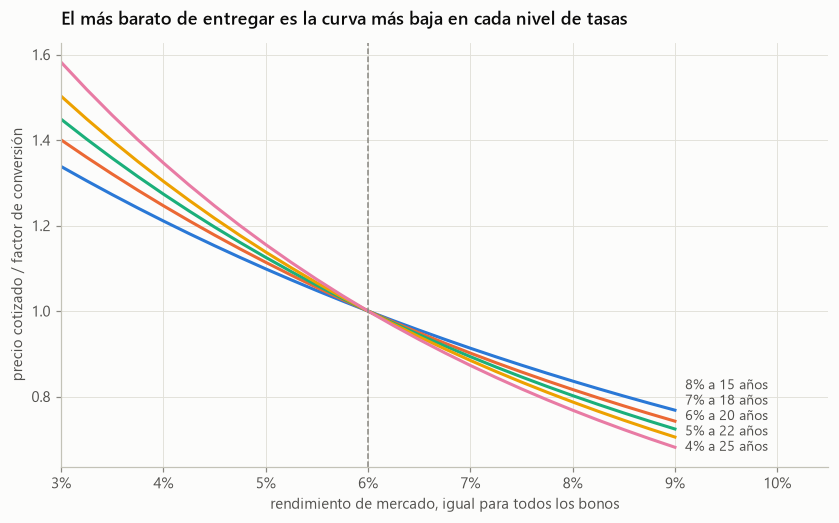

,"ajuste de convexidad, puntos base"
"vencimiento del futuro, años",
1,0.9000
2,3.2000
5,18.9000
8,47.5000
10,73.8000


In [56]:
canasta = pd.DataFrame({"cupón": [0.08, 0.07, 0.06, 0.05, 0.04], "plazo": [15.0, 18.0, 20.0, 22.0, 25.0]},
                       index=["8% a 15 años", "7% a 18 años", "6% a 20 años", "5% a 22 años", "4% a 25 años"])
canasta["factor de conversión"] = [fa.precio_bono(c, 0.06, t, 2) / 100 for c, t in zip(canasta["cupón"], canasta["plazo"])]
canasta["duración modificada al 6%"] = [fa.metricas_bono(c, 0.06, t, 2)["modificada"] for c, t in zip(canasta["cupón"], canasta["plazo"])]
rendimientos = np.arange(0.03, 0.0901, 0.0025)
cociente = pd.DataFrame({nombre: [fa.precio_bono(c, y, t, 2) / (100 * fc) for y in rendimientos]
                         for nombre, (c, t, fc, _) in canasta.iterrows()}, index=rendimientos)
ctd = cociente.idxmin(axis=1)
cambios_ctd = ctd[ctd != ctd.shift()]
print(canasta.round(4).to_string())
print("\nCTD según el rendimiento:")
for y, nombre in cambios_ctd.items():
    print(f"  desde {y:.2%}: {nombre}")

fig, ax = plt.subplots(figsize=(9, 5))
posiciones_ctd = separar_etiquetas({n: cociente[n].iloc[-1] for n in canasta.index}, 0.036)
for color, nombre in zip(COLORES, canasta.index):
    ax.plot(rendimientos, cociente[nombre], color=color, linewidth=2)
    ax.annotate(nombre, (rendimientos[-1] + 0.001, posiciones_ctd[nombre]), va="center", color=TINTA_SECUNDARIA, fontsize=9)
ax.axvline(0.06, color=TINTA_TENUE, linestyle="--", linewidth=1)
eje_porcentaje(ax, "x")
ax.set_xlim(0.03, 0.105)
ax.set_xlabel("rendimiento de mercado, igual para todos los bonos")
ax.set_ylabel("precio cotizado / factor de conversión")
ax.set_title("El más barato de entregar es la curva más baja en cada nivel de tasas")
plt.show()

ajustes = pd.Series({t1: 1e4 * fa.ajuste_convexidad(0.012, t1, t1 + 0.25) for t1 in (1, 2, 5, 8, 10)},
                    name="ajuste de convexidad, puntos base").rename_axis("vencimiento del futuro, años")
ajustes.round(1).to_frame()

**Lectura.**

- **A 6% los cinco bonos cuestan lo mismo,** porque los factores de conversión se calculan con ese rendimiento. Bajo 6%, el más barato de entregar es el de 8% a 15 años, el de menor duración; sobre 6%, el de 4% a 25 años, el de mayor duración.
- **Cuando cambia el CTD, cambia la duración del futuro.** La cobertura con futuros de bonos tiene su propia convexidad, y la opción de elegir el bono, que es del vendedor, abarata el futuro.
- **El ajuste de convexidad crece con el cuadrado del plazo:** es menos de 1 punto base a un año y llega a 74 puntos base a 10 años.

### Ejercicios resueltos

**Ejercicio 19.1. Conteo de días e intereses devengados** *(ejercicio propio)*

Un bono con cupón semestral de 6% sobre 100 pagó su último cupón el 1 de marzo de 2026 y el próximo es el 1 de septiembre de 2026. Calcula los intereses devengados al 20 de julio de 2026 con las convenciones actual/actual y 30/360. Si el precio limpio es 98,50, ¿cuál es el precio sucio con actual/actual?

In [57]:
dias_act = (pd.Timestamp("2026-07-20") - pd.Timestamp("2026-03-01")).days
dias_periodo = (pd.Timestamp("2026-09-01") - pd.Timestamp("2026-03-01")).days
devengado_act = 3 * dias_act / dias_periodo
devengado_30 = 3 * fa.fraccion_anio("2026-03-01", "2026-07-20", "30/360") / 0.5
print(f"Actual/actual: 3 × {dias_act}/{dias_periodo} = {devengado_act:.4f}; 30/360: 3 × {fa.fraccion_anio('2026-03-01', '2026-07-20', '30/360') * 360:.0f}/180 = {devengado_30:.4f}")
print(f"Respuesta: precio sucio = 98,50 + {devengado_act:.4f} = {98.5 + devengado_act:.4f}")

Actual/actual: 3 × 141/184 = 2.2989; 30/360: 3 × 139/180 = 2.3167
Respuesta: precio sucio = 98,50 + 2.2989 = 100.7989


**Ejercicio 19.2. Cobertura por duración, precio de factura y ajuste de convexidad** *(ejercicio propio)*

Una cartera de 10 millones con duración de 6,8 años se cubre con futuros sobre bonos cuyo precio es 93.062,50 por contrato y cuyo CTD tiene duración de 9,2 años: ¿cuántos contratos? Si el futuro liquida a 101 y el bono entregado tiene factor de conversión 0,95 y devengado de 1,40, ¿cuánto paga el comprador por 100 de nominal? Finalmente, con σ = 1,2%, ¿cuál es el ajuste de convexidad de un futuro a 8 años sobre una tasa a 3 meses?

In [58]:
n = fa.contratos_duracion(10_000_000, 6.8, 93_062.50, 9.2)
print(f"N* = 10.000.000 × 6,8 / (93.062,50 × 9,2) = {abs(n):.2f}: vender unos {abs(n):.0f} contratos")
print(f"Precio de factura = 101 × 0,95 + 1,40 = {101 * 0.95 + 1.40:.2f}")
print(f"Respuesta: ajuste de convexidad = ½ × 0,012² × 8 × 8,25 = {fa.ajuste_convexidad(0.012, 8, 8.25):.4%}, unos 47,5 puntos base.")

N* = 10.000.000 × 6,8 / (93.062,50 × 9,2) = 79.42: vender unos 79 contratos
Precio de factura = 101 × 0,95 + 1,40 = 97.35
Respuesta: ajuste de convexidad = ½ × 0,012² × 8 × 8,25 = 0.4752%, unos 47,5 puntos base.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad intermedia)*

Un futuro de bono del Tesoro liquida a 98 (por 100 de nominal). El bono entregado tiene un factor de conversión de 1.05 e interés devengado de \$1.20 (por 100). El precio de factura que recibe el vendedor es más cercano a (por 100 de nominal):

- **A.** $99.20
- **B.** $104.10
- **C.** $102.90
- **D.** $103.05

<details>
<summary>Ver respuesta</summary>

**Respuesta: B.** Precio de factura $= (\text{liquidación del futuro} \times \text{factor de conversión}) + \text{interés devengado} = (98 \times 1.05) + 1.20 = 102.90 + 1.20 = \$104.10$.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad intermedia)*

El bono cheapest-to-deliver (CTD) en un futuro del Tesoro es el bono elegible que:

- **A.** minimiza el costo de comprar el bono en el mercado menos el precio de factura recibido en la entrega.
- **B.** tiene el vencimiento más largo disponible.
- **C.** siempre tiene el cupón más alto.
- **D.** lo elige al azar la bolsa.

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** El vendedor elige qué bono elegible entregar. El CTD es el que maximiza el beneficio de entrega — equivalentemente, minimiza (precio cotizado del bono − precio del futuro × factor de conversión). El nivel de tasas y la forma de la curva determinan cuál es el más barato de entregar.

</details>

### Trampas frecuentes

- El CTD minimiza el precio cotizado menos el futuro por el factor de conversión; no es simplemente el bono más barato.
- Con tasas bajo el 6% del factor de conversión, conviene entregar bonos de baja duración; sobre 6%, de alta duración.
- La tasa del futuro es mayor que la forward: el ajuste de convexidad se resta del futuro para obtener la forward.
- Un punto base en un futuro de eurodólar o SOFR a tres meses vale 25 dólares por contrato.

## FMP-20. Swaps

*Relevancia en el examen: alta. Dificultad: avanzada.*

### Idea central

- **Swap de tasas.** Una parte paga fijo y la otra flotante sobre un nocional que no se intercambia. Transforma deuda flotante en fija y viceversa.
- **Ventaja comparativa.** El argumento clásico dice que dos empresas ganan al intercambiar flujos; en realidad, la diferencia de spreads refleja que la deuda flotante corta permite al banco revisar el riesgo de crédito.
- **Valoración como bonos.** Para quien paga fijo, $V = B_{flotante} - B_{fijo}$. Justo después de un pago, el bono flotante vale su nominal.
- **Valoración como FRA.** El swap es una cartera de FRA: $V = \sum_i N\,\Delta t\,(f_i - c)\,d_i$, con las tasas forward de cada período. Ambos métodos dan exactamente lo mismo.
- **Swaps de monedas.** Intercambian principal e intereses en dos monedas: $V = B_{local} - S\,B_{extranjero}$ para quien recibe la moneda local.
- **Riesgo de crédito.** Solo el valor positivo del swap está en riesgo, y la exposición de un swap de monedas es mayor por el intercambio final de principal.

### Análisis avanzado: valor de un swap vivo con la curva chilena

Una empresa pactó hace dos años un swap a 5 años en pesos: paga la tasa fija de ese día y recibe la flotante, sobre 10.000 millones con pagos semestrales. Le quedan 3 años. Se valora justo después de un pago con la curva cero de FMP-16, como diferencia de bonos y como cartera de FRA, y se calcula su DV01 desplazando las tasas par un punto base.

In [59]:
nocional_swap = 10_000.0
fecha_pacto = swap.loc[:fecha_curva - pd.DateOffset(years=2)].dropna().index[-1]
tasa_pactada = float(swap.loc[fecha_pacto, "5"]) / 100
n_pagos = 6
d = factores[:n_pagos]
bono_fijo = nocional_swap * (tasa_pactada / 2 * d.sum() + d[-1])
valor_bonos = nocional_swap - bono_fijo
valor_fra = float(np.sum(nocional_swap * 0.5 * (forwards[:n_pagos] - tasa_pactada) * d))
tasa_par_3a = 2 * (1 - d[-1]) / d.sum()

factores_arriba = fa.bootstrap_par(plazos_curva, par_rejilla + 0.0001, 2,
                                   factores_conocidos=[1 / (1 + (tasas_swap["0.5"] + 0.0001) * 0.5 * 365 / 360),
                                                       1 / (1 + (tasas_swap["1"] + 0.0001) * 365 / 360)])
valor_arriba = nocional_swap - nocional_swap * (tasa_pactada / 2 * factores_arriba[:n_pagos].sum() + factores_arriba[n_pagos - 1])
print(f"Pactado el {fecha_pacto:%d-%m-%Y} a {tasa_pactada:.3%}; hoy la tasa par a 3 años es {tasa_par_3a:.3%}")
print(f"Valor para quien paga fijo, como bonos: {valor_bonos:,.2f} millones; como cartera de FRA: {valor_fra:,.2f} millones")
print(f"DV01: {valor_arriba - valor_bonos:,.3f} millones por punto base de alza en toda la curva")
pd.DataFrame({"plazo": plazos_curva[:n_pagos], "factor de descuento": d, "forward": forwards[:n_pagos],
              "flujo neto esperado": nocional_swap * 0.5 * (forwards[:n_pagos] - tasa_pactada),
              "valor presente": nocional_swap * 0.5 * (forwards[:n_pagos] - tasa_pactada) * d}).round(4)

Pactado el 23-09-2024 a 4.422%; hoy la tasa par a 3 años es 5.315%
Valor para quien paga fijo, como bonos: 245.34 millones; como cartera de FRA: 245.34 millones
DV01: 2.706 millones por punto base de alza en toda la curva


,plazo,factor de descuento,forward,flujo neto esperado,valor presente
0,0.5000,0.9773,0.0465,11.4562,11.1958
1,1.0000,0.9537,0.0494,25.6675,24.4801
2,1.5000,0.9290,0.0533,45.4763,42.2464
3,2.0000,0.9032,0.0570,63.7864,57.6146
4,2.5000,0.8787,0.0560,58.7964,51.6615
5,3.0000,0.8540,0.0578,68.0793,58.1367


**Lectura.**

- **El swap se pactó en septiembre de 2024 a 4,42%, y hoy la tasa par a 3 años es 5,32%.** Quien paga fijo paga menos que el mercado: su posición vale 245 millones de pesos, 2,5% del nocional.
- **Como bonos y como cartera de FRA, el valor es idéntico:** son dos formas de escribir los mismos flujos.
- **El DV01 es 2,7 millones por punto base:** si toda la curva sube un punto base, quien paga fijo gana 2,7 millones. Una cartera de swaps se cubre por tramos con DV01 parciales, como en el libro 4.

### Ejercicios resueltos

**Ejercicio 20.1. Valor de un swap por bonos y por FRA** *(ejercicio propio)*

A un swap le quedan 2 años, con pagos anuales sobre 100 millones; quien paga fijo paga 4%. Las tasas cero continuas a 1 y 2 años son 4,5% y 5%. La flotante acaba de fijarse, así que el bono flotante vale 100. Valora el swap para quien paga fijo con ambos métodos.

In [60]:
plazos_ej = np.array([1.0, 2.0])
ceros_ej = np.array([0.045, 0.05])
d_ej = np.exp(-ceros_ej * plazos_ej)
v_bonos = frm.valor_swap_tasa(100, 0.04, plazos_ej, ceros_ej, frecuencia=1)
fwd_ej = np.array([np.exp(0.045) - 1, d_ej[0] / d_ej[1] - 1])
v_fra = float(np.sum(100 * (fwd_ej - 0.04) * d_ej))
print(f"Como bonos: 100 - (4·e^(-0,045) + 104·e^(-0,10)) = {v_bonos:.4f}")
print(f"Respuesta: como FRA, Σ 100·(f_i - 4%)·d_i = {v_fra:.4f}. Coinciden: pagar 4% fijo con tasas de mercado cercanas a 5% es favorable.")

Como bonos: 100 - (4·e^(-0,045) + 104·e^(-0,10)) = 2.0729
Respuesta: como FRA, Σ 100·(f_i - 4%)·d_i = 2.0729. Coinciden: pagar 4% fijo con tasas de mercado cercanas a 5% es favorable.


**Ejercicio 20.2. Ventaja comparativa y swap de monedas** *(ejercicio propio)*

La empresa A se financia al 4,0% fijo o a SOFR + 0,3%; la empresa B, al 5,2% fijo o a SOFR + 1,0%. ¿Cuánto ganan entre ambas con un swap? Luego, un swap de monedas a 2 años recibe 5% anual en pesos sobre 9.500 millones y paga 4% anual en dólares sobre 10 millones. Con tasas cero de 5,5% en pesos y 4,5% en dólares, ambas continuas y planas, y un dólar de 960, ¿cuánto vale?

In [61]:
ganancia = (5.2 - 4.0) - (1.0 - 0.3)
print(f"Ganancia total = (5,2% - 4,0%) - (1,0% - 0,3%) = {ganancia:.1f}%, a repartir entre A, B y el banco")
b_clp = 9_500 * (0.05 * np.exp(-0.055) + 1.05 * np.exp(-0.055 * 2))
b_usd = 10 * (0.04 * np.exp(-0.045) + 1.04 * np.exp(-0.045 * 2))
print(f"Bono en pesos {b_clp:,.1f} millones; bono en dólares {b_usd:.4f} millones = {960 * b_usd:,.1f} millones de pesos")
print(f"Respuesta: valor para quien recibe pesos = {b_clp - 960 * b_usd:,.1f} millones de pesos.")

Ganancia total = (5,2% - 4,0%) - (1,0% - 0,3%) = 0.5%, a repartir entre A, B y el banco
Bono en pesos 9,385.5 millones; bono en dólares 9.8873 millones = 9,491.8 millones de pesos
Respuesta: valor para quien recibe pesos = -106.3 millones de pesos.


### Preguntas de práctica

**Pregunta 1** *(banco de frm-prep, cálculo, dificultad avanzada)*

Justo después de un pago, a un swap le queda 1 año y paga 5% fijo anual sobre \$100 de nocional contra flotante. Justo tras el reset, el valor de la pata flotante es la par (\$100). Si la tasa de descuento es 6%, el valor para quien paga fijo es más cercano a (por \$100):

- **A.** $5.00
- **B.** $1.06
- **C.** -$0.94
- **D.** $0.94

<details>
<summary>Ver respuesta</summary>

**Respuesta: D.** Valor para el pagador fijo $= B_{flotante} - B_{fijo}$. $B_{flotante} = 100$. $B_{fijo} = \dfrac{105}{1.06} = 99.06$. Valor $= 100 - 99.06 = \$0.94$: pagar fijo por debajo del mercado (5% vs 6%) es favorable.

</details>

**Pregunta 2** *(banco de frm-prep, conceptual, dificultad avanzada)*

¿Qué distingue mejor un cross-currency basis swap de un FX swap de corto plazo?

- **A.** Un cross-currency basis swap intercambia flujos de pagos de interés en dos monedas a lo largo del tiempo (y reintercambia el principal al vencimiento), mientras que un FX swap es un intercambio spot combinado con un único forward que lo compensa.
- **B.** Son idénticos en flujos y vencimiento.
- **C.** Un FX swap siempre tiene mayor vencimiento que un cross-currency swap.
- **D.** Un cross-currency basis swap involucra una sola moneda.

<details>
<summary>Ver respuesta</summary>

**Respuesta: A.** Un FX swap es una pata spot más una pata forward que la compensa (se usa sobre todo para fondeo/rollover de corto plazo). Un cross-currency basis swap corre en un horizonte más largo, intercambiando interés periódico en cada moneda (la base es el spread de la pata flotante) y reintercambiando el principal al vencimiento.

</details>

### Trampas frecuentes

- Justo después de un pago, el bono flotante vale su nominal; entre pagos, vale el nominal más el cupón ya fijado, descontado.
- Valorar como bonos o como FRA da el mismo resultado si se usan las mismas tasas.
- El argumento de la ventaja comparativa ignora el riesgo de crédito que el banco puede revisar en la deuda flotante.
- En un swap de monedas se intercambia el principal al inicio y al final; en uno de tasas, no.

## Resumen del libro

- **Los derivados se valoran por replicación y arbitraje,** no por expectativas: el forward no pronostica el dólar, y la paridad descubierta falla en los datos chilenos.
- **El riesgo de liquidez acompaña a las coberturas.** Los llamados de margen, los márgenes procíclicos de las cámaras y la exposición del período de riesgo de margen aparecen incluso cuando la cobertura funciona en valor.
- **La opcionalidad está en todas partes:** en las comisiones de los fondos, en los warrants y convertibles, en el prepago de las hipotecas, en la entrega de los futuros de bonos y en las barreras de las exóticas.
- **La curva de tasas es la base de casi todo:** bonos, FRA, swaps y futuros se valoran con los mismos factores de descuento, construidos por bootstrapping.